<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-10/lab-054-quantum-state-preparation.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 054 <br>
<hr/>

# Lab 054 — Quantum state preparation

A quantum experiment often starts by preparing a particular quantum state, and the experimentalist can only switch fields and couplings on and off. Finding the sequence of fields that brings a simple initial state to a desired target state is a control problem. Reinforcement learning treats it as a game in which an agent chooses the next field or the next pulse, the laws of quantum mechanics produce the next state, and the agent is rewarded with the overlap between the reached state and the target.

We follow two works. M. Bukov, A. G. R. Day, D. Sels, P. Weinberg, A. Polkovnikov and P. Mehta, *Reinforcement Learning in Different Phases of Quantum Control*, Phys. Rev. X **8**, 031086 (2018), [doi:10.1103/PhysRevX.8.031086](https://doi.org/10.1103/PhysRevX.8.031086), [arXiv:1705.00565](https://arxiv.org/abs/1705.00565), control a single spin with a magnetic field that can only be switched between two values, and find that the difficulty of the task changes abruptly with the available time, in a way that resembles phase transitions. F. Metz and M. Bukov, *Self-correcting quantum many-body control using reinforcement learning with tensor networks*, Nat. Mach. Intell. **5**, 780 (2023), [doi:10.1038/s42256-023-00687-5](https://doi.org/10.1038/s42256-023-00687-5), [arXiv:2201.11790](https://arxiv.org/abs/2201.11790), prepare ground states of interacting spin chains with a deep Q-network that sees the quantum state and therefore reacts when something goes wrong during the protocol.

In both works the actions are time evolutions under Hamiltonians that an experiment can switch on. In the first part we introduce a spin in a magnetic field, its motion on the Bloch sphere and the control problem of Bukov et al., in which the agent decides at each time step whether the field is $+4$ or $-4$. Because the protocols are short sequences of two field values, we can enumerate all of them and know the best protocol at every protocol duration. Tabular Q-learning, which is sufficient for a single spin with twenty time steps, is then compared with this exact answer. The chain of coupled spins of the same paper shows how the best achievable fidelity changes when one field drives many spins.

In the second part we introduce the transverse-field Ising chain and a non-integrable Ising chain, compute their ground states by exact diagonalisation and explain why Metz and Bukov store states as matrix product states. Preparing such a ground state is hard because it is an entangled state of many spins, while the experiment starts from a simple product state and can only apply a few global operations. Two double deep Q-networks, neural networks that estimate the action values from the quantum state, then prepare these ground states for chains of four and six spins from the all-up state by short evolutions under single Hamiltonian terms. The first agent uses coarse steps and the second one finer steps, the two-agent scheme of Metz and Bukov. We test how the trained agents react to perturbed initial states, to wrong actions inserted in the middle of a protocol and to noisy pulses, and compare them with a fixed pulse sequence. We finish with a comparison of this analog control with gate-based control of the same ground states.

The methods are those of the two papers, and the credit for them belongs to their authors. This notebook is a small-scale reimplementation for teaching. It follows the control problems of Bukov et al. (Phys. Rev. X **8**, 031086 (2018)) and the agent design of Metz and Bukov (Nat. Mach. Intell. **5**, 780 (2023), arXiv:2201.11790) with exact state vectors of chains of four and six spins, where Metz and Bukov use matrix product states for long chains. The differences from the papers are listed in the sections that use them.

The quantum states are simulated without building any $2^N\times 2^N$ matrix for the dynamics. A state of $N$ spins is stored as a tensor with $N$ indices of size two, and every gate or local Hamiltonian term acts on it by one `einsum`. The functions that do this are copied from the SmoQ.jax engine. Dense matrices of size up to $64\times64$ appear only in the reference calculations, the exact diagonalisation and the reference propagator, and are labelled as such.

## Student route through the spin-chain study
The main lecture uses the many-spin implementation. Begin at **Control by evolution under Hamiltonian terms**, after studying the target Hamiltonian, ground states and available generators. Continue through the coarse and fine agents, learned fidelity curves and nominal protocols. Stop at the end of the subsection **Learned protocols**, before **Self-correction**. The earlier single-spin control studies and later robustness scans remain optional complete experiments.

The simulator provides full quantum-state information. Robustness measured with that input describes that access model. Analog and digital comparisons require matched target vectors and stated resources. The longitudinal-field targets in the two full studies differ by a spin rotation, as documented in data/TARGETS_SPEC.md.

> **Running this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> and choose *File, Upload notebook*. The first code cell sets `JAX_PLATFORMS=cpu`.
> 2. `jax`, `optax` and `matplotlib` are pre-installed in Colab. The comparison with gate-based control at the end reads the stored results of the circuit compilation notebook, and without them that comparison is skipped.
> 3. The recorded run of the whole notebook took about 7 minutes on a multi-core CPU that was shared with other jobs. Most of the time goes to the training of the deep Q-networks.
> 4. Run the cells in order. Later cells use variables defined earlier.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['lab054_fig_analog_vs_gates.npz', 'lab054_fig_learning.npz', 'lab054_fig_protocol.npz', 'lab054_fig_robust.npz']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-10/data/{name}", f"data/{name}")

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import time, json, string, warnings
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D, proj3d  # noqa: F401  (registers the 3D projection)
import jax, jax.numpy as jnp
from jax import lax
import optax

t_start = time.time()
warnings.filterwarnings("ignore", message="This figure includes Axes that are not compatible with tight_layout")
# figures are drawn at their printed size on a slide (5.5 in wide), so these are the true font sizes
mpl.rcParams.update({"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
                     "ytick.labelsize": 11, "legend.fontsize": 11, "figure.titlesize": 12, "lines.linewidth": 1.6,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
                     "figure.dpi": 110})
UJNavy, UJBlue, UJSky, DSOrange, UJGray, UJGreen = "#002B5C", "#005CA7", "#3E8FD0", "#D35A05", "#5A6270", "#1a7f37"
os.makedirs("figures", exist_ok=True)
NUMBERS = {}

def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
print("jax", jax.__version__, "| optax", optax.__version__)

jax 0.11.0 | optax 0.2.6


## Quantum engine

The next cell contains the functions of the SmoQ.jax engine that this notebook uses, copied without changes. Their conventions are those of the engine. Qubit 0 is the leftmost factor of a tensor product, $|0\rangle=(1,0)^T$ is spin up along $z$, and a two-qubit rotation is $\exp(-i\theta PP/2)$.

In [2]:
# Quantum engine: functions copied from SmoQ.jax, https://github.com/MarcinPlodzien/SmoQ.jax (M. Płodzień)
import string
import numpy as np
import jax
import jax.numpy as jnp
from jax import lax

PRECISION = "double"
jax.config.update("jax_enable_x64", PRECISION == "double")
RDTYPE = jnp.float64 if PRECISION == "double" else jnp.float32       # real dtype
CDTYPE = jnp.complex128 if PRECISION == "double" else jnp.complex64  # complex dtype of all states/operators
_LETTERS = string.ascii_letters
LAM_CUT = 100 * float(jnp.finfo(RDTYPE).eps)                           # Schmidt values below this are padding

# Basis convention: |0> = (1,0)^T is the +1 eigenstate of Z ("spin up"), |1> = (0,1)^T.
I2 = jnp.eye(2, dtype=CDTYPE)
X = jnp.array([[0, 1], [1, 0]], dtype=CDTYPE)
Y = jnp.array([[0, -1j], [1j, 0]], dtype=CDTYPE)
Z = jnp.array([[1, 0], [0, -1]], dtype=CDTYPE)
XX = jnp.kron(X, X)
YY = jnp.kron(Y, Y)
ZZ = jnp.kron(Z, Z)


def rx(theta):
    """Rotation about x:  Rx(theta) = exp(-i theta X/2) = cos(theta/2) 1 - i sin(theta/2) X.

    Derivation: for any operator with P^2 = 1 the exponential series splits into even/odd
    parts,  exp(-i a P) = cos(a) 1 - i sin(a) P.   Here a = theta/2.
    `theta` may be a traced JAX scalar, so the gate is differentiable (jax.grad) and jit-able.
    """
    c, s = jnp.cos(theta / 2), jnp.sin(theta / 2)
    return jnp.array([[c, -1j * s], [-1j * s, c]], dtype=CDTYPE)


def ry(theta):
    """Rotation about y:  Ry(theta) = exp(-i theta Y/2) = [[cos, -sin], [sin, cos]](theta/2)  (real matrix)."""
    c, s = jnp.cos(theta / 2), jnp.sin(theta / 2)
    return jnp.array([[c, -s], [s, c]], dtype=CDTYPE)


def rz(theta):
    """Rotation about z:  Rz(theta) = exp(-i theta Z/2) = diag(e^{-i theta/2}, e^{+i theta/2})."""
    e = jnp.exp(-0.5j * theta)
    return jnp.array([[e, 0], [0, jnp.conj(e)]], dtype=CDTYPE)


def rpp(theta, PP):
    """Two-qubit Pauli rotation  exp(-i theta PP/2)  for any product PP of two Pauli matrices (XX, YY, ZZ, XY, ...).

    Because (P x Q)^2 = 1 the same closed form as for single-qubit rotations holds:
        exp(-i theta PP/2) = cos(theta/2) 1_4 - i sin(theta/2) PP.
    These are the native entangling gates of trapped ions (XX) and the building blocks
    of Trotterised spin-chain evolution.
    """
    return jnp.cos(theta / 2) * jnp.eye(4, dtype=CDTYPE) - 1j * jnp.sin(theta / 2) * PP


def rxx(theta):
    """exp(-i theta X(x)X / 2)."""
    return rpp(theta, XX)


def ryy(theta):
    """exp(-i theta Y(x)Y / 2)."""
    return rpp(theta, YY)


def rzz(theta):
    """exp(-i theta Z(x)Z / 2)  -- diagonal: diag(e^{-i t/2}, e^{+i t/2}, e^{+i t/2}, e^{-i t/2})."""
    return rpp(theta, ZZ)


def apply_gate(psi, U, qubits):
    """Apply a k-qubit operator U to the axes `qubits` of the tensor `psi`.

    MATH
    ----
    One qubit (k=1), target q:
        psi'[s_0,..,a,..,s_{N-1}] = sum_b  U[a,b] psi[s_0,..,b,..,s_{N-1}]
    Two qubits (k=2), targets (q1,q2); the 4x4 matrix is reshaped to U[a1,a2,b1,b2]:
        psi'[.., a1, .., a2, ..] = sum_{b1,b2} U[a1,a2,b1,b2] psi[.., b1, .., b2, ..]
    This IS the action of (1 x .. x U x .. x 1) -- written without ever building it.

    EINSUM TRANSLATION  (generated automatically below)
    ------------------
        N=3, q=1        :  "db,abc->adc"          d = new (output) index of qubit 1
        N=4, q=(1,3)    :  "efbd,abcd->aecf"      e,f = new indices of qubits 1 and 3
    Recipe: label the axes of psi with letters a,b,c,...; give every target qubit a NEW
    letter (the next unused ones); U carries (new letters)+(old letters of the targets); the
    output is psi's labels with the target letters replaced by the new ones.

    IMPLEMENTATION NOTES
    --------------------
    * reshape of U:  (2^k,2^k) -> (2,)*2k.  Row index = (a1..ak), column = (b1..bk), and
      the FIRST qubit in `qubits` is the most significant bit of the small matrix, i.e. it
      corresponds to the LEFT factor of kron(A,B).
    * `qubits` may be any distinct axes in any order: non-neighbouring gates cost the same.
    * U need not be unitary: projectors, Kraus operators and Hamiltonian terms reuse this.
    * psi may be ANY tensor with those axes of size 2: a state (rank N), a density tensor
      (rank 2N: ket axes 0..N-1, bra axes N..2N-1), ...
    COST   O(2^k * 2^N) operations, O(2^N) memory  (dense matrix: O(4^N) both).
    JAX    `qubits` must be static Python ints (they define the einsum string); psi and U are
           traced, so the function can sit inside jit / grad / vmap / scan.
    """
    qubits = tuple(int(q) for q in qubits)
    k, n = len(qubits), psi.ndim
    U = jnp.asarray(U, dtype=psi.dtype).reshape((2,) * (2 * k))     # matrix -> rank-2k tensor
    inp = list(_LETTERS[:n])                                         # labels of psi's axes
    new = _LETTERS[n:n + k]                                          # fresh labels for the outputs
    out = inp.copy()
    for a, q in zip(new, qubits):
        out[q] = a                                                   # target axes get the new labels
    sub = f"{''.join(new)}{''.join(inp[q] for q in qubits)},{''.join(inp)}->{''.join(out)}"
    return jnp.einsum(sub, U, psi)


def apply_gates(psi, gates):
    """Apply a list [(qubits, U), ...] in order -- a quantum circuit is a Python loop over einsums.
    Under `jax.jit` the loop is unrolled at trace time and XLA fuses it into one program."""
    for qubits, U in gates:
        psi = apply_gate(psi, U, qubits)
    return psi


def zero_state(N):
    """|00...0>: a rank-N tensor of zeros with a single 1 at index (0,0,...,0).
    JAX arrays are immutable: `.at[idx].set(v)` returns an updated COPY (functional style)."""
    return jnp.zeros((2,) * N, dtype=CDTYPE).at[(0,) * N].set(1.0)


def haar_state(key, N):
    """Haar-random pure state: a complex Gaussian vector, normalised.
    (The Gaussian measure is unitarily invariant, so the direction is uniformly distributed.)
    `key` is an explicit JAX PRNG key -- same key, same state: reproducible science."""
    k1, k2 = jax.random.split(key)
    v = jax.random.normal(k1, (2,) * N) + 1j * jax.random.normal(k2, (2,) * N)
    return (v / jnp.linalg.norm(v)).astype(CDTYPE)


def fidelity_pure(psi, phi):
    """F = |<psi|phi>|^2 between two pure states."""
    return jnp.abs(jnp.vdot(psi, phi)) ** 2


def schmidt_values(psi, subsystem):
    """Schmidt coefficients of the bipartition A|B with A = `subsystem`.

    MATH   Group the tensor axes into a matrix  M[(a),(b)] = psi[a,b]  of shape (2^|A|, 2^|B|).
           Its SVD  M = U diag(lambda) V^dag  IS the Schmidt decomposition
               |psi> = sum_k lambda_k |u_k>_A |v_k>_B ,     rho_A has eigenvalues lambda_k^2.
    IMPLEMENTATION   transpose (A axes first) -> reshape -> svd.   No density matrix needed.
    """
    A = tuple(int(q) for q in subsystem)
    B = tuple(q for q in range(psi.ndim) if q not in A)
    M = jnp.transpose(psi, A + B).reshape(2 ** len(A), -1)
    return jnp.linalg.svd(M, compute_uv=False)


def entanglement_entropy(psi, subsystem, base=2.0):
    """Entanglement entropy S_A = -sum_k p_k log p_k with p_k = lambda_k^2 (squared Schmidt values).
    Product state: 0.  Bell/GHZ across any cut: 1 bit.  Random state: ~ |A| - 1/(2 ln2) 2^{|A|-|B|} (Page)."""
    p = jnp.clip(schmidt_values(psi, subsystem) ** 2, 1e-16, None)
    return -jnp.sum(p * jnp.log(p)) / jnp.log(base)


def heisenberg_terms(N, Jxx=1.0, Jyy=1.0, Jzz=1.0, hx=0.0, hy=0.0, hz=0.0, periodic=False, bonds=None):
    """Spin-1/2 Hamiltonian in Pauli convention
        H = sum_<ij> (Jxx X_i X_j + Jyy Y_i Y_j + Jzz Z_i Z_j) + sum_i (hx X_i + hy Y_i + hz Z_i)
    returned as a LIST of local terms [(qubits, small_matrix), ...]  -- this list *is* our Hamiltonian.
      Heisenberg: Jxx=Jyy=Jzz     XXZ: Jxx=Jyy!=Jzz     XY: Jzz=0     TFIM: only Jzz and hx.
    `bonds` overrides the default open chain (any graph: ladders, 2D lattices, all-to-all, ...)."""
    if bonds is None:
        bonds = [(i, i + 1) for i in range(N - 1)] + ([(N - 1, 0)] if periodic and N > 2 else [])
    terms = [((i, j), Jxx * XX + Jyy * YY + Jzz * ZZ) for (i, j) in bonds]
    if hx != 0 or hy != 0 or hz != 0:
        terms += [((i,), hx * X + hy * Y + hz * Z) for i in range(N)]
    return terms


def apply_hamiltonian(terms, psi):
    """H|psi> = sum_k h_k|psi>, every term applied with `apply_gate` (h_k is Hermitian, not unitary --
    the einsum does not care).  Cost O(#terms * 2^N).  This matrix-vector product is ALL that Lanczos,
    Chebyshev and Krylov methods need, which is why they scale to N ~ 25-30."""
    out = jnp.zeros_like(psi)
    for qubits, h in terms:
        out = out + apply_gate(psi, h, qubits)
    return out


def dense_hamiltonian(terms, N):
    """Dense 2^N x 2^N matrix for VALIDATION on small N -- built from the matrix-free action:
    column j of H is H|e_j>.   `jax.vmap` applies H to all basis vectors at once."""
    eye = jnp.eye(2 ** N, dtype=CDTYPE).reshape((2 ** N,) + (2,) * N)
    cols = jax.vmap(lambda e: apply_hamiltonian(terms, e).reshape(-1))(eye)
    return cols.T


def exact_evolve(psi, terms, t):
    """Dense reference for small N: full diagonalisation H = V w V^dag, |psi(t)> = V e^{-i w t} V^dag |psi>.
    O(8^N) time, O(4^N) memory -- the wall that matrix-free methods avoid; used only to validate them."""
    N = psi.ndim
    w, v = jnp.linalg.eigh(dense_hamiltonian(terms, N))
    return ((v * jnp.exp(-1j * t * w)) @ (v.conj().T @ psi.reshape(-1))).reshape((2,) * N)


def _expm_herm(h, tau):
    """exp(-i tau h) for a SMALL Hermitian matrix: h = V w V^dag  =>  V exp(-i tau w) V^dag."""
    w, v = jnp.linalg.eigh(jnp.asarray(h, dtype=CDTYPE))
    return (v * jnp.exp(-1j * tau * w)) @ v.conj().T


def tebd_gates(terms, dt, order=2):
    """Gate sequence of ONE Trotter-Suzuki (TEBD) step for H = sum_k h_k.

    MATH   exp(-i H dt) cannot be split exactly because [h_k, h_l] != 0, but (BCH formula):
        order 1:  prod_k e^{-i h_k dt}                                       local error O(dt^2), global O(dt)
        order 2:  prod_k e^{-i h_k dt/2} * prod_k(reversed) e^{-i h_k dt/2}  local O(dt^3), global O(dt^2)
        order 4:  S2(s dt)^2 S2((1-4s) dt) S2(s dt)^2,  s = 1/(4 - 4^{1/3})  (Suzuki)   global O(dt^4)
    Each factor is a 2x2 or 4x4 unitary -> applied by einsum; this is TEBD on a full state vector.
    Every order is exactly unitary: the norm is conserved to machine precision; the ERROR is in the phase
    /direction of the state, and it is controlled by dt.
    """
    if order == 1:
        return [(q, _expm_herm(h, dt)) for q, h in terms]
    if order == 2:
        half = [(q, _expm_herm(h, dt / 2)) for q, h in terms]
        return half + half[::-1]
    if order == 4:
        s = 1.0 / (4.0 - 4.0 ** (1.0 / 3.0))
        seq = []
        for w in (s, s, 1 - 4 * s, s, s):
            seq += tebd_gates(terms, w * dt, order=2)
        return seq
    raise ValueError("order must be 1, 2 or 4")


def lanczos(matvec, v0, m=60, reorth=True):
    """m-step Lanczos iteration: orthonormal basis V of the Krylov space span{v, Hv, H^2 v, ...}
    in which H is TRIDIAGONAL:   T = V^dag H V = tridiag(beta, alpha, beta).

    Recurrence     w = H v_j - alpha_j v_j - beta_{j-1} v_{j-1},   alpha_j = <v_j|H|v_j>,   beta_j = ||w||.
    `reorth=True`  re-orthogonalises against all previous vectors (cures the loss of orthogonality of
                   floating-point Lanczos at the price of O(m^2) inner products).
    Only `matvec` (H|psi>) is needed -> matrix-free.  Returns (alphas, betas, V[m, 2,..,2]).
    """
    v = v0 / jnp.linalg.norm(v0)
    V, alphas, betas = [v], [], []
    w = matvec(v)
    for j in range(m):
        a = jnp.real(jnp.vdot(V[j], w))
        alphas.append(a)
        w = w - a * V[j] - (betas[-1] * V[j - 1] if j > 0 else 0.0)
        if reorth:
            for u in V:
                w = w - jnp.vdot(u, w) * u
        b = jnp.linalg.norm(w)
        if j == m - 1 or float(b) < 1e-12:
            break
        betas.append(b)
        V.append(w / b)
        w = matvec(V[-1])
    return np.array(alphas, dtype=float), np.array(betas, dtype=float), jnp.stack(V)


def lanczos_ground_state(terms, N, m=80, key=None, restarts=3):
    """Ground state (E_0, |psi_0>) from restarted Lanczos: diagonalise the small T, map its lowest
    eigenvector back with V, use it as the next start vector.  Extremal eigenvalues converge first."""
    key = jax.random.PRNGKey(0) if key is None else key
    v = haar_state(key, N)
    mv = jax.jit(lambda p: apply_hamiltonian(terms, p))
    E = None
    for _ in range(restarts):
        a, b, V = lanczos(mv, v, m)
        w, S_ = np.linalg.eigh(np.diag(a) + np.diag(b, 1) + np.diag(b, -1))
        v = jnp.tensordot(jnp.asarray(S_[:, 0], dtype=CDTYPE), V, axes=1)
        v = v / jnp.linalg.norm(v)
        E = w[0]
    return float(E), v


def ghz_state(N):
    """GHZ state (|0...0> + |1...1>)/sqrt(2): two non-zero entries of the rank-N tensor."""
    psi = jnp.zeros((2,) * N, dtype=CDTYPE)
    return psi.at[(0,) * N].set(1 / jnp.sqrt(2.0)).at[(1,) * N].set(1 / jnp.sqrt(2.0))


def dicke_state(N, k):
    """Symmetric Dicke state |D_N^k>: equal superposition of all basis states with exactly k ones.
    Implementation: mask of the flat indices with popcount == k, normalised by sqrt(binom(N,k))."""
    idx = np.arange(2 ** N)
    pop = np.array([bin(i).count("1") for i in idx])
    v = (pop == k).astype(np.complex128)
    return jnp.asarray(v / np.linalg.norm(v), dtype=CDTYPE).reshape((2,) * N)


def w_state(N):
    """W state = Dicke state with one excitation: (|10..0> + |01..0> + ... + |0..01>)/sqrt(N)."""
    return dicke_state(N, 1)


def state_to_mps_left(psi, cut=1e-13):
    """Exact left-canonical MPS of a state tensor psi[s_0..s_{N-1}].

    MATH
        psi = A[0]^{s_0} A[1]^{s_1} ... A[N-1]^{s_{N-1}},   A[j] has shape (chi_j, 2, chi_{j+1}), chi_0 = chi_N = 1.
        Sweep j = 0..N-2:   R (chi_j * 2, rest)  = U S V^dag ;  A[j] = U ;  R <- S V^dag.
    IMPLEMENTATION
        NumPy, because every iteration has a different shape.  Singular values below `cut` are dropped, so
        chi_{j+1} equals the Schmidt rank of the cut between sites j and j+1.
    RETURNS   (list of A tensors, list of the Schmidt-value arrays of the N-1 cuts)
    COST      dominated by the first SVDs: O(2^N * chi^2) -- this is a conversion tool for SMALL N only.
    """
    psi = np.asarray(psi)
    N = psi.ndim
    tensors, schmidt = [], []
    R, chi = psi.reshape(1, -1), 1                         # remainder, with a dummy left bond of dimension 1
    for j in range(N - 1):
        M = R.reshape(chi * 2, -1)                         # rows: (a_j, s_j)   columns: (s_{j+1}, ..., s_{N-1})
        U, S, Vh = np.linalg.svd(M, full_matrices=False)
        keep = max(1, int(np.sum(S > cut)))                # numerical Schmidt rank
        tensors.append(U[:, :keep].reshape(chi, 2, keep))  # A[j][a_j, s_j, a_{j+1}]
        schmidt.append(S[:keep])
        R, chi = S[:keep, None] * Vh[:keep], keep          # remainder  S V^dag
    tensors.append(R.reshape(chi, 2, 1))                   # the last remainder is the last tensor
    return tensors, schmidt


def mps_list_to_state(tensors):
    """Contract a list of rank-3 tensors back into the state tensor (validation only: O(2^N) memory).
    MATH   Eq. (1): the bond legs are summed.  `tensordot(.., axes=([-1],[0]))` ties the last leg of what we
    have so far to the first leg of the next tensor."""
    psi = tensors[0]
    for A in tensors[1:]:
        psi = np.tensordot(psi, A, axes=([-1], [0]))
    return psi[0, ..., 0]                                  # strip the two dummy boundary legs


def state_to_mps(psi, chi, cut=1e-13):
    """State tensor -> right-canonical MPS with bond dimension <= chi, stored in fixed-shape padded arrays.

    MATH
        psi ~ B[0]^{s_0} B[1]^{s_1} ... B[N-1]^{s_{N-1}},    sum_s B^s B^s^dag = 1  (right-canonical, Eq. 3)
        Sweep j = N-1..1:   R (rest, 2*chi_{j+1}) = U S V^dag ;  B[j] = V^dag (first chi rows) ;
                            lam[j] = S[:chi]/||S[:chi]|| ;  eps[j] = sum_{k>=chi} S_k^2 / sum_k S_k^2 ;  R <- U S.
    RETURNS
        B    complex array (N, chi, 2, chi)   B[j][a, s, b]; unused entries are exactly zero if nothing is truncated
        lam  real array    (N+1, chi)         Schmidt values of the cut left of site j; lam[0]=lam[N]=(1,0,..)
        eps  real array    (N+1,)             discarded weight at every cut
    TRUNCATION  lam[j] is recorded when cut j is truncated, but truncating cut j-1 afterwards changes the left
        block of cut j, so the recorded values are not the Schmidt values of the stored state.  Whenever anything
        was discarded (some eps > 0), the result is therefore passed through `mps_recanonicalise`, and the returned
        lam are the exact Schmidt values of the returned (truncated, renormalised) state on every cut.  eps keeps the
        weights discarded by the sweep.  Without truncation the sweep is exact and is returned as it is.
    COST   O(2^N chi^2): conversion tool for small N (validation, initial states from exact methods).
    """
    psi = np.asarray(psi)
    N = psi.ndim
    B = np.zeros((N, chi, 2, chi), dtype=psi.dtype)
    lam = np.zeros((N + 1, chi))
    eps = np.zeros(N + 1)
    lam[0, 0] = lam[N, 0] = 1.0
    R, r = psi.reshape(-1, 1), 1                           # remainder with a dummy right bond of dimension 1
    for j in range(N - 1, 0, -1):
        M = R.reshape(-1, 2 * r)                           # rows: (s_0..s_{j-1})   columns: (s_j, b_{j+1})
        U, S, Vh = np.linalg.svd(M, full_matrices=False)
        keep = max(1, min(chi, int(np.sum(S > cut))))
        eps[j] = np.sum(S[keep:] ** 2) / np.sum(S ** 2)
        S = S[:keep] / np.linalg.norm(S[:keep])            # truncate + renormalise
        B[j, :keep, :, :r] = Vh[:keep].reshape(keep, 2, r)
        lam[j, :keep] = S
        R, r = U[:, :keep] * S[None, :], keep              # remainder  U S
    B[0, 0, :, :r] = R.reshape(2, r)
    B, lam = jnp.asarray(B, dtype=CDTYPE), jnp.asarray(lam, dtype=RDTYPE)
    if np.any(eps > 0):                                    # later truncations changed the cuts stored earlier
        B, lam = mps_recanonicalise(B)
    return B, lam, eps


def mps_recanonicalise(B):
    """Exact right-canonical form and the TRUE Schmidt values of every cut, for a padded MPS whose site 0 carries the norm.

    MATH
        Left sweep  j = 0..N-2:   A[j]_{(a s), b} = Q R   (QR);   A[j] <- Q (left-canonical);   A[j+1] <- R A[j+1].
        After it, sites 0..N-2 are left-canonical and the whole norm sits on site N-1.
        Right sweep j = N-1..1:   A[j]_{a, (s b)} = U S V^dag   (SVD);   B[j] <- V^dag;   lam[j] <- S;   A[j-1] <- A[j-1] U S.
        At step j everything left of the cut is left-canonical and everything right of it right-canonical, so
        S are exactly the Schmidt values of the cut left of site j (no stored value from an earlier, different state).
        No truncation can occur: every matrix has rank <= chi, and all chi values are kept.  lam[0] = lam[N] = (1,0,..).
        Singular values below LAM_CUT * S_max (rounding zeros) are set to exact zero with their rows of V^dag, so that the
        padding of the returned tensors is exactly zero (the completion LAPACK returns there is arbitrary).
    WHY    `dmrg` records lam[j] at the split of bond j during the right-to-left half sweep; the later steps at bonds
           j-1, ..., 1 change the left block of that cut, so the recorded values describe an intermediate state.
           Likewise `state_to_mps` with truncation stores lam[j] before cut j-1 is truncated.  This pass makes
           (B, lam) consistent, so that the lam-based observables (mps_expect_sites, mps_expect_bonds, mps_entropies,
           mps_correlator) are those of the state that B encodes.  The state itself is unchanged (to rounding).
    ARGUMENTS  B (N, chi, 2, chi) any padded MPS whose left boundary leg is index 0 and right boundary leg index 0.
    RETURNS    B (N, chi, 2, chi) right-canonical on sites 1..N-1 (site 0 = centre, holds the norm), lam (N+1, chi).
    COST       N QR and N SVD of (2chi x chi) matrices: O(N chi^3).
    """
    N, chi = B.shape[0], B.shape[1]
    A = list(B)
    for j in range(N - 1):                                             # left sweep: QR, push R to the right
        Q, R = jnp.linalg.qr(A[j].reshape(chi * 2, chi))
        A[j] = Q.reshape(chi, 2, chi)
        A[j + 1] = jnp.einsum("ab,bsc->asc", R, A[j + 1])
    lam = jnp.zeros((N + 1, chi), dtype=RDTYPE).at[0, 0].set(1.0).at[N, 0].set(1.0)
    for j in range(N - 1, 0, -1):                                      # right sweep: SVD, push U S to the left
        U, S, Vh = jnp.linalg.svd(A[j].reshape(chi, 2 * chi), full_matrices=False)
        keep = S > LAM_CUT * S[0]                                      # beyond the rank: exact zeros (see split_two_site)
        S, Vh = jnp.where(keep, S, 0.0), Vh * keep[:, None]
        A[j] = Vh.reshape(chi, 2, chi)
        lam = lam.at[j].set(S.astype(RDTYPE))
        A[j - 1] = jnp.einsum("asb,bc->asc", A[j - 1], U * S[None, :].astype(U.dtype))
    A[0] = A[0].at[1:].set(0.0)                                        # unused rows of the dummy left bond: exactly zero
    return jnp.stack(A), lam


@jax.jit
def mps_to_state(B):
    """Padded MPS -> state tensor (validation only, O(2^N)).  The dummy boundary bonds are index 0.
    JAX: the shapes are static, so the whole chain of N contractions is compiled once per (N, chi)."""
    psi = B[0][0]                                          # (2, chi): left boundary leg fixed to 0
    for j in range(1, B.shape[0]):
        psi = jnp.tensordot(psi, B[j], axes=([-1], [0]))
    return psi[..., 0]                                     # right boundary leg fixed to 0


def mps_entropies(lam):
    """Entanglement entropy (bits) of every cut, directly from the stored Schmidt values:
    S_j = -sum_k lam[j,k]^2 log2 lam[j,k]^2   (0 log 0 := 0 handles the zero padding)."""
    p = lam ** 2
    return -jnp.sum(jnp.where(p > 0, p * jnp.log2(jnp.where(p > 0, p, 1.0)), 0.0), axis=1)

## A spin in a magnetic field

A spin one-half is the simplest quantum system. Its state is a vector with two complex components, $|\psi\rangle = a|{\uparrow}\rangle + b|{\downarrow}\rangle$ with $|a|^2+|b|^2=1$, where $|{\uparrow}\rangle=(1,0)^T$ and $|{\downarrow}\rangle=(0,1)^T$ are the states with the spin pointing up and down along $z$. The spin operators are one half of the Pauli matrices,
$$
\hat S^x=\frac12\begin{pmatrix}0&1\\1&0\end{pmatrix},\qquad
\hat S^y=\frac12\begin{pmatrix}0&-i\\i&0\end{pmatrix},\qquad
\hat S^z=\frac12\begin{pmatrix}1&0\\0&-1\end{pmatrix}.
$$
A magnetic field $\mathbf B$ couples to the spin through the energy $\hat{\mathcal H}=-\mathbf B\cdot\hat{\mathbf S}$ (we set $\hbar=1$ and absorb the magnetic moment into $\mathbf B$). Bukov et al. use a fixed field of strength one along $z$ and a controllable field $h$ along $x$,
$$
\hat{\mathcal H}(h) = -\hat S^z - h\,\hat S^x ,\qquad \mathbf B=(h,0,1).
$$
The ground state of $\hat{\mathcal H}(h)$, its state of lowest energy, is the spin aligned with $\mathbf B$.

Every spin state can be drawn as a point on a unit sphere, the Bloch sphere. The Bloch vector $\mathbf n = (\langle \hat X\rangle,\langle \hat Y\rangle,\langle \hat Z\rangle)$ collects the expectation values of the three Pauli matrices. The north pole is $|{\uparrow}\rangle$, the south pole is $|{\downarrow}\rangle$, and points on the equator are equal superpositions of up and down. The ground state of $\hat{\mathcal H}(h)$ has $\mathbf n = \mathbf B/|\mathbf B|$.

The task of Bukov et al. starts in the ground state at $h=-2$ and has to end in the ground state at $h=+2$. The overlap of two states is measured by the fidelity
$$
F = |\langle\psi_*|\psi\rangle|^2 = \frac{1+\mathbf n_*\cdot\mathbf n}{2},
$$
which is one for identical states and zero for opposite points on the sphere. The second form, in terms of Bloch vectors, holds for a single spin. The cell computes both states and their fidelity.

In [3]:
SX, SY, SZ = X / 2, Y / 2, Z / 2            # spin operators
H_MAX = 4.0                                # the field is bounded, |h| <= 4

def H_qubit(h):
    """H(h) = -S^z - h S^x."""
    return -SZ - h * SX

def ground_state_qubit(h):
    w, v = jnp.linalg.eigh(H_qubit(h))
    return v[:, 0]

def bloch(psi):
    """Bloch vector (<X>, <Y>, <Z>) of a single-spin state."""
    return np.real(np.array([jnp.vdot(psi, P @ psi) for P in (X, Y, Z)]))

psi_i, psi_star = ground_state_qubit(-2.0), ground_state_qubit(+2.0)
n_i, n_star = bloch(psi_i), bloch(psi_star)
F_init_qubit = float(fidelity_pure(psi_star, psi_i))
print("initial state |psi_i>  =", np.round(np.asarray(psi_i), 4), " Bloch vector", np.round(n_i, 4))
print("target state  |psi_*>  =", np.round(np.asarray(psi_star), 4), " Bloch vector", np.round(n_star, 4))
print("(-2,0,1)/sqrt5 =", np.round(np.array([-2, 0, 1]) / np.sqrt(5), 4))
print(f"fidelity |<psi_*|psi_i>|^2 = {F_init_qubit:.4f},  (1 + n_* . n_i)/2 = {(1 + n_star @ n_i) / 2:.4f}")
NUMBERS["F_init_qubit"] = F_init_qubit

initial state |psi_i>  = [-0.8507+0.j  0.5257+0.j]  Bloch vector [-0.8944  0.      0.4472]
target state  |psi_*>  = [-0.8507-0.j -0.5257-0.j]  Bloch vector [0.8944 0.     0.4472]
(-2,0,1)/sqrt5 = [-0.8944  0.      0.4472]
fidelity |<psi_*|psi_i>|^2 = 0.2000,  (1 + n_* . n_i)/2 = 0.2000


### Precession on the Bloch sphere

For a constant field the Schrödinger equation $i\,\partial_t|\psi\rangle = \hat{\mathcal H}|\psi\rangle$ is solved by $|\psi(t)\rangle = e^{-i\hat{\mathcal H}t}|\psi(0)\rangle$. For a spin this unitary is a rotation. The Bloch vector precesses about the direction of $\mathbf B$ with angular frequency $|\mathbf B| = \sqrt{1+h^2}$, in analogy with the precession of a spinning top in gravity. Changing $h$ tilts the precession axis in the $xz$ plane. The available axes range from $(-4,0,1)/\sqrt{17}$ at $h=-4$, through the $z$ axis at $h=0$, to $(4,0,1)/\sqrt{17}$ at $h=+4$. The agent controls only the tilt of the axis. The rotation speed follows from it, $\sqrt{17}\approx 4.12$ at $|h|=4$ and $1$ at $h=0$.

The cell checks the rotation picture numerically and also evolves the initial state for the time $t=\pi$ at $h=0$, which is used below. It evolves the initial state with $e^{-i\hat{\mathcal H} t}$ and compares the Bloch vector with a classical rotation of $\mathbf n_i$ about $\mathbf B$ by the angle $-|\mathbf B|t$ (Rodrigues' formula). The minus sign means that the vector turns clockwise when seen from the tip of $\mathbf B$, which follows from $e^{-i\hat{\mathcal H}t}=e^{+i\mathbf B\cdot\hat{\mathbf S}\,t}$.

In [4]:
def rotate(n, axis, angle):
    """Rotation of the vector n about the unit vector axis by angle (Rodrigues' formula)."""
    k = axis / np.linalg.norm(axis)
    return n * np.cos(angle) + np.cross(k, n) * np.sin(angle) + k * (k @ n) * (1 - np.cos(angle))

for h in (+4.0, 0.0, -4.0):
    B = np.array([h, 0.0, 1.0]); t = 0.3
    n_quantum = bloch(_expm_herm(H_qubit(h), t) @ psi_i)
    n_classical = rotate(n_i, B, -np.linalg.norm(B) * t)
    print(f"h = {h:+.0f}: |B| = {np.linalg.norm(B):.3f}, period 2pi/|B| = {2 * np.pi / np.linalg.norm(B):.3f}, "
          f"Bloch vector after t = 0.3 from e^(-iHt): {np.round(n_quantum, 4)}, rotation: {np.round(n_classical, 4)}")
F_h0_pi = float(fidelity_pure(psi_star, _expm_herm(H_qubit(0.0), np.pi) @ psi_i))
print(f"h = 0 for the time t = pi: fidelity with the target {F_h0_pi:.6f}")

h = +4: |B| = 4.123, period 2pi/|B| = 1.524, Bloch vector after t = 0.3 from e^(-iHt): [-0.7883  0.6149  0.0227], rotation: [-0.7883  0.6149  0.0227]
h = +0: |B| = 1.000, period 2pi/|B| = 6.283, Bloch vector after t = 0.3 from e^(-iHt): [-0.8545  0.2643  0.4472], rotation: [-0.8545  0.2643  0.4472]
h = -4: |B| = 4.123, period 2pi/|B| = 1.524, Bloch vector after t = 0.3 from e^(-iHt): [-0.9298 -0.205   0.3057], rotation: [-0.9298 -0.205   0.3057]
h = 0 for the time t = pi: fidelity with the target 1.000000


The rotation picture agrees with the quantum evolution to the printed digits. The next cell draws the Bloch sphere and the three circles that the initial state traces during one full period for the constant fields $h=+4$, $h=0$ and $h=-4$. The two helper functions draw the sphere and mark the initial state $|\psi_i\rangle$ and the target $|\psi_*\rangle$, and they are reused in later figures.

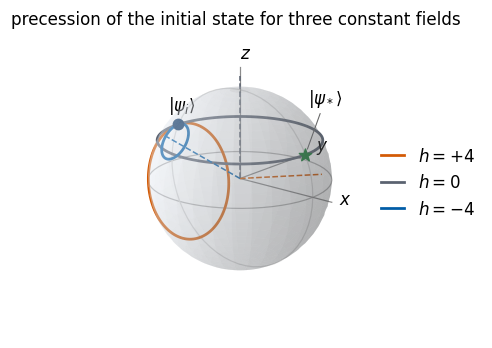

In [5]:
def sphere_axes(ax, elev=18, azim=-62):
    """Draw a light Bloch sphere with its equator and the x and z axes."""
    u = np.linspace(0, 2 * np.pi, 60); v = np.linspace(0, np.pi, 30)
    ax.plot_surface(np.outer(np.cos(u), np.sin(v)), np.outer(np.sin(u), np.sin(v)), np.outer(np.ones_like(u), np.cos(v)),
                    color="#e8eef6", alpha=0.25, linewidth=0)
    ax.plot(np.cos(u), np.sin(u), 0 * u, color="0.7", lw=0.8)
    ax.plot(np.cos(u), 0 * u, np.sin(u), color="0.85", lw=0.8)
    for d, lab in (((1.25, 0, 0), "$x$"), ((0, 1.25, 0), "$y$"), ((0, 0, 1.25), "$z$")):
        ax.plot([0, d[0]], [0, d[1]], [0, d[2]], color="0.55", lw=0.8)
        ax.text(*(1.08 * np.array(d)), lab, fontsize=11)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1); ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=elev, azim=azim); ax.set_axis_off()

def mark_states(ax, star_leader=False):
    ax.scatter(*n_i, s=45, color=UJNavy, depthshade=False); ax.text(*(n_i * 1.18 + [0, 0, 0.05]), r"$|\psi_i\rangle$", fontsize=11)
    ax.scatter(*n_star, s=70, marker="*", color=UJGreen, depthshade=False)
    if star_leader:
        # label above the star with a short leader line, clear of the orbits and of the axis labels
        x2, y2, _ = proj3d.proj_transform(*n_star, ax.get_proj())
        ax.annotate(r"$|\psi_*\rangle$", (x2, y2), textcoords="offset points", xytext=(2, 30), ha="left", va="bottom", fontsize=11,
                    arrowprops=dict(arrowstyle="-", color="0.4", lw=0.7, shrinkA=1, shrinkB=4))
    else:
        ax.text(*(n_star * 1.12 + [0, 0, 0.08]), r"$|\psi_*\rangle$", fontsize=11)

fig = plt.figure(figsize=(5.5, 3.3))
ax = fig.add_subplot(111, projection="3d"); sphere_axes(ax, elev=18, azim=-50); mark_states(ax, star_leader=True)
for h, col in ((+4.0, DSOrange), (0.0, UJGray), (-4.0, UJBlue)):
    B = np.array([h, 0.0, 1.0]); ts = np.linspace(0, 2 * np.pi / np.linalg.norm(B), 120)
    path = np.array([rotate(n_i, B, -np.linalg.norm(B) * t) for t in ts])
    ax.plot(*path.T, color=col, lw=1.8, label=f"$h={h:+.0f}$" if h != 0 else "$h=0$")
    ax.plot(*np.array([[0, 0, 0], 1.15 * B / np.linalg.norm(B)]).T, color=col, lw=1.0, ls="--")
ax.legend(loc="center left", bbox_to_anchor=(0.92, 0.5), handlelength=1.4)
ax.set_title("precession of the initial state for three constant fields", pad=0)
plt.tight_layout(); save(fig, "fig_lab054_bloch_precession"); plt.show()

The figure shows the three circles that the initial state traces for constant $h=+4$, $h=0$ and $h=-4$, and the three precession axes as dashed lines. The circles of $h=\pm4$ miss the target. The circle of $h=0$ passes through it, because the initial and the target state have the same $z$ component $1/\sqrt5$, and half a turn about the $z$ axis, which takes the time $t=\pi\approx3.14$, maps one onto the other, as the fidelity printed above confirms. Protocols that change the field during the evolution, and move the state from one circle to another, reach the target in a shorter time, as the scan below shows.

### The control problem

A protocol $h(t)$ for $0\le t\le T$ is piecewise constant on $N_T$ intervals of length $\delta t=T/N_T$. On interval $j$ the field takes the value $h_j$, and the final state is
$$
|\psi(T)\rangle = e^{-i\hat{\mathcal H}(h_{N_T-1})\,\delta t}\cdots e^{-i\hat{\mathcal H}(h_1)\,\delta t}\,e^{-i\hat{\mathcal H}(h_0)\,\delta t}\,|\psi_i\rangle .
$$
The goal is a protocol with large fidelity $F_h(T)=|\langle\psi_*|\psi(T)\rangle|^2$. Speed matters in experiments because every real qubit is coupled to its environment and loses its quantum coherence over a finite time, so a protocol that reaches the target faster loses less fidelity to the environment. The environment is left out of the model here, and we ask how high the fidelity can be for a given duration $T$.

The field is bounded, $|h|\le 4$. Bukov et al. restrict the protocols to bang-bang protocols, in which $h_j$ takes only the two extreme values $\pm4$. The reason comes from optimal control theory. Pontryagin's maximum principle [L. S. Pontryagin et al., *The Mathematical Theory of Optimal Processes*, Routledge reprint (2018), [doi:10.1201/9780203749319](https://doi.org/10.1201/9780203749319)] states that when the control enters the Hamiltonian linearly and is bounded, the optimal control sits at one of its bounds at every time at which a certain switching function is nonzero. Intermediate values are possible only on singular arcs, time intervals on which the switching function vanishes. For the single spin the time-optimal protocols of Hegerfeldt [G. C. Hegerfeldt, Phys. Rev. Lett. **111**, 260501 (2013), [doi:10.1103/PhysRevLett.111.260501](https://doi.org/10.1103/PhysRevLett.111.260501)] contain such an arc with $h=0$, and Bukov et al. note that there is no proof that the bang-bang family contains the optimal protocol of their problem. Within the bang-bang family a segment with $h=0$ can be imitated by a rapid alternation of $+4$ and $-4$, whose average is zero.

With $N_T$ intervals there are $2^{N_T}$ bang-bang protocols. Before the general code we look at the smallest case, $N_T=2$ intervals at duration $T=1$, so $\delta t=0.5$. There are four protocols, $(h_0,h_1)=(-4,-4)$, $(-4,+4)$, $(+4,-4)$ and $(+4,+4)$. Each one is a product of two $2\times2$ unitaries $\hat U_\pm=e^{-i\hat{\mathcal H}(\pm4)\,\delta t}$ applied to $|\psi_i\rangle$, and the cell prints the four fidelities.

In [6]:
T_small, dt_small = 1.0, 0.5
U_minus, U_plus = _expm_herm(H_qubit(-H_MAX), dt_small), _expm_herm(H_qubit(+H_MAX), dt_small)
for h0, U0 in ((-4, U_minus), (+4, U_plus)):
    for h1, U1 in ((-4, U_minus), (+4, U_plus)):
        psi_T = U1 @ (U0 @ psi_i)                       # first interval h0, then h1
        print(f"(h0, h1) = ({h0:+d}, {h1:+d}):  F = {float(fidelity_pure(psi_star, psi_T)):.4f}")

(h0, h1) = (-4, -4):  F = 0.0902
(h0, h1) = (-4, +4):  F = 0.0555
(h0, h1) = (+4, -4):  F = 0.5615
(h0, h1) = (+4, +4):  F = 0.0902


Starting with $+4$ and ending with $-4$ is the best of the four, with $F=0.56$, and at this short duration no protocol comes close to the target. For $N_T$ intervals the same construction is repeated. We take $N_T=20$, so that all $2^{20}=1\,048\,576$ protocols can be evaluated at every duration $T$. The function `all_protocol_fidelities` builds all final states at once. It applies both one-step unitaries to every state of the previous level, which doubles the number of states at each of the 20 steps. The protocol with index $k$ has field $h_j=+4$ when bit $j$ of $k$ is one and $h_j=-4$ otherwise.

In [7]:
N_T = 20

@jax.jit
def all_protocol_fidelities(T):
    """Fidelities F_h(T) of all 2^N_T bang-bang protocols; bit j of the index = 1 means h_j = +4."""
    dt = T / N_T
    U_minus, U_plus = _expm_herm(H_qubit(-H_MAX), dt), _expm_herm(H_qubit(H_MAX), dt)
    psi = psi_i[None, :]
    for _ in range(N_T):                                  # level k holds the 2^k states after k steps
        psi = jnp.concatenate([psi @ U_minus.T, psi @ U_plus.T], axis=0)
    return jnp.abs(psi @ jnp.conj(psi_star)) ** 2

def protocol_field(k):
    """Field values h_0 ... h_{N_T-1} of protocol index k."""
    return np.where((int(k) >> np.arange(N_T)) & 1, H_MAX, -H_MAX)

def protocol_fidelity(fields, T):
    """Fidelity of one protocol, evolved interval by interval (independent check of the enumeration)."""
    psi = psi_i
    for h in fields:
        psi = _expm_herm(H_qubit(h), T / N_T) @ psi
    return float(fidelity_pure(psi_star, psi))

t0 = time.time(); F_all = np.asarray(all_protocol_fidelities(2.0)); t_enum = time.time() - t0
k_best = int(F_all.argmax())
print(f"{F_all.size} protocols at T = 2.0 evaluated in {t_enum:.2f} s (including compilation)")
print(f"best fidelity {F_all[k_best]:.6f}, the same protocol evolved interval by interval {protocol_fidelity(protocol_field(k_best), 2.0):.6f}")
print("mean fidelity of a random protocol", round(float(F_all.mean()), 4))

1048576 protocols at T = 2.0 evaluated in 0.18 s (including compilation)
best fidelity 0.953190, the same protocol evolved interval by interval 0.953190
mean fidelity of a random protocol 0.4935


### Control phases

We now scan the duration $T$ from $0.1$ to $4$ and record three things at each $T$. The first is the best fidelity $F_h(T)=\max_k F_k$ over all protocols, which is exact within the bang-bang family with $N_T=20$. The second is the number of local maxima of the fidelity landscape, protocols whose fidelity decreases under every single flip $h_j\to-h_j$. A landscape with one maximum is easy for any local search, and a landscape with thousands of maxima traps it. The third is the order parameter of Bukov et al.,
$$
q(T) = \frac{1}{16\,N_T}\sum_{j=0}^{N_T-1}\overline{\big(h^\alpha_j-\bar h_j\big)^2},\qquad \bar h_j=\overline{h^\alpha_j},
$$
where $\{h^\alpha\}$ are the protocols reached by stochastic descent from random starting protocols and the bar is the average over these runs $\alpha$. Stochastic descent flips one randomly chosen $h_j$ whenever this increases the fidelity and stops when no single flip helps. If all runs end in the same protocol, $q=0$. If they end in unrelated protocols, $\bar h_j\approx0$ and $q\approx1$. The quantity is modelled on the Edwards–Anderson order parameter of spin glasses, which measures how strongly different low-energy configurations agree with each other.

In [8]:
T_grid = np.round(np.arange(0.1, 4.0001, 0.1), 2)
bit = 1 << np.arange(N_T); all_idx = np.arange(2 ** N_T)
rng_sd = np.random.default_rng(0)
N_REAL = 400                                              # stochastic-descent runs per T

def stochastic_descent(F, n_real):
    """Random single-flip ascent on the table F, run in parallel from n_real random protocols."""
    idx = rng_sd.integers(0, 2 ** N_T, n_real)
    while True:
        nb = idx[:, None] ^ bit[None, :]                  # all single-flip neighbours
        better = F[nb] > F[idx][:, None] + 1e-12
        if not better.any():
            return idx
        choice = (rng_sd.random(better.shape) * better).argmax(1)   # a random improving flip
        idx = np.where(better.any(1), nb[np.arange(n_real), choice], idx)

The cell above defines the stochastic descent. It is run in parallel from `N_REAL` $=400$ random protocols and uses the table of all fidelities, so each proposed flip costs one table lookup. The next cell runs the scan over $T$. At every duration it computes the fidelity table, marks the local maxima by comparing each protocol with its 20 single-flip neighbours, runs the stochastic descent and evaluates $q(T)$. It also records whether the best protocol is the single jump at $T/2$, $h=+4$ for the first ten intervals and $h=-4$ for the last ten.

In [9]:
single_jump = sum(1 << j for j in range(N_T // 2))        # h = +4 in the first half, -4 in the second
scan = {"F_best": [], "k_best": [], "n_local_max": [], "q": [], "F_sd_mean": []}
F_tables = {}
t0 = time.time()
for T in T_grid:
    F = np.asarray(all_protocol_fidelities(T))
    is_max = np.ones(F.size, bool)
    for b in bit:
        is_max &= F >= F[all_idx ^ b]
    ends = stochastic_descent(F, N_REAL)
    h_alpha = np.array([protocol_field(k) for k in ends])
    scan["F_best"].append(F.max()); scan["k_best"].append(int(F.argmax())); scan["n_local_max"].append(int(is_max.sum()))
    scan["q"].append(float(((h_alpha - h_alpha.mean(0)) ** 2).mean() / H_MAX ** 2)); scan["F_sd_mean"].append(F[ends].mean())
    F_tables[float(T)] = F
scan = {k: np.array(v) for k, v in scan.items()}
print(f"scan of {len(T_grid)} durations in {time.time() - t0:.1f} s")
print("   T   best F   optimum = single jump   local maxima    q    mean F of descent")
for i, T in enumerate(T_grid):
    if i % 2 == 1 or T in (0.6, 0.7):
        print(f"{T:4.1f}  {scan['F_best'][i]:.5f}   {str(scan['k_best'][i] == single_jump):>5s}            "
              f"{scan['n_local_max'][i]:6d}     {scan['q'][i]:.3f}   {scan['F_sd_mean'][i]:.4f}")

T_single_jump_max = float(T_grid[scan["k_best"] == single_jump].max())
T_QSL = float(T_grid[np.argmax(scan["F_best"] > 1 - 1e-3)])
print(f"\nlargest T at which the optimum is the single jump at T/2: {T_single_jump_max}")
print(f"smallest T with best fidelity above 0.999: {T_QSL} (best F there {scan['F_best'][T_grid == T_QSL][0]:.5f})")
NUMBERS.update(T_single_jump_max=T_single_jump_max, T_QSL=T_QSL,
               F_best_T1=float(scan["F_best"][T_grid == 1.0][0]), F_best_T2=float(scan["F_best"][T_grid == 2.0][0]),
               nmax_T04=int(scan["n_local_max"][T_grid == 0.4][0]), nmax_T2=int(scan["n_local_max"][T_grid == 2.0][0]),
               nmax_T4=int(scan["n_local_max"][T_grid == 4.0][0]),
               q_T04=float(scan["q"][T_grid == 0.4][0]), q_T24=float(scan["q"][T_grid == 2.4][0]), q_T4=float(scan["q"][T_grid == 4.0][0]))

scan of 40 durations in 8.7 s
   T   best F   optimum = single jump   local maxima    q    mean F of descent
 0.2  0.22349    True                 2     0.100   0.2233
 0.4  0.28811    True                 6     0.187   0.2870
 0.6  0.37857    True                28     0.298   0.3751
 0.7  0.42753   False                76     0.374   0.4227
 0.8  0.47721   False               185     0.445   0.4705
 1.0  0.57639   False               818     0.565   0.5638
 1.2  0.67225   False              2370     0.653   0.6511
 1.4  0.76217   False              5046     0.725   0.7296
 1.6  0.83944   False              8805     0.776   0.7986
 1.8  0.90615   False             13257     0.817   0.8570
 2.0  0.95319   False             17984     0.855   0.8998
 2.2  0.98602   False             22495     0.864   0.9342
 2.4  0.99971   False             26615     0.889   0.9471
 2.6  1.00000   False             30417     0.903   0.9622
 2.8  1.00000   False             35289     0.933   0.9608
 3.0  

The scan shows the three regimes that Bukov et al. call control phases. For short durations the best protocol is a single jump, $h=+4$ for the first half of the time and $h=-4$ for the second half, which agrees with the single jump at half time that the paper reports in its overconstrained phase I below $T_c\approx0.6$. The landscape has only a few local maxima there, all small variations of the same jump, and the order parameter $q$ stays below $0.3$. Our $q$ is small and nonzero in this regime because the discrete jump position admits a few neighbouring single-flip maxima, while the paper reports $q=0$ for $T<T_c$ with its time step $\delta t=0.05$.

Between this regime and the quantum speed limit $T_{\rm QSL}$, the shortest duration at which the target can be reached, the best fidelity rises towards one while the number of local maxima grows into the thousands. This is the correlated, glass-like phase II, where good protocols are many and differ from each other, and local search often stops at a poor one. Above $T_{\rm QSL}$ many protocols reach unit fidelity, $q$ approaches one, and the problem is in the controllable phase III. Bukov et al. give $T_{\rm QSL}\approx2.4$ for the single spin, and our enumeration first exceeds $F=0.999$ at $T=2.4$.

## Q-learning on the qubit

Bukov et al. let a Q-learning agent build the protocol one interval at a time. The decision problem is the following.

| Object | For the qubit |
|---|---|
| state $s_j$ | the time step $j$ and the field $h_{j-1}$ applied in the previous interval |
| action $a_j$ | the field $h_j\in\{-4,+4\}$ for the next interval |
| reward | zero during the protocol and $F_h(T)$ at the end |
| episode | $N_T=20$ decisions, one complete protocol |

The pair (time, field) is the state used in the paper. It does not determine the quantum state, which depends on the whole field history, so the agent works with incomplete information, and the paper calls the problem partially observable. The agent learns the action value $Q(s,a)$, the final fidelity it expects after choosing $a$ in $s$ and acting well afterwards, with learning rate $\alpha=0.2$ and the update of Watkins [C. J. C. H. Watkins and P. Dayan, Mach. Learn. **8**, 279 (1992), [doi:10.1007/BF00992698](https://doi.org/10.1007/BF00992698)],
$$
Q(s_j,a_j)\leftarrow Q(s_j,a_j)+\alpha\Big[r_{j+1}+\max_a Q(s_{j+1},a)-Q(s_j,a_j)\Big].
$$
The value at the last step is pulled towards the measured fidelity, and each earlier value is pulled towards the best value of its successor. We sweep the update backwards through each finished episode, which carries the final reward to the first step within one episode. The agent explores with an $\epsilon$-greedy rule, a random field with probability $\epsilon$ and the field of largest $Q$ otherwise, with $\epsilon$ decreasing linearly from one to zero over the first 80% of the episodes. Every second episode replays the best protocol found so far, a simplified form of the replay schedule of the paper, which helps the agent to remember a rare good protocol.

Our implementation differs from the paper in the following points. Bukov et al. use a fixed time step $\delta t=0.05$, so that $N_T=T/\delta t$ grows with $T$, while we fix $N_T=20$ so that every duration can be enumerated. They represent $Q$ by a linear function with tile coding over the field range, explore with a softmax rule whose inverse temperature is ramped, alternate blocks of 40 exploring and 40 replay episodes and train for $2\times10^4$ episodes, while we use a table, $\epsilon$-greedy exploration, a replay every second episode and $10^4$ episodes. Their reference is stochastic descent from many random protocols, and ours is the complete enumeration together with the same stochastic descent for the order parameter.

The agent sees only the final fidelities of the protocols it plays. The table of all fidelities computed above is used to read off these fidelities quickly, and the agent never sees the rest of the table. The function `q_learning` stores $Q$ as an array `Q[j, h_prev, a]` with $h=-4$ coded as 0 and $h=+4$ as 1, plays the episodes and returns the greedy protocol of the trained table.

In [10]:
def q_learning(F_table, n_steps, n_episodes=10_000, alpha=0.2, seed=0):
    """Tabular Q-learning for bang-bang protocols of n_steps intervals.

    State (j, h_{j-1}), actions h_j = -4 (0) or +4 (1), reward F_table[k] at the end of the episode.
    F_table holds the fidelities of all 2^n_steps protocols and is used only to look up the fidelity
    of the protocol k that the agent has just played. Returns the greedy protocol and the history.
    """
    rng = np.random.default_rng(seed)
    Q = np.zeros((n_steps, 2, 2))                     # Q[j, previous action, action]; h_{-1} = -4 by convention
    best_F, best_k, history = -1.0, 0, []
    for ep in range(n_episodes):
        eps = max(0.0, 1 - ep / (0.8 * n_episodes))
        replay = ep % 2 == 1 and best_F > 0
        k, prev, traj = 0, 0, []
        for j in range(n_steps):
            if replay:
                a = (best_k >> j) & 1
            elif rng.random() < eps:
                a = int(rng.integers(2))
            else:
                a = int(np.argmax(Q[j, prev] + 1e-9 * rng.random(2)))   # random tie breaking
            traj.append((j, prev, a)); k |= a << j; prev = a
        F_end = F_table[k]
        if F_end > best_F:
            best_F, best_k = F_end, k
        target = F_end                            # backward sweep of the update, gamma = 1
        for j, p, a in reversed(traj):
            Q[j, p, a] += alpha * (target - Q[j, p, a])
            target = Q[j, p].max()
        history.append((F_end, replay))
    k, prev = 0, 0                                # greedy protocol of the trained agent
    for j in range(n_steps):
        a = int(np.argmax(Q[j, prev])); k |= a << j; prev = a
    return dict(k_greedy=k, F_greedy=F_table[k], best_F=best_F, history=np.array(history))

Before the scan over durations we run the agent on the two-interval problem from above, $N_T=2$ at $T=1$, where the four fidelities were printed one by one. The cell builds the table of the four fidelities, trains for 200 episodes and prints the protocol that the trained agent chooses. In the first step the agent compares $Q(s_0,-4)$ and $Q(s_0,+4)$, which approach the best fidelity reachable after each first choice.

In [11]:
F_two = np.zeros(4)
for k in range(4):                                         # bit 0 = h_0, bit 1 = h_1
    psi_T = psi_i
    for j in range(2):
        psi_T = (U_plus if (k >> j) & 1 else U_minus) @ psi_T
    F_two[k] = float(fidelity_pure(psi_star, psi_T))
toy = q_learning(F_two, 2, n_episodes=200, seed=0)
print("fidelities of the four protocols (k = 0..3):", np.round(F_two, 4))
print("greedy protocol of the agent: k =", toy["k_greedy"], " h =", [int(h) for h in np.where((toy["k_greedy"] >> np.arange(2)) & 1, 4, -4)],
      f" F = {toy['F_greedy']:.4f}")

fidelities of the four protocols (k = 0..3): [0.0902 0.5615 0.0555 0.0902]
greedy protocol of the agent: k = 1  h = [4, -4]  F = 0.5615


The agent picks the best of the four protocols. The same function now runs on the full problem with $N_T=20$, at six durations and with three random seeds each, and every result is compared with the exact optimum from the enumeration.

In [12]:
T_RL, SEEDS = [0.4, 1.0, 1.6, 2.0, 2.4, 3.2], [0, 1, 2]
rl_runs = {}
t0 = time.time()
for T in T_RL:
    rl_runs[T] = [q_learning(F_tables[T], N_T, seed=s) for s in SEEDS]
    Fs = [r["F_greedy"] for r in rl_runs[T]]
    print(f"T = {T:3.1f}: greedy F for seeds {SEEDS} = {np.round(Fs, 5)}, exact optimum {F_tables[T].max():.5f}, "
          f"largest gap {F_tables[T].max() - min(Fs):.1e}")
rl = {T: runs[0] for T, runs in rl_runs.items()}           # seed 0, used in the protocol figures
print(f"Q-learning, {len(T_RL)} durations x {len(SEEDS)} seeds in {time.time() - t0:.0f} s; each run plays 10^4 episodes, "
      f"{1e4 / 2 ** N_T:.1%} of the 2^20 protocols")
gaps = np.array([F_tables[T].max() - r["F_greedy"] for T in T_RL for r in rl_runs[T]])
NUMBERS.update(rl_max_gap=float(gaps.max()), rl_F_T24=float(rl[2.4]["F_greedy"]), exact_F_T24=float(F_tables[2.4].max()))

T = 0.4: greedy F for seeds [0, 1, 2] = [0.28472 0.28811 0.28811], exact optimum 0.28811, largest gap 3.4e-03


T = 1.0: greedy F for seeds [0, 1, 2] = [0.57535 0.57595 0.57639], exact optimum 0.57639, largest gap 1.0e-03


T = 1.6: greedy F for seeds [0, 1, 2] = [0.83806 0.8351  0.83786], exact optimum 0.83944, largest gap 4.3e-03


T = 2.0: greedy F for seeds [0, 1, 2] = [0.95155 0.95319 0.94944], exact optimum 0.95319, largest gap 3.7e-03


T = 2.4: greedy F for seeds [0, 1, 2] = [0.99819 0.998   0.9973 ], exact optimum 0.99971, largest gap 2.4e-03


T = 3.2: greedy F for seeds [0, 1, 2] = [0.99988 0.99995 0.99992], exact optimum 1.00000, largest gap 1.2e-04
Q-learning, 6 durations x 3 seeds in 22 s; each run plays 10^4 episodes, 1.0% of the 2^20 protocols


For all durations and all three seeds the greedy protocols of the trained agents reach fidelities within $4.3\times10^{-3}$ of the exact optimum, the largest printed gap, after playing about one percent of all protocols. The learning curve at $T=2.4$, close to the quantum speed limit, shows how this happens.

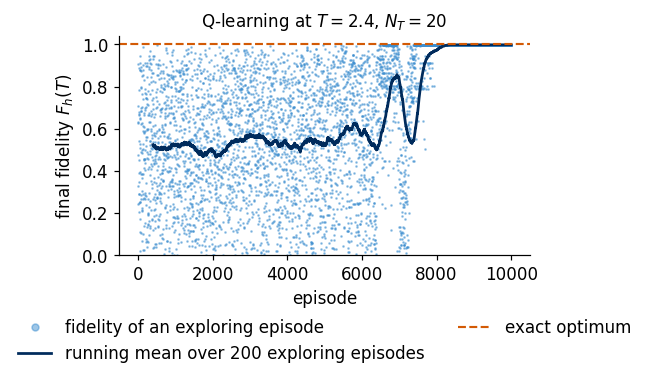

In [13]:
hist = rl[2.4]["history"]; ep = np.arange(len(hist)); explore = hist[:, 1] == 0
fig, ax = plt.subplots(figsize=(5.5, 3.8))
ax.plot(ep[explore], hist[explore, 0], ".", ms=1.5, color=UJSky, alpha=0.5, label="fidelity of an exploring episode")
w = 200; run = np.convolve(hist[explore, 0], np.ones(w) / w, mode="valid")
ax.plot(ep[explore][w - 1:], run, color=UJNavy, lw=1.8, label=f"running mean over {w} exploring episodes")
ax.axhline(F_tables[2.4].max(), color=DSOrange, ls="--", lw=1.4, label="exact optimum")
ax.set_xlabel("episode"); ax.set_ylabel(r"final fidelity $F_h(T)$"); ax.set_ylim(0, 1.04)
ax.set_title(r"Q-learning at $T=2.4$, $N_T=20$")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, markerscale=6, fontsize=11)
plt.tight_layout(); save(fig, "fig_lab054_qubit_learning"); plt.show()

At the start the agent plays random protocols, whose fidelities spread over the whole interval. As $\epsilon$ decreases the agent plays variations of its current best protocol, and the running mean climbs to the optimum. The replayed episodes are left out of the plot. The phase diagram collects the exact scan and the Q-learning results.

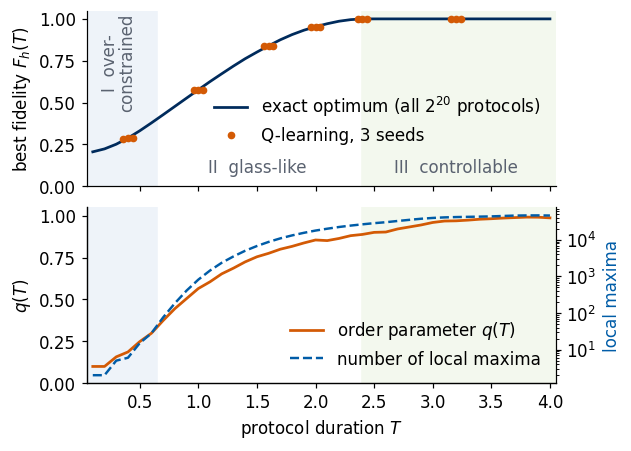

In [14]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(5.5, 4.4), sharex=True, gridspec_kw=dict(hspace=0.12))
for a in (a1, a2):
    a.axvspan(0, T_single_jump_max + 0.05, color="#eef3f9"); a.axvspan(T_QSL, 4.05, color="#f3f8ee")
a1.plot(T_grid, scan["F_best"], color=UJNavy, lw=1.8, label="exact optimum (all $2^{20}$ protocols)")
for i, s_ in enumerate(SEEDS):
    a1.plot(np.array(T_RL) + 0.04 * (i - 1), [rl_runs[T][i]["F_greedy"] for T in T_RL], "o", ms=4, color=DSOrange,
            label=f"Q-learning, {len(SEEDS)} seeds" if i == 0 else None)
a1.set_ylabel(r"best fidelity $F_h(T)$"); a1.set_ylim(0, 1.05); a1.legend(loc="lower right", bbox_to_anchor=(1.0, 0.15))
a1.text(T_single_jump_max / 2 + 0.02, 0.74, "I  over-\nconstrained", ha="center", va="center", rotation=90, fontsize=11, color=UJGray, linespacing=1.0)
for x, lab in (((T_single_jump_max + T_QSL) / 2, "II  glass-like"), ((T_QSL + 4) / 2, "III  controllable")):
    a1.text(x, 0.08, lab, ha="center", fontsize=11, color=UJGray)
a2.plot(T_grid, scan["q"], color=DSOrange, lw=1.8, label=r"order parameter $q(T)$")
a2.set_ylabel(r"$q(T)$"); a2.set_ylim(0, 1.05); a2.set_xlabel(r"protocol duration $T$")
a3 = a2.twinx(); a3.spines["right"].set_visible(True)
a3.semilogy(T_grid, scan["n_local_max"], color=UJBlue, lw=1.6, ls="--", label="number of local maxima")
a3.set_ylabel("local maxima", color=UJBlue)
a2.legend(handles=a2.get_lines() + a3.get_lines(), loc="lower right")
a2.set_xlim(0.05, 4.05)
plt.tight_layout(); save(fig, "fig_lab054_qubit_phases"); plt.show()

The shaded regions mark the overconstrained phase I, where the optimum is the single jump, and the controllable phase III, above the first duration with $F>0.999$. The unshaded region between them is the glass-like phase II. The three names are those of Bukov et al. The order parameter and the number of local maxima are computed from the same tables. Finally we look at the protocols themselves and at the paths they trace on the Bloch sphere, at one duration in each phase.

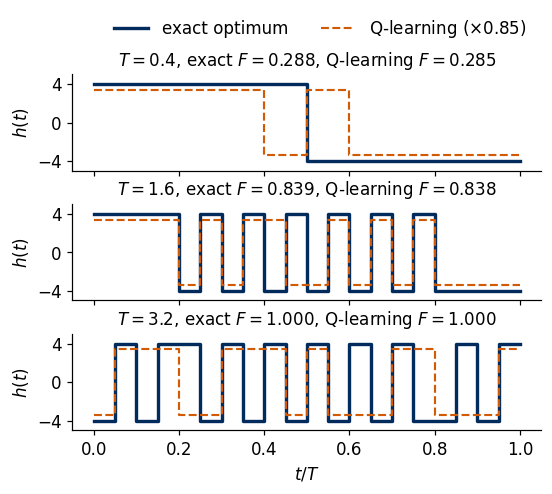

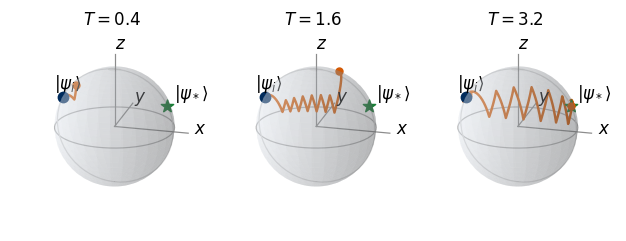

In [15]:
T_show = [0.4, 1.6, 3.2]

def bloch_path(fields, T, sub=12):
    """Bloch vectors along a protocol, sub points per interval."""
    psi, pts = psi_i, [bloch(psi_i)]
    for h in fields:
        U = _expm_herm(H_qubit(h), T / N_T / sub)
        for _ in range(sub):
            psi = U @ psi; pts.append(bloch(psi))
    return np.array(pts)

fig, axs = plt.subplots(3, 1, figsize=(5.5, 4.2), sharex=True, gridspec_kw=dict(hspace=0.35))
for ax, T in zip(axs, T_show):
    t_edges = np.linspace(0, 1, N_T + 1)
    h_ex, h_rl = protocol_field(F_tables[T].argmax()), protocol_field(rl[T]["k_greedy"])
    ax.step(t_edges, np.r_[h_ex, h_ex[-1]], where="post", color=UJNavy, lw=2.2, label="exact optimum")
    ax.step(t_edges, np.r_[h_rl, h_rl[-1]] * 0.85, where="post", color=DSOrange, lw=1.4, ls="--", label=r"Q-learning ($\times0.85$)")
    ax.set_ylim(-5, 5); ax.set_yticks([-4, 0, 4]); ax.set_ylabel("$h(t)$")
    ax.set_title(f"$T={T}$, exact $F={F_tables[T].max():.3f}$, Q-learning $F={rl[T]['F_greedy']:.3f}$", fontsize=11)
axs[0].legend(loc="upper right", ncol=2, fontsize=11, bbox_to_anchor=(1.0, 1.75))
axs[-1].set_xlabel("$t/T$")
plt.tight_layout(); save(fig, "fig_lab054_qubit_protocols"); plt.show()

fig = plt.figure(figsize=(5.5, 2.2))
for i, T in enumerate(T_show):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d"); sphere_axes(ax, elev=20, azim=-75); mark_states(ax)
    path = bloch_path(protocol_field(F_tables[T].argmax()), T)
    ax.plot(*path.T, color=DSOrange, lw=1.6); ax.scatter(*path[-1], s=20, color=DSOrange, depthshade=False)
    ax.set_title(f"$T={T}$", pad=-4)
plt.subplots_adjust(left=0, right=1, wspace=0.0, top=0.92, bottom=0.0)
save(fig, "fig_lab054_qubit_bloch_paths"); plt.show()

The protocol plot draws the Q-learning protocol scaled by $0.85$ so that it remains visible where it coincides with the exact optimum. At $T=0.4$ the optimum is the single jump. The state first precesses about the axis of $h=+4$ and then about that of $h=-4$, and the time is too short to come close to the target. At $T=1.6$ the protocol starts with a long $+4$ segment and then alternates rapidly, which imitates $h=0$ and lets the state precess about the $z$ axis near the equator. This is the structure that Bukov et al. describe for their phase II protocol, a rotation to the equator, a precession along it with the field effectively off, and a final rotation towards the target. At $T=3.2$ the target is reached, and many different protocols do the same.

### Many coupled spins with one field

Bukov et al. repeat the same experiment for a closed chain of $N$ coupled spins driven by the same single field,
$$
\hat{\mathcal H}[h(t)] = -\sum_{j=1}^{N}\Big(\hat S^z_{j+1}\hat S^z_j + g\,\hat S^z_j + h(t)\,\hat S^x_j\Big),\qquad \hat S^z_{N+1}\equiv \hat S^z_1 ,
$$
with $g=1$. The initial and target states are again the ground states at $h=-2$ and $h=+2$, and the field is again bang-bang, $h_j=\pm4$. Each interval of a protocol is now a time evolution of the whole chain under one of two many-body Hamiltonians, $\hat{\mathcal H}[+4]$ or $\hat{\mathcal H}[-4]$, whose terms do not commute. We take $N=6$ and $N_T=16$ intervals, so that all $2^{16}=65\,536$ protocols can again be enumerated. With $\hat S=\hat\sigma/2$ the Hamiltonian in Pauli matrices is $-\tfrac14\sum \hat Z_{j+1}\hat Z_j-\tfrac g2\sum \hat Z_j-\tfrac h2\sum \hat X_j$, which `heisenberg_terms` builds as a list of local terms.

Bukov et al. show learning curves for this chain with $N=10$ and use $\delta t=0.05$. Our chain is shorter and our $N_T=16$ is fixed, which keeps the enumeration of all protocols possible.

The evolution over one interval uses `exact_evolve`, which diagonalises the $64\times64$ Hamiltonian once and serves as the reference propagator of the engine at this size. The first cell checks it against a second-order Trotter evolution with small steps, as used in time-evolving block decimation (TEBD), which applies only one- and two-spin gates.

In [16]:
N_CHAIN, NT_CHAIN = 6, 16

def bukov_chain_terms(h, g=1.0):
    """H[h] = -sum_j (S^z_{j+1} S^z_j + g S^z_j + h S^x_j) on a closed chain, written with Pauli matrices."""
    return heisenberg_terms(N_CHAIN, Jxx=0.0, Jyy=0.0, Jzz=-0.25, hx=-h / 2, hz=-g / 2, periodic=True)

def ground_state_dense(terms, N):
    """Reference ground state from dense diagonalisation (small N only)."""
    w, v = jnp.linalg.eigh(dense_hamiltonian(terms, N))
    return w, v[:, 0].reshape((2,) * N)

_, chain_i = ground_state_dense(bukov_chain_terms(-2.0), N_CHAIN)
_, chain_star = ground_state_dense(bukov_chain_terms(+2.0), N_CHAIN)
print(f"chain of {N_CHAIN} spins: fidelity of the initial with the target ground state = {float(fidelity_pure(chain_star, chain_i)):.4f}")

# check of the propagator: exact_evolve against 200 TEBD steps of second order
psi_check, t_check = haar_state(jax.random.PRNGKey(5), N_CHAIN), 0.25
gates = tebd_gates(bukov_chain_terms(4.0), t_check / 200, order=2)
psi_tebd = psi_check
for _ in range(200):
    psi_tebd = apply_gates(psi_tebd, gates)
print("|exact_evolve - TEBD| =", float(jnp.abs(exact_evolve(psi_check, bukov_chain_terms(4.0), t_check) - psi_tebd).max()))
print("norm after exact_evolve =", float(jnp.linalg.norm(exact_evolve(psi_check, bukov_chain_terms(4.0), t_check))))

chain of 6 spins: fidelity of the initial with the target ground state = 0.0091


|exact_evolve - TEBD| = 1.8945210639608474e-07
norm after exact_evolve = 1.0


The two propagators agree to the accuracy of the Trotter steps, and the norm is conserved. The next cell enumerates all $2^{16}$ protocols of the chain at 16 durations from $T=0.25$ to $T=4$, with the same doubling construction as for the single spin.

In [17]:
@jax.jit
def all_chain_fidelities(T):
    """Fidelities of all 2^NT_CHAIN bang-bang protocols for the spin chain (same bit convention as for the qubit)."""
    dt = T / NT_CHAIN
    evolve_minus = jax.vmap(lambda p: exact_evolve(p, bukov_chain_terms(-H_MAX), dt))
    evolve_plus = jax.vmap(lambda p: exact_evolve(p, bukov_chain_terms(+H_MAX), dt))
    psi = chain_i[None]
    for _ in range(NT_CHAIN):
        psi = jnp.concatenate([evolve_minus(psi), evolve_plus(psi)], axis=0)
    return jnp.abs(psi.reshape(psi.shape[0], -1) @ jnp.conj(chain_star.reshape(-1))) ** 2

T_chain = np.round(np.arange(0.25, 4.001, 0.25), 2)
t0 = time.time()
F_chain_tables = {float(T): np.asarray(all_chain_fidelities(T)) for T in T_chain}
F_chain_best = np.array([F_chain_tables[float(T)].max() for T in T_chain])
print(f"{len(T_chain)} durations x 2^{NT_CHAIN} protocols in {time.time() - t0:.1f} s")
print("T      " + " ".join(f"{T:6.2f}" for T in T_chain))
print("best F " + " ".join(f"{F:6.3f}" for F in F_chain_best))

NUMBERS.update(chain_F_init=float(fidelity_pure(chain_star, chain_i)), chain_F_best_max=float(F_chain_best.max()),
               chain_T_at_max=float(T_chain[F_chain_best.argmax()]))

16 durations x 2^16 protocols in 5.4 s
T        0.25   0.50   0.75   1.00   1.25   1.50   1.75   2.00   2.25   2.50   2.75   3.00   3.25   3.50   3.75   4.00
best F  0.026  0.104  0.258  0.445  0.568  0.630  0.686  0.764  0.866  0.938  0.954  0.966  0.970  0.956  0.958  0.966


The figure compares the best bang-bang fidelity of the chain with that of the single spin.

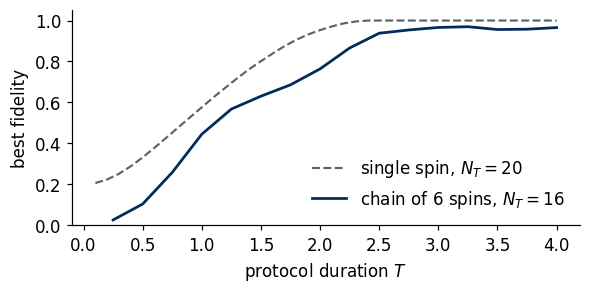

In [18]:
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.plot(T_grid, scan["F_best"], color=UJGray, lw=1.4, ls="--", label="single spin, $N_T=20$")
ax.plot(T_chain, F_chain_best, color=UJNavy, lw=1.8, label=f"chain of {N_CHAIN} spins, $N_T={NT_CHAIN}$")
ax.set_xlabel("protocol duration $T$"); ax.set_ylabel("best fidelity"); ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
plt.tight_layout(); save(fig, "fig_lab054_chain_phases"); plt.show()

The chain starts much further from its target than the single spin, with the printed initial fidelity below one percent, and one global field has to steer all 64 amplitudes. The best bang-bang fidelity rises with $T$ up to $T\approx3$ and then varies by about one percent, because with $N_T=16$ fixed the interval length $\delta t=T/16$ changes with $T$. It stays below one on the whole interval up to $T=4$, which agrees with the observation of Bukov et al. that for the coupled chain a quantum speed limit, if it exists, lies outside the protocol durations they studied. Enumeration is possible here only because $2^{16}$ protocols are few. Bukov et al. train their agent on this chain with a function approximation of $Q$, and the second part of this notebook uses a neural network for the many-body problem.

## A chain of spins and its ground state

We now turn to the second paper and put $N$ spins on an open line. Neighbouring spins interact, and each spin feels a field. All chains of this part are written in one convention, the Ising chain
$$
\hat{\mathcal H} = -J\sum_{i=0}^{N-2} \hat Z_i \hat Z_{i+1} \;-\; h\sum_{i=0}^{N-1} \hat X_i \;-\; g\sum_{i=0}^{N-1} \hat Z_i ,
$$
where $\hat Z_i$ and $\hat X_i$ are Pauli matrices acting on spin $i$, $h$ is the transverse field and $g$ the longitudinal field. Metz and Bukov write the same chain as $\hat{\mathcal H} = J\sum \hat Z_j\hat Z_{j+1} - g_x\sum \hat X_j - g_z\sum \hat Z_j$, so their $J$ is our $-J$, their $g_x$ is our $h$ and their $g_z$ is our $g$. With $g=0$ this is the transverse-field Ising model (TFIM). The first term is the interaction. The product $\hat Z_i\hat Z_{i+1}$ is $+1$ when neighbours point the same way along $z$ and $-1$ otherwise, so for $J>0$ the energy is lowest when all spins are aligned, up or down. The second term, the transverse field, points along $x$. Its lowest energy state is $|+\rangle=(|{\uparrow}\rangle+|{\downarrow}\rangle)/\sqrt2$ for every spin, the spin pointing along $x$, which is an equal superposition of up and down along $z$. The two terms compete, the interaction wants the spins aligned along $z$ and the field wants to flip them into $x$. We set $J=1$.

The two limits are simple. At $h=0$ the ground states are $|{\uparrow\uparrow\cdots\uparrow}\rangle$ and $|{\downarrow\downarrow\cdots\downarrow}\rangle$, a ferromagnet. For a finite chain at small $h>0$ the field mixes them, and the ground state is close to their symmetric superposition, with a tiny energy gap to the antisymmetric one. At $h\gg J$ the ground state approaches $|{+}{+}\cdots{+}\rangle$, a paramagnet. In an infinite chain the two phases are separated by a quantum phase transition at $h=J$ [P. Pfeuty, Ann. Phys. **57**, 79 (1970), [doi:10.1016/0003-4916(70)90270-8](https://doi.org/10.1016/0003-4916(70)90270-8)]. The TFIM maps to free fermions and is called integrable. In a chain of six spins the transition is a smooth crossover.

As a contrast we also use a chain that cannot be solved this way, the Ising chain with transverse and longitudinal fields studied by H. Kim and D. A. Huse, Phys. Rev. Lett. **111**, 127205 (2013), [doi:10.1103/PhysRevLett.111.127205](https://doi.org/10.1103/PhysRevLett.111.127205). Kim and Huse write $\hat{\mathcal H}=\sum_i g \hat X_i+\sum_i h \hat Z_i + \sum_i J \hat Z_i\hat Z_{i+1}$ with $J=1$, $g=(\sqrt5+5)/8\approx0.9045$ and $h=(\sqrt5+1)/4\approx0.8090$, and they change the longitudinal field on the two end spins to $h-J$. Their coupling $+J\,\hat Z_i\hat Z_{i+1}$ is antiferromagnetic. In our convention this point is $J=-1$, $h=0.9045$ and $g=0.8090$. The signs of the two fields can be flipped by rotating all spins and do not change the physics, while the sign of $J$ cannot be removed when $g\neq0$. We use a uniform longitudinal field on all spins and leave out the end correction of Kim and Huse. The longitudinal field breaks integrability.

A state of $N$ spins has $2^N$ complex amplitudes, one for each configuration of ups and downs. The cell prints how this number and the memory of one state grow with $N$.

In [19]:
for N_ in (1, 2, 6, 10, 20, 30, 40, 50):
    print(f"N = {N_:2d}: 2^N = {2 ** N_:>20,d} amplitudes, {16 * 2 ** N_ / 1e9:.3g} GB in double precision")

N =  1: 2^N =                    2 amplitudes, 3.2e-08 GB in double precision
N =  2: 2^N =                    4 amplitudes, 6.4e-08 GB in double precision
N =  6: 2^N =                   64 amplitudes, 1.02e-06 GB in double precision
N = 10: 2^N =                1,024 amplitudes, 1.64e-05 GB in double precision
N = 20: 2^N =            1,048,576 amplitudes, 0.0168 GB in double precision
N = 30: 2^N =        1,073,741,824 amplitudes, 17.2 GB in double precision
N = 40: 2^N =    1,099,511,627,776 amplitudes, 1.76e+04 GB in double precision
N = 50: 2^N = 1,125,899,906,842,624 amplitudes, 1.8e+07 GB in double precision


Six spins need 64 numbers, and fifty spins would need more memory than any computer has. In this section and the next we use $N=6$ and the exact state vector, and the control problems later use $N=4$ and $N=6$. The Hamiltonians are lists of local terms. The reference ground states come from a dense diagonalisation of the $64\times64$ matrix, built column by column from the matrix-free action of $\hat{\mathcal H}$ and used only as the reference, and a Lanczos run, which needs only $\hat{\mathcal H}|\psi\rangle$, gives the same energies. For every target we print the fidelity with the all-up state $|{\uparrow\cdots\uparrow}\rangle=|0\cdots0\rangle$, which will be the initial state of the control problem (spin up along $z$ is the engine state $|0\rangle$), and the half-chain entanglement entropy $S_{N/2}$, defined in the next section.

A chain of two spins can be solved on paper and is a check of the code. For $N=2$ the ground state lies in the space spanned by $(|{\uparrow\uparrow}\rangle+|{\downarrow\downarrow}\rangle)/\sqrt2$ and $(|{\uparrow\downarrow}\rangle+|{\downarrow\uparrow}\rangle)/\sqrt2$. In this basis the Hamiltonian is the $2\times2$ matrix $\begin{pmatrix}-J&-2h\\-2h&J\end{pmatrix}$, so the ground-state energy is $E_0=-\sqrt{J^2+4h^2}$. The cell builds the $4\times4$ matrix of the two-spin TFIM from its local terms and compares its lowest eigenvalue with this formula at $h=1$.

In [20]:
J_, h_ = 1.0, 1.0
H_two = dense_hamiltonian(heisenberg_terms(2, Jxx=0.0, Jyy=0.0, Jzz=-J_, hx=-h_), 2)
print("H for N = 2 in the basis |uu>, |ud>, |du>, |dd>:\n", np.real(np.asarray(H_two)))
print(f"lowest eigenvalue {float(jnp.linalg.eigvalsh(H_two)[0]):.6f},  -sqrt(J^2 + 4 h^2) = {-np.sqrt(J_ ** 2 + 4 * h_ ** 2):.6f}")

H for N = 2 in the basis |uu>, |ud>, |du>, |dd>:
 [[-1. -1. -1.  0.]
 [-1.  1.  0. -1.]
 [-1.  0.  1. -1.]
 [ 0. -1. -1. -1.]]
lowest eigenvalue -2.236068,  -sqrt(J^2 + 4 h^2) = -2.236068


The matrix has $-J$ on the diagonal for aligned neighbours, $+J$ for anti-aligned ones, and $-h$ wherever one spin is flipped, and its lowest eigenvalue agrees with the formula. For six spins the same functions build a $64\times64$ problem. The next cell defines the Hamiltonians of the TFIM and of the longitudinal-field chain as lists of local terms, a helper `ground_state_dense` for the reference ground state, and a helper `expect_string` for expectation values of products of Pauli matrices.

In [21]:
N = 6

def tfim_terms(h, J=1.0):
    """Open TFIM chain H = -J sum Z_i Z_{i+1} - h sum X_i as local terms (g = 0)."""
    return heisenberg_terms(N, Jxx=0.0, Jyy=0.0, Jzz=-J, hx=-h)

def ising_terms(J, h, g):
    """Open chain H = -J sum Z_i Z_{i+1} - h sum X_i - g sum Z_i as local terms."""
    return heisenberg_terms(N, Jxx=0.0, Jyy=0.0, Jzz=-J, hx=-h, hz=-g)

def kim_huse_terms():
    """Non-integrable point of Kim and Huse in our convention, J = -1, h = 0.9045, g = 0.8090, uniform fields."""
    return ising_terms(J=-1.0, h=(np.sqrt(5) + 5) / 8, g=(np.sqrt(5) + 1) / 4)

def expect_string(psi, ops):
    """<psi| prod_i O_i |psi> for ops = [(qubit, 2x2 matrix), ...]."""
    phi = psi
    for q, O in ops:
        phi = apply_gate(phi, O, (q,))
    return float(jnp.real(jnp.vdot(psi, phi)))

We study four ground states of six spins, the TFIM ground states at $h=0.5$, $h=1$ and $h=2$ and the longitudinal-field ground state. Every control problem starts from the all-up state $|{\uparrow\uparrow\uparrow\uparrow\uparrow\uparrow}\rangle$, a classical product state. For each target the cell computes the reference ground state, checks its energy against Lanczos, and prints the energy gap to the first excited state, the fidelity with its initial state and the half-chain entropy.

In [22]:
up_state = zero_state(N)
plus_state = jnp.ones((2,) * N, dtype=CDTYPE) / 2 ** (N / 2)
THETA0 = {"all-up": np.zeros(N)}                                                    # polar angles of the initial spins
INITIAL = {"TFIM h=0.5": "all-up", "TFIM h=1.0": "all-up", "TFIM h=2.0": "all-up", "Kim-Huse": "all-up"}
initial_states = {"all-up": up_state}
TARGETS = {"TFIM h=0.5": tfim_terms(0.5), "TFIM h=1.0": tfim_terms(1.0), "TFIM h=2.0": tfim_terms(2.0),
           "Kim-Huse": kim_huse_terms()}
target_states, target_info = {}, {}
for name, terms in TARGETS.items():
    w, g_state = ground_state_dense(terms, N)
    E_lz, _ = lanczos_ground_state(terms, N)
    target_states[name] = g_state
    target_info[name] = dict(E0=float(w[0]), gap=float(w[1] - w[0]), E_lanczos=E_lz,
                             F_init=float(fidelity_pure(g_state, initial_states[INITIAL[name]])),
                             S_half=float(entanglement_entropy(g_state, tuple(range(N // 2)))))
    i_ = target_info[name]
    print(f"{name:11s}: E0 = {i_['E0']:.6f} (Lanczos {i_['E_lanczos']:.6f}), gap {i_['gap']:.4f}, "
          f"F(initial {INITIAL[name]}) = {i_['F_init']:.4f}, S_N/2 = {i_['S_half']:.4f} bits")

TFIM h=0.5 : E0 = -5.522030 (Lanczos -5.522030), gap 0.0235, F(initial all-up) = 0.3982, S_N/2 = 0.9636 bits


TFIM h=1.0 : E0 = -7.296230 (Lanczos -7.296230), gap 0.4821, F(initial all-up) = 0.1604, S_N/2 = 0.4732 bits


TFIM h=2.0 : E0 = -12.630964 (Lanczos -12.630964), gap 2.2933, F(initial all-up) = 0.0531, S_N/2 = 0.1278 bits


Kim-Huse   : E0 = -7.378783 (Lanczos -7.378783), gap 0.5268, F(initial all-up) = 0.0095, S_N/2 = 0.3941 bits


All four energies agree with Lanczos. The gap of the TFIM is small at $h=0.5$, where the ground state is nearly degenerate with its antisymmetric partner, and grows with $h$. The next cell scans the TFIM from $h=0.1$ to $h=2.5$ and records the observables plotted in the following figure.

In [23]:
h_scan = np.linspace(0.1, 2.5, 49); obs_scan = []
for h in h_scan:
    w, g_state = ground_state_dense(tfim_terms(h), N)
    obs_scan.append((expect_string(g_state, [(2, X)]), expect_string(g_state, [(0, Z), (N - 1, Z)]), w[1] - w[0],
                     float(fidelity_pure(g_state, up_state)), float(fidelity_pure(g_state, plus_state)),
                     float(entanglement_entropy(g_state, tuple(range(N // 2))))))
obs_scan = np.array(obs_scan)
NUMBERS.update({f"S_half_{k}": v["S_half"] for k, v in target_info.items()})
NUMBERS.update({f"F_init_{k}": v["F_init"] for k, v in target_info.items()})

The figure has a sketch of the chain on top and two panels with the scan below.

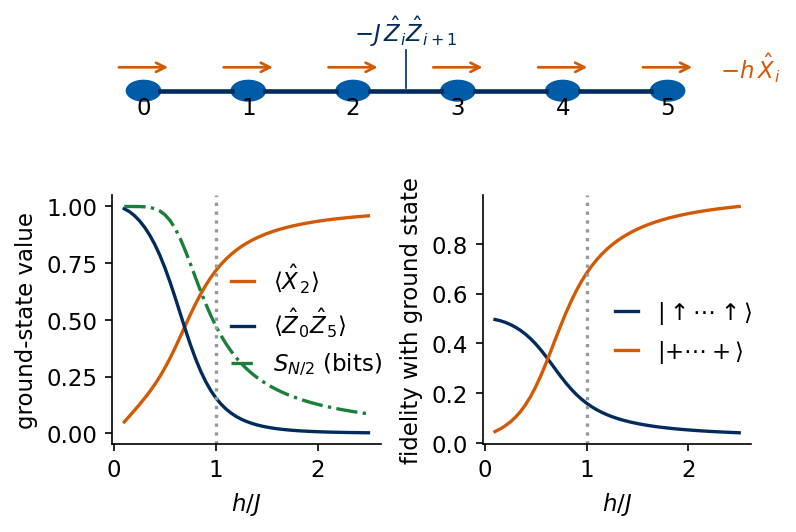

In [24]:
fig = plt.figure(figsize=(5.5, 3.6))
gs = fig.add_gridspec(2, 2, height_ratios=[0.8, 2.2], hspace=0.45, wspace=0.38)
ax0 = fig.add_subplot(gs[0, :]); ax0.set_axis_off(); ax0.set_xlim(-0.6, 11.6); ax0.set_ylim(-0.9, 2.0)
for i in range(N):
    x = 2 * i; ax0.add_patch(plt.Circle((x, 0), 0.32, color=UJBlue))
    ax0.text(x, -0.75, f"{i}", ha="center", fontsize=11)
    ax0.annotate("", xy=(x + 0.55, 0.75), xytext=(x - 0.55, 0.75), arrowprops=dict(arrowstyle="->", color=DSOrange, lw=1.3))
    if i < N - 1:
        ax0.plot([x + 0.32, x + 1.68], [0, 0], color=UJNavy, lw=2.2)
ax0.plot([5.0, 5.0], [0.08, 1.3], color=UJNavy, lw=0.8)
ax0.text(5.0, 1.35, r"$-J\,\hat Z_i\hat Z_{i+1}$", ha="center", va="bottom", fontsize=11, color=UJNavy)
ax0.text(11.0, 0.75, r"$-h\,\hat X_i$", fontsize=11, color=DSOrange, va="center")
ax1, ax2 = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
ax1.plot(h_scan, obs_scan[:, 0], color=DSOrange, label=r"$\langle\hat X_2\rangle$")
ax1.plot(h_scan, obs_scan[:, 1], color=UJNavy, label=r"$\langle\hat Z_0\hat Z_5\rangle$")
ax1.plot(h_scan, obs_scan[:, 5], color=UJGreen, ls="-.", label=r"$S_{N/2}$ (bits)")
ax1.axvline(1.0, color="0.6", ls=":"); ax1.set_xlabel("$h/J$"); ax1.set_ylabel("ground-state value"); ax1.legend(loc="center right", bbox_to_anchor=(1.08, 0.5), handlelength=1.0, fontsize=11)
ax2.plot(h_scan, obs_scan[:, 3], color=UJNavy, label=r"$|{\uparrow\cdots\uparrow}\rangle$")
ax2.plot(h_scan, obs_scan[:, 4], color=DSOrange, label=r"$|{+\cdots+}\rangle$")
ax2.axvline(1.0, color="0.6", ls=":"); ax2.set_xlabel("$h/J$"); ax2.set_ylabel("fidelity with ground state")
ax2.legend(loc="center right", bbox_to_anchor=(1.08, 0.45), handlelength=1.0, fontsize=11)
save(fig, "fig_lab054_tfim_groundstate"); plt.show()

The top of the figure sketches the chain, with bonds for the interaction and arrows for the transverse field. The lower left panel shows three properties of the TFIM ground state against $h/J$. The transverse magnetisation $\langle \hat X_2\rangle$ of the middle spin grows from zero towards one as the field takes over. The end-to-end correlation $\langle \hat Z_0\hat Z_5\rangle$ is one in the ferromagnet, where the two end spins are certainly aligned, and decays in the paramagnet. The half-chain entanglement entropy is close to one bit at small field, the entanglement of the superposition of all-up and all-down, and falls towards zero in the paramagnet, where the ground state approaches a product state. The lower right panel shows the fidelity of two product states with the ground state. The dotted line marks $h=J$.

## Matrix product states

Metz and Bukov use matrix product states (MPS) in two places. The quantum state that the agent observes is stored as an MPS, because a vector of $2^N$ amplitudes cannot be stored for long chains, and the Q-network itself contains a trainable MPS, called QMPS, which is contracted with the state. In their words this "allows us to control systems far larger than neural-network-only architectures permit". Their examples use 4, 16 and 32 spins, with a state bond dimension $\chi_\psi=16$ in the 32-spin study, and they report that agents trained on 32 spins also give reasonable protocols on 8 and 64 spins. This section explains what an MPS is and measures whether our targets would admit one.

Cut the chain into a left part $A$ (spins $0,\dots,\ell-1$) and a right part $B$. Every state can be written as a Schmidt decomposition
$$
|\psi\rangle = \sum_{k=1}^{r_{\rm S}} \mu_k\, |u_k\rangle_A\, |v_k\rangle_B ,\qquad \mu_1\ge\mu_2\ge\dots>0,\quad \sum_k\mu_k^2=1,
$$
with orthonormal states $|u_k\rangle$ of $A$ and $|v_k\rangle$ of $B$ and the Schmidt coefficients $\mu_k$. It is the singular value decomposition of the amplitudes arranged as a matrix with rows labelled by the configurations of $A$ and columns by those of $B$. A product state has a single term, $r_{\rm S}=1$. The number $r_{\rm S}$ of terms is the Schmidt rank, and the entanglement entropy of the cut is
$$
S_\ell = -\sum_k \mu_k^2\log_2\mu_k^2 \;\le\; \log_2 r_{\rm S} .
$$
Repeating the singular value decomposition at every cut, from left to right, writes the state as a chain of small tensors,
$$
\psi_{s_0s_1\cdots s_{N-1}} = M^{[0]s_0}M^{[1]s_1}\cdots M^{[N-1]s_{N-1}} ,
$$
where $M^{[j]s_j}$ is a $\chi_j\times\chi_{j+1}$ matrix for each value $s_j\in\{0,1\}$ of spin $j$. The bond dimension $\chi_j$ equals the Schmidt rank of the cut left of spin $j$. An exact MPS of $N$ spins needs bond dimension up to $2^{N/2}$, which brings back the exponential cost. The MPS becomes useful when the Schmidt coefficients decay fast, so that keeping the $\chi$ largest ones at every cut loses little. The state then needs about $2N\chi^2$ numbers instead of $2^N$, and the entropy across any cut of the truncated state is at most $\log_2\chi$.

Ground states of gapped Hamiltonians with short-range interactions in one dimension obey an area law, their entanglement entropy across a cut stays bounded as the chain grows [M. B. Hastings, J. Stat. Mech. (2007) P08024, [doi:10.1088/1742-5468/2007/08/P08024](https://doi.org/10.1088/1742-5468/2007/08/P08024); J. Eisert, M. Cramer, M. B. Plenio, Rev. Mod. Phys. **82**, 277 (2010), [doi:10.1103/RevModPhys.82.277](https://doi.org/10.1103/RevModPhys.82.277)], so a fixed small $\chi$ suffices for long chains. At a critical point the entropy grows slowly with the length. For an open chain of length $N$ cut into $\ell$ and $N-\ell$ spins, conformal field theory gives
$$
S_\ell = \frac{c}{6}\,\log\!\Big(\frac{N}{\pi a}\,\sin\frac{\pi \ell}{N}\Big) + \text{const}
$$
[P. Calabrese and J. Cardy, J. Stat. Mech. (2004) P06002, [doi:10.1088/1742-5468/2004/06/P06002](https://doi.org/10.1088/1742-5468/2004/06/P06002)], with lattice spacing $a$, the natural logarithm, and central charge $c=1/2$ for the critical transverse-field Ising chain. The required bond dimension then grows as a power of $N$, which is still affordable. A state with entropy proportional to the number of spins, a volume law, has no efficient MPS.

A two-spin example shows the Schmidt decomposition at work. The amplitudes $\psi_{s_0s_1}$ of two spins form a $2\times2$ matrix, and its singular values are the Schmidt coefficients. For the product state $|{\uparrow}\rangle|{+}\rangle$ there is one nonzero singular value and $S=0$. For the entangled state $(|{\uparrow\uparrow}\rangle+|{\downarrow\downarrow}\rangle)/\sqrt2$ there are two equal values $1/\sqrt2$ and $S=1$ bit. The cell checks both with `schmidt_values` and `entanglement_entropy`.

In [25]:
product_two = jnp.einsum("a,b->ab", jnp.array([1, 0], dtype=CDTYPE), jnp.array([1, 1], dtype=CDTYPE) / np.sqrt(2))
bell_two = ghz_state(2)
for name, psi in (("product |up>|+>", product_two), ("(|uu> + |dd>)/sqrt2", bell_two)):
    print(f"{name:22s} amplitude matrix {np.round(np.real(np.asarray(psi)).reshape(-1), 3)}, "
          f"Schmidt coefficients {np.round(np.asarray(schmidt_values(psi, (0,))), 4)}, S = {float(entanglement_entropy(psi, (0,))):.4f} bits")

product |up>|+>        amplitude matrix [0.707 0.707 0.    0.   ], Schmidt coefficients [1. 0.], S = 0.0000 bits
(|uu> + |dd>)/sqrt2    amplitude matrix [0.707 0.    0.    0.707], Schmidt coefficients [0.7071 0.7071], S = 1.0000 bits


For six spins the same decomposition is repeated at every cut. The next cell converts our targets, and for contrast the Greenberger–Horne–Zeilinger (GHZ) state $(|{\uparrow\cdots\uparrow}\rangle+|{\downarrow\cdots\downarrow}\rangle)/\sqrt2$, the W state (one spin down, shared over all sites) and a random state, into MPS with the engine functions. It checks that the exact MPS reproduces the state, then truncates to bond dimension $\chi$ and measures the fidelity of the truncated state.

In [26]:
mps_states = dict(target_states)
mps_states.update({"GHZ": ghz_state(N), "W": w_state(N), "random": haar_state(jax.random.PRNGKey(11), N)})
mps_data = {}
for name, psi in mps_states.items():
    M_list, schmidt = state_to_mps_left(psi)
    err = float(np.abs(mps_list_to_state(M_list) - np.asarray(psi)).max())
    chis = [len(s) for s in schmidt]
    fid_chi = []
    for chi in range(1, 2 ** (N // 2) + 1):
        B, lam, eps = state_to_mps(psi, chi)
        phi = mps_to_state(B)
        fid_chi.append(float(fidelity_pure(psi, phi) / jnp.vdot(phi, phi).real))
    B, lam, _ = state_to_mps(psi, 2 ** (N // 2))
    mps_data[name] = dict(schmidt_mid=schmidt[N // 2 - 1], S_profile=np.asarray(mps_entropies(lam))[1:N], chis=chis,
                          fid_chi=np.array(fid_chi))
    print(f"{name:11s}: |MPS - psi| = {err:.1e}, bond dimensions {chis}, S profile "
          f"{np.round(mps_data[name]['S_profile'], 3)}, fidelity at chi = 1, 2, 4: "
          f"{mps_data[name]['fid_chi'][0]:.4f}, {mps_data[name]['fid_chi'][1]:.4f}, {mps_data[name]['fid_chi'][3]:.4f}")
print(f"\nstorage for N = 32, chi = 16: 2 N chi^2 = {2 * 32 * 16 ** 2} numbers, 2^N = {2 ** 32:,} amplitudes")
NUMBERS.update(mps_fid_chi2_crit=float(mps_data["TFIM h=1.0"]["fid_chi"][1]),
               mps_fid_chi2_KH=float(mps_data["Kim-Huse"]["fid_chi"][1]),
               mps_fid_chi2_random=float(mps_data["random"]["fid_chi"][1]))

TFIM h=0.5 : |MPS - psi| = 1.2e-15, bond dimensions [2, 4, 8, 4, 2], S profile [0.811 0.94  0.964 0.94  0.811], fidelity at chi = 1, 2, 4: 0.2261, 0.9995, 1.0000
TFIM h=1.0 : |MPS - psi| = 1.0e-15, bond dimensions [2, 4, 8, 4, 2], S profile [0.375 0.453 0.473 0.453 0.375], fidelity at chi = 1, 2, 4: 0.6820, 0.9996, 1.0000


TFIM h=2.0 : |MPS - psi| = 4.4e-16, bond dimensions [2, 4, 8, 4, 2], S profile [0.119 0.127 0.128 0.127 0.119], fidelity at chi = 1, 2, 4: 0.9211, 1.0000, 1.0000
Kim-Huse   : |MPS - psi| = 3.3e-16, bond dimensions [2, 4, 8, 4, 2], S profile [0.281 0.422 0.394 0.422 0.281], fidelity at chi = 1, 2, 4: 0.7333, 0.9998, 1.0000
GHZ        : |MPS - psi| = 0.0e+00, bond dimensions [2, 2, 2, 2, 2], S profile [1. 1. 1. 1. 1.], fidelity at chi = 1, 2, 4: 0.5000, 1.0000, 1.0000


W          : |MPS - psi| = 2.2e-16, bond dimensions [2, 2, 2, 2, 2], S profile [0.65  0.918 1.    0.918 0.65 ], fidelity at chi = 1, 2, 4: 0.1667, 1.0000, 1.0000
random     : |MPS - psi| = 3.6e-16, bond dimensions [2, 4, 8, 4, 2], S profile [0.987 1.913 2.443 1.834 0.955], fidelity at chi = 1, 2, 4: 0.1682, 0.4433, 0.8614

storage for N = 32, chi = 16: 2 N chi^2 = 16384 numbers, 2^N = 4,294,967,296 amplitudes


Every exact MPS reproduces its state to rounding, and the bond dimensions $2,4,8,4,2$ of the targets are the largest possible for six spins. The truncation tells more. The figure shows the Schmidt spectrum at the middle cut, the truncation fidelity and the entropy profile for all seven states.

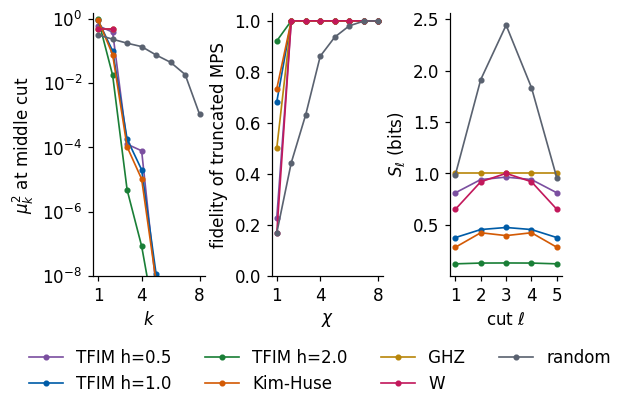

In [27]:
# one colour per target, used in every figure of the targets
TARGET_COLORS = {"TFIM h=0.5": "#7B4FA0", "TFIM h=1.0": UJBlue, "TFIM h=2.0": UJGreen, "Kim-Huse": DSOrange}
mps_colors = {**TARGET_COLORS, "GHZ": "#B8860B", "W": "#C2185B", "random": UJGray}
fig, axs = plt.subplots(1, 3, figsize=(5.5, 3.1), gridspec_kw=dict(wspace=0.6))
for name, d in mps_data.items():
    c = mps_colors[name]
    axs[0].semilogy(np.arange(1, len(d["schmidt_mid"]) + 1), d["schmidt_mid"] ** 2, "o-", ms=3, color=c, lw=1.1)
    axs[1].plot(np.arange(1, 9), d["fid_chi"], "o-", ms=3, color=c, lw=1.1, label=name)
    axs[2].plot(np.arange(1, N), d["S_profile"], "o-", ms=3, color=c, lw=1.1)
axs[0].set_xlabel("$k$"); axs[0].set_xticks([1, 4, 8]); axs[0].set_ylabel(r"$\mu_k^2$ at middle cut"); axs[0].set_ylim(1e-8, 1.5)
axs[1].set_xlabel(r"$\chi$"); axs[1].set_xticks([1, 4, 8]); axs[1].set_ylabel("fidelity of truncated MPS"); axs[1].set_ylim(0, 1.03)
axs[2].set_xlabel(r"cut $\ell$"); axs[2].set_ylabel(r"$S_\ell$ (bits)"); axs[2].set_xticks(range(1, N))
fig.legend(*axs[1].get_legend_handles_labels(), loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.06), fontsize=11)
save(fig, "fig_lab054_mps_entanglement"); plt.show()

The left panel is the Schmidt spectrum $\mu_k^2$ at the middle cut, the middle panel the fidelity of the MPS truncated to bond dimension $\chi$ and renormalised, and the right panel the entanglement entropy at every cut of the chain. The TFIM ground states have one or two large Schmidt coefficients and a fast decay, so $\chi=2$ already gives fidelities close to one. The GHZ state has two equal Schmidt coefficients at every cut, one bit of entropy, and is exact at $\chi=2$. The random state spreads its weight over all eight values and needs the full bond dimension. At six spins all of these numbers are small, so exact vectors are cheap and we use them. The measured spectra show that our targets carry far less entanglement than a random state, and low entanglement is the property on which the MPS route of Metz and Bukov relies for long chains.

The two diagrams drawn by the next cell sketch the objects. In the MPS each circle is a tensor $M^{[j]}$, the vertical leg is the physical spin index $s_j$, and the horizontal legs are the bond indices of dimension $\chi$, which are summed over. In the QMPS Q-network of Metz and Bukov the state MPS is contracted with a trainable MPS of its own bond dimension $\chi_Q$. The central tensor of the trainable MPS carries one extra open leg, so the contraction returns a feature vector of dimension $d_f$, which a small neural network turns into one Q-value per action. The contraction of two MPS costs a time proportional to $N$.

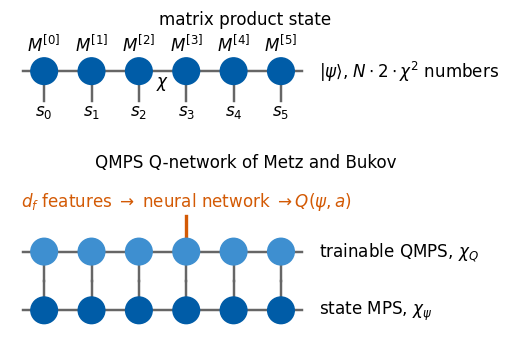

In [28]:
def draw_mps_row(ax, y, n, color, phys_up=False, extra=None, spacing=1.0, r=0.28):
    """One row of an MPS drawing: circles are tensors, the horizontal line the bonds, short vertical lines the spins."""
    xs = np.arange(n) * spacing
    ax.plot([xs[0] - 0.45, xs[-1] + 0.45], [y, y], color="0.4", lw=1.6, zorder=1)
    for x in xs:
        ax.add_patch(plt.Circle((x, y), r, color=color, zorder=3))
        ax.plot([x, x], [y, y + (0.62 if phys_up else -0.62)], color="0.4", lw=1.6, zorder=2)
    if extra is not None:
        ax.plot([xs[extra]] * 2, [y, y + 0.75], color=DSOrange, lw=2.2, zorder=2)
    return xs

fig, (a1, a2) = plt.subplots(2, 1, figsize=(5.5, 3.9), gridspec_kw=dict(height_ratios=[1, 1.5], hspace=0.25))
xs = draw_mps_row(a1, 0.0, N, UJBlue)
for j, x in enumerate(xs):
    a1.text(x, -0.92, f"$s_{j}$", ha="center", fontsize=11)
    a1.text(x, 0.42, f"$M^{{[{j}]}}$", ha="center", fontsize=11)
a1.text((xs[2] + xs[3]) / 2, -0.32, r"$\chi$", ha="center", fontsize=11)
a1.text(xs[-1] + 0.8, 0.0, r"$|\psi\rangle$, $N\cdot 2\cdot\chi^2$ numbers", va="center", fontsize=11)
a1.set_title("matrix product state", fontsize=11); a1.set_xlim(-0.7, xs[-1] + 4.2); a1.set_ylim(-1.15, 0.8)
a1.set_aspect("equal"); a1.axis("off")
xs = draw_mps_row(a2, 0.0, N, UJBlue, phys_up=True)
draw_mps_row(a2, 1.24, N, UJSky, extra=N // 2)
a2.text(xs[-1] + 0.8, 0.0, r"state MPS, $\chi_\psi$", va="center", fontsize=11)
a2.text(xs[-1] + 0.8, 1.24, r"trainable QMPS, $\chi_Q$", va="center", fontsize=11)
a2.text(xs[N // 2], 2.2, r"$d_f$ features $\to$ neural network $\to Q(\psi,a)$", fontsize=11, color=DSOrange, ha="center")
a2.set_title("QMPS Q-network of Metz and Bukov", fontsize=11, pad=16); a2.set_xlim(-0.7, xs[-1] + 4.2); a2.set_ylim(-0.5, 2.5)
a2.set_aspect("equal"); a2.axis("off")
save(fig, "fig_lab054_mps_diagrams"); plt.show()

## Control by evolution under Hamiltonian terms

The agent of Metz and Bukov does what an analog quantum simulator does natively. It switches on one term of a Hamiltonian for a short time and lets the system evolve. Its actions are
$$
\mathcal A = \Big\{e^{\pm i\,\delta_\pm \hat O}\Big\},\qquad
\hat O\in\Big\{\sum_i \hat X_i,\ \sum_i \hat Y_i,\ \sum_i \hat Z_i,\ \sum_i \hat X_i\hat X_{i+1},\ \sum_i \hat Y_i\hat Y_{i+1},\ \sum_i \hat Z_i\hat Z_{i+1}\Big\},
$$
a uniform field along $x$, $y$ or $z$, or a uniform nearest-neighbour coupling of the same three components. Each of the six terms $\hat O$ can be applied in two ways, as $e^{+i\delta_+\hat O}$ with the step $\delta_+=\pi/8$ or as $e^{-i\delta_-\hat O}$ with the step $\delta_-=\pi/13$. These are the coarse steps of the four-spin study of Metz and Bukov. Their second agent uses the fine steps $\pi/16$ and $\pi/21$. We take one half of the coarse steps, $\pi/16$ and $\pi/26$, as our fine steps, so that every action exists in a coarse and a fine version. We write the coarse evolutions as $\hat U^+_{\hat O}=e^{+i\delta_+\hat O}$ and $\hat U^-_{\hat O}=e^{-i\delta_-\hat O}$ and label them by the Pauli letters of the term, so that for example $\hat U^+_Y=e^{+i\delta_+\sum_i\hat Y_i}$ and $\hat U^-_{ZZ}=e^{-i\delta_-\sum_i\hat Z_i\hat Z_{i+1}}$. The six terms and two signs give 12 coarse actions, and with the fine versions there are 24. In the printouts of the code they appear as U+_Y, U-_ZZ for coarse steps and U+f_Y, U-f_ZZ for fine steps. The two step sizes differ for the two signs, so an action cannot be undone by the action of opposite sign, a choice that Metz and Bukov report to stabilise the training.

These are evolutions of the whole chain, applied to every spin or every bond at once. The evolution $e^{\pm i\delta\hat O}$ is the time evolution $e^{-i\hat{\mathcal H}_kt}$ under the Hamiltonian $\hat{\mathcal H}_k=\mp\hat O$ for the time $t=\delta$. All terms of one sum commute with each other, so the evolution factorises without approximation into $N$ single-spin rotations or $N-1$ two-spin rotations, each applied to the state tensor by one `einsum`. Every action function also accepts an error $\xi$ of its step, $\delta\to\delta+\xi$, which we use later to model imperfect pulses. For training it is faster to write every action as one layer of identical single-spin rotations followed by one layer of identical two-spin rotations, one of the two layers being the identity. The cell checks the actions against `exact_evolve`, checks that the step $-\delta$ undoes each of them, checks norm conservation and compares the two forms.

Our initial state is $|{\uparrow\uparrow\cdots\uparrow}\rangle$, all spins up, a classical ferromagnetic configuration. A protocol is a sequence of actions, and its quality is the fidelity of the final state with the target ground state.

In [29]:
DELTA_PLUS, DELTA_MINUS = np.pi / 8, np.pi / 13              # coarse steps
DELTA_PLUS_FINE, DELTA_MINUS_FINE = np.pi / 16, np.pi / 26    # fine steps, one half of the coarse steps
GEN_NAMES = ["X", "Y", "Z", "XX", "YY", "ZZ"]
ROT_1 = {"X": rx, "Y": ry, "Z": rz}
ROT_2 = {"XX": rxx, "YY": ryy, "ZZ": rzz}
PAULI_1 = {"X": X, "Y": Y, "Z": Z}
PAULI_2 = {"XX": XX, "YY": YY, "ZZ": ZZ}

def generator_terms(name, n):
    """The term O = sum_i P_i or sum_i P_i P_{i+1} on a chain of n spins as a list of local terms."""
    if name in PAULI_1:
        return [((i,), PAULI_1[name]) for i in range(n)]
    return [((i, i + 1), PAULI_2[name]) for i in range(n - 1)]

def make_env(n):
    """The 24 actions on a chain of n spins: exp(s i delta O) for the six terms O and both signs s, first with the
    coarse steps delta_+ = pi/8, delta_- = pi/13 (actions 0-11), then with the fine steps pi/16, pi/26 (actions 12-23).  exp(i d P) = R_P(theta) with theta = -2 d in the rotation convention of the engine.
    Every action takes an additive error xi of its step size, xi = 0 for an ideal action."""
    labels, fns, steps = [], [], []
    for (d_plus, d_minus), tag in (((DELTA_PLUS, DELTA_MINUS), ""), ((DELTA_PLUS_FINE, DELTA_MINUS_FINE), "f")):
        for s in (+1, -1):
            for g in GEN_NAMES:
                d = d_plus if s > 0 else d_minus
                def fn(psi, xi, g=g, s=s, d=d):
                    theta = -2 * s * (d + xi)
                    if g in ROT_1:
                        return apply_gates(psi, [((i,), ROT_1[g](theta)) for i in range(n)])
                    return apply_gates(psi, [((i, i + 1), ROT_2[g](theta)) for i in range(n - 1)])
                fns.append(fn); steps.append((g, s, d))
                labels.append(f"U{'+' if s > 0 else '-'}{tag}_{g}")
    # the same actions without a switch over 24 branches: every action is one layer of identical one-spin rotations
    # exp(-i theta P/2) on all spins followed by one layer of identical two-spin rotations on all bonds, one of the two
    # layers being the identity (theta = 0).  Inside vmap this costs two layers per state instead of 24 actions.
    P1 = jnp.stack([PAULI_1[g] if g in PAULI_1 else I2 for g, _, _ in steps])
    P2 = jnp.stack([PAULI_2[g] if g in PAULI_2 else jnp.eye(4, dtype=CDTYPE) for g, _, _ in steps])
    one = jnp.array([g in PAULI_1 for g, _, _ in steps]); sgn = jnp.array([s for _, s, _ in steps], float)
    dlt = jnp.array([d for _, _, d in steps])
    def apply_action(psi, a, xi=0.0):
        theta = -2 * sgn[a] * (dlt[a] + xi)
        t1, t2 = jnp.where(one[a], theta, 0.0), jnp.where(one[a], 0.0, theta)
        u = jnp.cos(t1 / 2) * I2 - 1j * jnp.sin(t1 / 2) * P1[a]
        v = jnp.cos(t2 / 2) * jnp.eye(4, dtype=CDTYPE) - 1j * jnp.sin(t2 / 2) * P2[a]
        psi = apply_gates(psi, [((i,), u) for i in range(n)])
        return apply_gates(psi, [((i, i + 1), v) for i in range(n - 1)])
    return dict(n=n, labels=labels, steps=steps, fns=fns, apply=apply_action)

ENV = {n: make_env(n) for n in (4, 6)}
N_COARSE, N_ALL = 12, 24
ACTION_LABELS = ENV[N]["labels"]

psi_test = haar_state(jax.random.PRNGKey(3), N)
for a, (g, s, d) in enumerate(ENV[N]["steps"]):
    H_k = [(q, -s * P) for q, P in generator_terms(g, N)]                 # exp(s i d O) = exp(-i H_k d)
    out = ENV[N]["fns"][a](psi_test, 0.0)
    back = ENV[N]["fns"][a](out, -2 * d)                                  # step d - 2d = -d undoes the action
    if a % 6 == 0 or a in (5, 11, 23):
        print(f"{ACTION_LABELS[a]:6s}: |gates - exact_evolve| = {float(jnp.abs(out - exact_evolve(psi_test, H_k, d)).max()):.1e}, "
              f"|U^-1 U psi - psi| = {float(jnp.abs(back - psi_test).max()):.1e}, norm {float(jnp.linalg.norm(out)):.12f}")
err_all = max(float(jnp.abs(ENV[N]["fns"][a](psi_test, 0.0) -
                            exact_evolve(psi_test, [(q, -s * P) for q, P in generator_terms(g, N)], d)).max())
              for a, (g, s, d) in enumerate(ENV[N]["steps"]))
print(f"largest deviation from exact_evolve over all {N_ALL} actions: {err_all:.1e}")
err_layer = max(float(jnp.abs(ENV[N]["apply"](psi_test, a, 0.01) - ENV[N]["fns"][a](psi_test, 0.01)).max()) for a in range(N_ALL))
print(f"largest difference between the two-layer form and the action functions (step error 0.01): {err_layer:.1e}")

U+_X  : |gates - exact_evolve| = 3.5e-16, |U^-1 U psi - psi| = 1.1e-16, norm 1.000000000000


U+_ZZ : |gates - exact_evolve| = 6.2e-17, |U^-1 U psi - psi| = 8.4e-17, norm 1.000000000000
U-_X  : |gates - exact_evolve| = 4.9e-16, |U^-1 U psi - psi| = 1.1e-16, norm 1.000000000000
U-_ZZ : |gates - exact_evolve| = 1.1e-16, |U^-1 U psi - psi| = 1.7e-16, norm 1.000000000000


U+f_X : |gates - exact_evolve| = 3.6e-16, |U^-1 U psi - psi| = 1.1e-16, norm 1.000000000000
U-f_X : |gates - exact_evolve| = 4.2e-16, |U^-1 U psi - psi| = 1.1e-16, norm 1.000000000000
U-f_ZZ: |gates - exact_evolve| = 6.2e-17, |U^-1 U psi - psi| = 1.4e-16, norm 1.000000000000


largest deviation from exact_evolve over all 24 actions: 4.9e-16


largest difference between the two-layer form and the action functions (step error 0.01): 0.0e+00


Every action agrees with the exact evolution to rounding, is undone by the opposite step, and keeps the norm. A single action from the all-up state shows what the agent sees. The cell applies $\hat U^+_Y=e^{+i\delta_+\sum_i \hat Y_i}$, a rotation of every spin about $y$, and prints the fidelity with the critical TFIM target of six spins before and after, together with the reward $r=N^{-1}\ln F$ defined below.

In [30]:
up_state = zero_state(N)
a_Y = ACTION_LABELS.index("U+_Y")
tgt_example = target_states["TFIM h=1.0"]
psi_after = ENV[N]["apply"](up_state, a_Y)
F_before, F_after = float(fidelity_pure(tgt_example, up_state)), float(fidelity_pure(tgt_example, psi_after))
print(f"F before = {F_before:.4f}, F after U+_Y = {F_after:.4f}, reward r = ln(F)/N = {np.log(F_after) / N:.4f}")
print("Bloch vector of spin 0 after U+_Y:", np.round([expect_string(psi_after, [(0, P)]) for P in (X, Y, Z)], 4))

F before = 0.1604, F after U+_Y = 0.0109, reward r = ln(F)/N = -0.7525
Bloch vector of spin 0 after U+_Y: [-0.7071  0.      0.7071]


The action $\hat U^+_Y$ turns every spin by the angle $2\delta_+=\pi/4$ about the $y$ axis towards $-x$, as the Bloch vector of spin 0 shows, and it lowers the fidelity, since the target has its transverse magnetisation along $+x$. A single action changes the fidelity strongly, so the choice of every action matters.

For short sequences the best protocol can be found by trying all of them. There are $12^n$ coarse sequences of length $n$. The cell builds all $12^5=248\,832$ states reachable from the all-up state of six spins in five coarse actions. For each of the four targets it combines them with the target propagated backwards by up to two inverse actions, which gives the best fidelity over all $12^7\approx3.6\times10^7$ sequences of length seven.

In [31]:
coarse_fns = [(lambda psi, f=f: f(psi, 0.0)) for f in ENV[N]["fns"][:N_COARSE]]
inverse_fns = [(lambda psi, f=f, d=d: f(psi, -2 * d)) for f, (_, _, d) in zip(ENV[N]["fns"][:N_COARSE], ENV[N]["steps"][:N_COARSE])]
expand = jax.jit(lambda S: jnp.concatenate([jax.vmap(f)(S) for f in coarse_fns], axis=0))       # index = a * len(S) + previous
expand_inv = jax.jit(lambda S: jnp.concatenate([jax.vmap(f)(S) for f in inverse_fns], axis=0))
t0 = time.time()
N_EXACT = 7
best_n, best_seq = {}, {}
levels = [up_state[None]]                                           # levels[n] = all states after n actions
for n in range(1, 6):
    levels.append(expand(levels[-1]))
fwd = levels[5].reshape(levels[5].shape[0], -1)
for name, tgt in target_states.items():
    best = [float(fidelity_pure(tgt, up_state))]
    for n in range(1, 6):
        Fn = np.asarray(jnp.abs(levels[n].reshape(levels[n].shape[0], -1) @ jnp.conj(tgt.reshape(-1))) ** 2)
        best.append(float(Fn.max()))
        if n == 5:                                                  # decode the best five-action sequence
            k, seq = int(Fn.argmax()), []
            for m in range(n, 0, -1):
                a, k = divmod(k, 12 ** (m - 1)); seq.append(ACTION_LABELS[a])
            best_seq[name] = seq[::-1]
    back = tgt[None]                                                # target propagated backwards by inverse actions
    for n in range(6, N_EXACT + 1):
        back = expand_inv(back); bmat = jnp.conj(back.reshape(back.shape[0], -1))
        best.append(max(float((jnp.abs(fwd @ bmat[c:c + 24].T) ** 2).max()) for c in range(0, bmat.shape[0], 24)))
    best_n[name] = np.array(best)
    print(f"{name:11s}: best F over all 12^n coarse sequences, n = 0..{N_EXACT}: {np.round(best_n[name], 4)}")
del levels, fwd
print(f"exhaustive search in {time.time() - t0:.1f} s; best 5-action sequence for TFIM h=1.0: {' '.join(best_seq['TFIM h=1.0'])}")

TFIM h=0.5 : best F over all 12^n coarse sequences, n = 0..7: [0.3982 0.4809 0.4809 0.4829 0.5051 0.545  0.6058 0.6463]


TFIM h=1.0 : best F over all 12^n coarse sequences, n = 0..7: [0.1604 0.3759 0.5808 0.6779 0.7768 0.9074 0.9271 0.9334]


TFIM h=2.0 : best F over all 12^n coarse sequences, n = 0..7: [0.0531 0.2429 0.6144 0.9064 0.9211 0.9437 0.9783 0.9907]


Kim-Huse   : best F over all 12^n coarse sequences, n = 0..7: [0.0095 0.1518 0.5246 0.6547 0.7087 0.8629 0.9047 0.9194]
exhaustive search in 7.0 s; best 5-action sequence for TFIM h=1.0: U-_YY U+_Z U-_Y U-_Y U-_Y


The exhaustive search is the reference for short protocols. With seven coarse actions the best fidelities are 0.646, 0.933, 0.991 and 0.919 for the TFIM at $h=0.5$, $1$ and $2$ and for the longitudinal-field state. Only the TFIM ground state at $h=2$, close to the product state $|{+}\cdots{+}\rangle$, comes close to one. The number of sequences grows as $12^n$, so longer protocols, other initial states or longer chains are out of reach of direct search.

## Deep Q-learning in the setting of Metz and Bukov

The agent now has to choose actions from the quantum state itself, which is what makes it react to errors. We first list the setting of Metz and Bukov as given in their paper [F. Metz and M. Bukov, Nat. Mach. Intell. **5**, 780 (2023), [doi:10.1038/s42256-023-00687-5](https://doi.org/10.1038/s42256-023-00687-5), [arXiv:2201.11790](https://arxiv.org/abs/2201.11790), Methods and Supplementary Information]. The agent observes the quantum state $|\psi_t\rangle$, stored as a matrix product state. After every action it receives the reward
$$
r_t=\frac1N\ln F_t,\qquad F_t=|\langle\psi_*|\psi_t\rangle|^2 ,
$$
the log-fidelity per spin. The logarithm avoids rewards that are exponentially small in $N$, and since every reward is negative the agent collects the least negative return by reaching the target in few steps. An episode ends when $F_t$ reaches a threshold $F^*$, or after at most 50 actions. The thresholds are quoted per spin, $F^*_{\rm sp}=(F^*)^{1/N}$. The value function $Q(\psi,a)$ is a QMPS followed by a neural network with two hidden layers of 100 to 200 units and $\tanh$ activations. It is trained by deep Q-learning [V. Mnih et al., Nature **518**, 529 (2015), [doi:10.1038/nature14236](https://doi.org/10.1038/nature14236)] with a replay buffer of 8000 transitions, batches of 32 to 64 transitions, one gradient step of the Adam optimiser after every action, a target network copied from the trained network every 10 steps, and the double Q-learning target [H. van Hasselt, A. Guez, D. Silver, Proc. AAAI Conf. Artif. Intell. **30** (2016), [doi:10.1609/aaai.v30i1.10295](https://doi.org/10.1609/aaai.v30i1.10295)]
$$
y=r+\gamma\,Q_{\bar\theta}\big(\psi',\arg\max_{a'}Q_\theta(\psi',a')\big),\qquad \gamma=0.98 ,
$$
in which the trained network $Q_\theta$ chooses the next action $a'$ and the target network $Q_{\bar\theta}$ evaluates it. Separating the choice from the evaluation reduces the overestimation of action values that a plain maximum produces. Exploration is $\epsilon$-greedy, with $\epsilon$ decaying exponentially from one to $0.01$ over 40 000 to 80 000 episodes.

The four-spin study of the paper prepares the ground state of the transverse-field Ising chain at $h=J$, the critical TFIM target of this notebook, from random initial states. Metz and Bukov state that a single agent does not reach arbitrarily high fidelities, for three reasons, the discrete action set with its fixed step sizes, the fixed maximal episode length, and the small differences between rewards close to the target, where all log-fidelities approach zero and the network cannot resolve them. They therefore train two agents. The first agent works with the steps $\pi/8$ and $\pi/13$ and the threshold $F^*_{\rm sp}=0.96$. The second agent starts from the states prepared by the first one and works with the steps $\pi/16$ and $\pi/21$ and the threshold $F^*_{\rm sp}=0.992$. For four spins these thresholds are $F^*=0.96^4\approx0.85$ and $0.992^4\approx0.97$, and the combined agents reach the second threshold within 50 steps for about 93 percent of random initial states, and for 99.5 percent when 100 steps are allowed.

Our reimplementation follows this two-agent scheme with the same single-spin thresholds, so that $F^*_1=0.96^N$ and $F^*_2=0.992^N$. The exhaustive search above shows why one agent with the coarse steps and a high threshold stalls. For the critical TFIM and the longitudinal-field targets no coarse sequence of up to seven actions reaches $F=0.94$, and a high threshold that the agent almost never meets gives it no example of success to learn from. The table lists the remaining differences.

| Item | Metz and Bukov | This notebook |
|---|---|---|
| system size | 4, 16 and 32 spins | 4 and 6 spins |
| state representation | matrix product state | exact vector of $2^N$ amplitudes |
| Q-network | QMPS and a neural network with two hidden layers, $\tanh$ | neural network with two hidden layers of 128 units on the $2\cdot2^N$ real amplitudes, ReLU |
| loss | squared error | Huber loss |
| initial states (four spins) | random product states and random reflection-symmetric states | all-up state with small random tilts |
| actions of the second agent | 12 fine actions, steps $\pi/16$, $\pi/21$ | 24 actions, the 12 coarse ones and 12 fine ones with steps $\pi/16$, $\pi/26$ |
| reward of the second agent | $N^{-1}\ln F$ | $\ln F/\lvert\ln F^*_1\rvert$ |
| target network copy | every 10 steps | every 100 steps |
| training | 40 000 to 80 000 episodes, one environment | 4000 iterations for the first agent and 20 000 ($N=4$) or 30 000 ($N=6$) for the second, each with 48 episodes in parallel |
| exploration | $\epsilon$ decays exponentially to 0.01 | $\epsilon$ decays linearly to 0.02 over half of the training |

Two of these choices address the stall directly. The second agent keeps the coarse actions next to the fine ones, so it can still make large corrections. Its reward is divided by $\lvert\ln F^*_1\rvert$ instead of $N$, which sets the reward to $-1$ at the threshold of the first agent and to $0$ at the target. The Q-values of the second agent are then of order one, and the network can resolve the small differences between states near the target, which the paper identifies as the obstacle for a single agent. This rescaling multiplies all rewards of the second agent by one constant and leaves its optimal policy unchanged.

We prepare two targets of the previous section, the critical TFIM ground state ($J=1$, $h=1$, $g=0$) and the longitudinal-field ground state ($J=-1$, $h=0.9045$, $g=0.8090$), for chains of $N=4$ and $N=6$ spins. The cell computes them by exact diagonalisation, checks the energy against Lanczos and against the expectation value $\langle\psi_*|\hat{\mathcal H}|\psi_*\rangle$ of the stored vector, and confirms that the six-spin states are those used above.

In [32]:
CTRL_TARGETS = {"TFIM h=1.0": dict(J=1.0, h=1.0, g=0.0),
                "Kim-Huse": dict(J=-1.0, h=(np.sqrt(5) + 5) / 8, g=(np.sqrt(5) + 1) / 4)}
SIZES = (4, 6)
ctrl_states, ctrl_info = {}, {}
for n in SIZES:
    for name, p in CTRL_TARGETS.items():
        terms = heisenberg_terms(n, Jxx=0.0, Jyy=0.0, Jzz=-p["J"], hx=-p["h"], hz=-p["g"])
        w, gs = ground_state_dense(terms, n)
        E_lz, _ = lanczos_ground_state(terms, n)
        e_dens = float(jnp.real(jnp.vdot(gs, apply_hamiltonian(terms, gs))))      # <H> of the stored vector
        ctrl_states[(n, name)] = gs
        ctrl_info[(n, name)] = dict(E0=float(w[0]), E_lanczos=E_lz, gap=float(w[1] - w[0]),
                                    F_init=float(fidelity_pure(gs, zero_state(n))),
                                    S_half=float(entanglement_entropy(gs, tuple(range(n // 2)))))
        i_ = ctrl_info[(n, name)]
        print(f"N = {n}, {name:11s}: E0 = {i_['E0']:.6f}, Lanczos {i_['E_lanczos']:.6f}, <H> of the vector {e_dens:.6f}, "
              f"gap {i_['gap']:.4f}, F(all-up) = {i_['F_init']:.4f}, S_N/2 = {i_['S_half']:.4f} bits")
print("the N = 6 targets agree with those used above:",
      [round(float(fidelity_pure(ctrl_states[(6, k)], target_states[k])), 12) for k in CTRL_TARGETS])

N = 4, TFIM h=1.0 : E0 = -4.758770, Lanczos -4.758770, <H> of the vector -4.758770, gap 0.6946, F(all-up) = 0.2303, S_N/2 = 0.4110 bits


N = 4, Kim-Huse   : E0 = -4.842417, Lanczos -4.842417, <H> of the vector -4.842417, gap 0.7321, F(all-up) = 0.0593, S_N/2 = 0.3987 bits


N = 6, TFIM h=1.0 : E0 = -7.296230, Lanczos -7.296230, <H> of the vector -7.296230, gap 0.4821, F(all-up) = 0.1604, S_N/2 = 0.4732 bits


N = 6, Kim-Huse   : E0 = -7.378783, Lanczos -7.378783, <H> of the vector -7.378783, gap 0.5268, F(all-up) = 0.0095, S_N/2 = 0.3941 bits
the N = 6 targets agree with those used above: [1.0, 1.0]


The fidelity of the all-up state with the target decreases with the chain length, from 0.23 to 0.16 for the TFIM and from 0.059 to 0.0095 for the longitudinal-field state, while the half-chain entanglement stays below half a bit.

The next cell defines the environment and the agent. The agent observes the $2^N$ complex amplitudes written as $2\cdot2^N$ real numbers, with the global phase fixed so that the overlap with the target is real and positive. A global phase has no physical meaning, and fixing it gives the same input for two vectors that describe the same state. A neural network maps this input to one action value $Q(\psi,a)$ per action, 12 for the first agent and 24 for the second, and the agent applies the action with the largest value. Training episodes start from the all-up state with every spin tilted away from the $z$ axis by a random angle $|\mathcal N(0,0.15)|$ in a random azimuthal direction, so that the agent meets a variety of states. The double Q-learning loss uses the Huber function, quadratic for small and linear for large differences between $Q(\psi,a)$ and its target $y$. The printout gives the layer sizes and the two thresholds for both chain lengths.

In [33]:
SIGMA_TRAIN, N_ENV = 0.15, 48
F_SP = (0.96, 0.992)                                    # single-spin thresholds of the two agents (Metz and Bukov)
T_MAX = 50                                              # actions per training episode

def tilted_state(theta, phi):
    """Product state with spin i at polar angle theta_i and azimuth phi_i on the Bloch sphere."""
    n = theta.shape[0]
    vecs = [jnp.stack([jnp.cos(theta[i] / 2), jnp.exp(1j * phi[i]) * jnp.sin(theta[i] / 2)]).astype(CDTYPE) for i in range(n)]
    return jnp.einsum(",".join(_LETTERS[i] for i in range(n)) + "->" + _LETTERS[:n], *vecs)

def tilted_states(key, m, sigma, n):
    """m all-up states of n spins, every spin tilted from +z by |N(0, sigma)| in a random azimuthal direction."""
    k1, k2 = jax.random.split(key)
    theta = jnp.abs(sigma * jax.random.normal(k1, (m, n)))
    return jax.vmap(tilted_state)(theta, 2 * jnp.pi * jax.random.uniform(k2, (m, n)))

def observe(psi, target):
    """Network input: Re and Im of the 2^N amplitudes, global phase fixed by the overlap with the target."""
    ov = jnp.vdot(target, psi)
    p = (psi * jnp.exp(-1j * jnp.angle(ov))).reshape(-1)
    return jnp.concatenate([p.real, p.imag]).astype(jnp.float32)

HIDDEN, GAMMA, LR = 128, 0.98, 5e-4
optimizer = optax.adam(LR)

def init_mlp(key, sizes):
    """He-initialised weights and zero biases of a fully connected network."""
    params = []
    for k, (m, n) in zip(jax.random.split(key, len(sizes) - 1), zip(sizes[:-1], sizes[1:])):
        params.append((jax.random.normal(k, (m, n), jnp.float32) * jnp.sqrt(2.0 / m), jnp.zeros(n, jnp.float32)))
    return params

def q_network(params, x):
    """Q-values of all actions for a batch of observations, ReLU hidden layers, linear output."""
    for W, b in params[:-1]:
        x = jax.nn.relu(x @ W + b)
    W, b = params[-1]
    return x @ W + b

def ddqn_loss(params, old_params, s, a, r, s2, done):
    """Double DQN: the online network chooses a* in s2, the target network (old copy) evaluates it."""
    a_star = jnp.argmax(q_network(params, s2), axis=1)
    q_next = jnp.take_along_axis(q_network(old_params, s2), a_star[:, None], 1)[:, 0]
    y = lax.stop_gradient(r + GAMMA * (1.0 - done) * q_next)
    q = jnp.take_along_axis(q_network(params, s), a[:, None], 1)[:, 0]
    return optax.huber_loss(q, y).mean()

LAYERS = {n: [2 * 2 ** n, HIDDEN, HIDDEN] for n in SIZES}
for n in SIZES:
    print(f"N = {n}: layers {LAYERS[n] + [N_COARSE]} (first agent), {LAYERS[n] + [N_ALL]} (second agent), "
          f"thresholds F* = {F_SP[0]}^{n} = {F_SP[0] ** n:.3f} and {F_SP[1]}^{n} = {F_SP[1] ** n:.3f}")

N = 4: layers [32, 128, 128, 12] (first agent), [32, 128, 128, 24] (second agent), thresholds F* = 0.96^4 = 0.849 and 0.992^4 = 0.968
N = 6: layers [128, 128, 128, 12] (first agent), [128, 128, 128, 24] (second agent), thresholds F* = 0.96^6 = 0.783 and 0.992^6 = 0.953


The drawing shows the network of the second agent for six spins as nodes and edges.

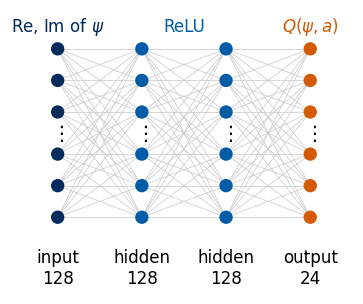

In [34]:
def draw_network(ax, sizes, labels, shown=6):
    """Nodes-and-edges drawing of a fully connected network; long layers are shown with a gap."""
    xs = np.linspace(0, 3, len(sizes)); pos = []
    for x, n in zip(xs, sizes):
        k = min(n, shown)
        ys = np.linspace(-1, 1, k) if n <= shown else np.r_[np.linspace(-1, -0.25, k // 2), np.linspace(0.25, 1, k - k // 2)]
        pos.append([(x, y) for y in ys])
    for A, B in zip(pos[:-1], pos[1:]):
        for (x0, y0) in A:
            for (x1, y1) in B:
                ax.plot([x0, x1], [y0, y1], color="0.8", lw=0.5, zorder=1)
    for j, (P, n) in enumerate(zip(pos, sizes)):
        col = UJNavy if j == 0 else (DSOrange if j == len(sizes) - 1 else UJBlue)
        for (x, y) in P:
            ax.add_patch(plt.Circle((x, y), 0.07, color=col, zorder=2))
        if n > shown:
            ax.text(P[0][0], 0.0, r"$\vdots$", ha="center", va="center", fontsize=13)
        ax.text(P[0][0], -1.38, labels[j], ha="center", va="top", fontsize=11)
    ax.set_xlim(-0.5, 3.5); ax.set_ylim(-1.9, 1.45); ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(5.5, 2.9))
draw_network(ax, LAYERS[N] + [N_ALL], ["input\n128", "hidden\n128", "hidden\n128", "output\n24"])
ax.text(0.0, 1.2, r"Re, Im of $\psi$", ha="center", fontsize=11, color=UJNavy)
ax.text(1.5, 1.2, "ReLU", ha="center", fontsize=11, color=UJBlue)
ax.text(3.0, 1.2, r"$Q(\psi,a)$", ha="center", fontsize=11, color=DSOrange)
plt.tight_layout(); save(fig, "fig_lab054_qnet"); plt.show()

The network has 128 inputs for six spins, two hidden layers of 128 units with the rectified linear unit $\mathrm{ReLU}(x)=\max(0,x)$, and one output per action. The function `train_agents` trains several agents in parallel, one per target and seed, as one compiled program. Each run keeps 48 episodes going at the same time. In every iteration each episode takes one action chosen $\epsilon$-greedily, the 48 transitions $(\psi,a,r,\psi')$ enter a replay memory of 20 000 transitions, and one gradient step of Adam with learning rate $5\times10^{-4}$ on a random batch of 64 stored transitions updates the network once the memory holds 1000 transitions. The target network is refreshed every 100 iterations. Only success makes a stored transition terminal. A training episode that reaches the limit of 50 actions is restarted, but its last transition is still bootstrapped, and the time step is absent from the input. This treats the task as continuing, a reasonable choice here because every reward is negative and the agent gains by finishing early. Finished episodes restart from new start states, either tilted all-up states or states drawn from a given pool.

In [35]:
BATCH, CAPACITY, WARMUP, TARGET_EVERY, EPS_END, CHUNK = 64, 20_000, 1_000, 100, 0.02, 2_000

def where_tree(cond, a, b):
    return jax.tree_util.tree_map(lambda x, y: jnp.where(cond, x, y), a, b)

def train_agents(n, n_act, F_star, reward_div, n_iter, keys, targets, pools=None, label=""):
    """Train len(keys) agents in parallel on a chain of n spins (one compiled program, vmapped over the runs).
    Agent r learns target targets[r] with the first n_act actions, threshold F_star and reward ln(F)/reward_div.
    Its episodes start from tilted all-up states (pools=None) or from states drawn from pools[r].
    Returns the trained parameters and, per run, (final F, length, success) of every finished training episode."""
    env, D = ENV[n], 2 * 2 ** n

    def starts(key, pool):
        if pools is None:
            return tilted_states(key, N_ENV, SIGMA_TRAIN, n)
        return pool[jax.random.randint(key, (N_ENV,), 0, pool.shape[0])]

    def init_run(key, pool):
        k0, k1, k2 = jax.random.split(key, 3)
        params = init_mlp(k0, LAYERS[n] + [n_act])
        return dict(params=params, old=params, opt=optimizer.init(params),
                    s=jnp.zeros((CAPACITY, D), jnp.float32), a=jnp.zeros(CAPACITY, jnp.int32),
                    r=jnp.zeros(CAPACITY, jnp.float32), s2=jnp.zeros((CAPACITY, D), jnp.float32),
                    d=jnp.zeros(CAPACITY, jnp.float32), m=jnp.int32(0),
                    psi=starts(k1, pool), t=jnp.zeros(N_ENV, jnp.int32), key=k2, it=jnp.int32(0))

    def iteration(c, target, pool):
        """One action in every episode, storage of the transitions, one gradient step, restart of finished episodes."""
        key, k_act, k_eps, k_batch, k_new = jax.random.split(c["key"], 5)
        eps = jnp.maximum(EPS_END, 1.0 - (1.0 - EPS_END) * c["it"] / (0.5 * n_iter))   # linear decay over half the run
        obs = jax.vmap(observe, (0, None))(c["psi"], target)
        greedy = jnp.argmax(q_network(c["params"], obs), axis=1)
        a = jnp.where(jax.random.uniform(k_eps, (N_ENV,)) < eps, jax.random.randint(k_act, (N_ENV,), 0, n_act), greedy)
        psi2 = jax.vmap(env["apply"])(c["psi"], a)
        F = jax.vmap(fidelity_pure, (None, 0))(target, psi2)
        r = (jnp.log(F) / reward_div).astype(jnp.float32)
        success = F >= F_star
        t = c["t"] + 1; finished = success | (t >= T_MAX)
        slots = (c["m"] + jnp.arange(N_ENV)) % CAPACITY
        mem = dict(s=c["s"].at[slots].set(obs), a=c["a"].at[slots].set(a.astype(jnp.int32)), r=c["r"].at[slots].set(r),
                   s2=c["s2"].at[slots].set(jax.vmap(observe, (0, None))(psi2, target)),
                   d=c["d"].at[slots].set(success.astype(jnp.float32)))
        m = c["m"] + N_ENV
        idx = jax.random.randint(k_batch, (BATCH,), 0, jnp.minimum(m, CAPACITY))
        grads = jax.grad(ddqn_loss)(c["params"], c["old"], mem["s"][idx], mem["a"][idx], mem["r"][idx], mem["s2"][idx], mem["d"][idx])
        updates, opt_new = optimizer.update(grads, c["opt"], c["params"])
        learn = m >= WARMUP
        params = where_tree(learn, optax.apply_updates(c["params"], updates), c["params"])
        opt_state = where_tree(learn, opt_new, c["opt"])
        old = where_tree(c["it"] % TARGET_EVERY == 0, params, c["old"])         # copy into the target network
        psi_next = jnp.where(finished.reshape((N_ENV,) + (1,) * n), starts(k_new, pool), psi2)
        new = dict(params=params, old=old, opt=opt_state, m=m, psi=psi_next, t=jnp.where(finished, 0, t),
                   key=key, it=c["it"] + 1, **mem)
        return new, (F, t, finished, success)

    pool_arg = jnp.zeros(len(keys)) if pools is None else pools        # placeholder when episodes start from tilted states
    carry = jax.vmap(init_run)(keys, pool_arg)
    chunk = jax.jit(jax.vmap(lambda c, tg, pl: lax.scan(lambda cc, _: iteration(cc, tg, pl), c, None, length=CHUNK)))
    log = [[] for _ in range(len(keys))]
    t0 = time.time()
    for ch in range(n_iter // CHUNK):
        carry, (F, t, fin, succ) = chunk(carry, targets, pool_arg)
        F, t, fin, succ = (np.asarray(x) for x in (F, t, fin, succ))
        for r_ in range(len(keys)):
            mk = fin[r_]
            log[r_].append(np.stack([F[r_][mk], t[r_][mk], succ[r_][mk]], 1))
        if (ch + 1) % 2 == 0 or ch == n_iter // CHUNK - 1:
            rates = [np.concatenate(l)[-300:, 2].mean() for l in log]
            print(f"{label} iteration {(ch + 1) * CHUNK:6d} ({time.time() - t0:4.0f} s): success of the last 300 "
                  "training episodes " + " ".join(f"{x:.2f}" for x in rates), flush=True)
    return carry["params"], [np.concatenate(l) for l in log], time.time() - t0

After training, the two agents act together as one controller. Before every action it computes the fidelity of the current state with the target. It stops once $F\ge F^*_2$, lets the first agent act while $F<F^*_1$ and the second agent otherwise. A large error that throws the state back below $F^*_1$ therefore hands the control back to the first agent. The function `make_controller` runs this loop for at most 100 actions, twice the training episode length, as Metz and Bukov do at test time. It can replace chosen actions by prescribed wrong ones and add Gaussian noise of width $\sigma_\xi$ to every step size. The function `make_open_loop` applies a fixed list of actions with the same errors, whatever the state does. It is the open-loop protocol of a conventional pulse sequence.

In [36]:
def make_controller(n, F1, F2, T_total):
    """Closed-loop protocol of the two trained agents on a chain of n spins.
    At every step the controller reads the state: if F >= F2 it stops, if F < F1 the first agent acts (coarse steps),
    otherwise the second agent acts (coarse and fine steps).  forced[t] >= 0 replaces the action at step t by a
    prescribed one (an error), and sigma_xi adds Gaussian noise of that width to every step size."""
    env = ENV[n]
    def run(p1, p2, target, psi0, forced, sigma_xi, key):
        last_forced = jnp.max(jnp.where(forced >= 0, jnp.arange(T_total), -1))
        def step(carry, t):
            psi, done, n_used, key = carry
            key, kx = jax.random.split(key)
            obs = observe(psi, target)
            F_now = fidelity_pure(target, psi)
            a = jnp.where(F_now < F1, jnp.argmax(q_network(p1, obs)), jnp.argmax(q_network(p2, obs)))
            a = jnp.where(forced[t] >= 0, forced[t], a)
            psi_new = jnp.where(done, psi, env["apply"](psi, a, sigma_xi * jax.random.normal(kx)))
            F = fidelity_pure(target, psi_new)
            act = jnp.where(done, -1, a)
            n_used = jnp.where(done, n_used, t + 1)
            done = done | ((F >= F2) & (t >= last_forced))
            return (psi_new, done, n_used, key), (F, act)
        done0 = (fidelity_pure(target, psi0) >= F2) & (last_forced < 0)
        (psi, done, n_used, _), (Fs, acts) = lax.scan(step, (psi0, done0, 0, key), jnp.arange(T_total))
        return jnp.concatenate([fidelity_pure(target, psi0)[None], Fs]), acts, n_used, done, psi
    return run

def make_open_loop(n):
    """A fixed action sequence applied whatever the state does (with the same errors and noise as the controller)."""
    env = ENV[n]
    def run(seq, target, psi0, forced, sigma_xi, key):
        def step(psi, x):
            a, f, k = x
            psi = env["apply"](psi, jnp.where(f >= 0, f, a), sigma_xi * jax.random.normal(k))
            return psi, fidelity_pure(target, psi)
        _, Fs = lax.scan(step, psi0, (seq, forced[:seq.shape[0]], jax.random.split(key, seq.shape[0])))
        return jnp.concatenate([fidelity_pure(target, psi0)[None], Fs])
    return run

The first agents learn the coarse part of the task, three seeds for each target and chain length.

In [37]:
DDQN_SEEDS = [0, 1, 2]
N_ITER = {1: {4: 4_000, 6: 4_000}, 2: {4: 20_000, 6: 30_000}}
RUNS = {n: [(name, s) for name in CTRL_TARGETS for s in DDQN_SEEDS] for n in SIZES}
F1 = {n: F_SP[0] ** n for n in SIZES}
F2 = {n: F_SP[1] ** n for n in SIZES}
agent1, agent2, log1, log2, t_train = {}, {}, {}, {}, {}
for n in SIZES:
    keys = jnp.stack([jax.random.PRNGKey(1000 * n + 10 * i + s) for i, (_, s) in enumerate(RUNS[n])])
    tg = jnp.stack([ctrl_states[(n, name)] for name, _ in RUNS[n]])
    agent1[n], log1[n], t_train[(1, n)] = train_agents(n, N_COARSE, F1[n], n, N_ITER[1][n], keys, tg, label=f"N = {n}, first agent ")
print("training times (s):", {f"agent {k[0]}, N = {k[1]}": round(v) for k, v in t_train.items()})

N = 4, first agent  iteration   4000 (  17 s): success of the last 300 training episodes 1.00 1.00 1.00 0.99 1.00 1.00


N = 6, first agent  iteration   4000 (  30 s): success of the last 300 training episodes 1.00 1.00 1.00 0.99 0.99 0.99


training times (s): {'agent 1, N = 4': 17, 'agent 1, N = 6': 30}


The first agents learn quickly. After 4000 iterations every run succeeds in at least 99 percent of its latest training episodes, with exploration still switched on. The second agent starts where the first one stops. The cell runs every trained first agent from 512 new tilted all-up states and keeps the states in which it reaches $F^*_1$ as the start states of the second agent.

In [38]:
def params_of(tree, i):
    return jax.tree_util.tree_map(lambda x: x[i], tree)

N_POOL, T_ONE = 512, 50
pools = {}
for n in SIZES:
    first_only = jax.jit(jax.vmap(make_controller(n, F1[n], F1[n], T_ONE), (None, None, None, 0, None, None, None)))
    pool_n = []
    for i, (name, s) in enumerate(RUNS[n]):
        p1 = params_of(agent1[n], i)
        psi0 = tilted_states(jax.random.PRNGKey(77 + i), N_POOL, SIGMA_TRAIN, n)
        Fs, acts, n_used, done, finals = first_only(p1, p1, ctrl_states[(n, name)], psi0, -jnp.ones(T_ONE, jnp.int32), 0.0,
                                                    jax.random.PRNGKey(0))
        ok = np.flatnonzero(np.asarray(done))
        pool_n.append(finals[np.random.default_rng(i).choice(ok, N_POOL)])
        print(f"N = {n}, {name:11s} seed {s}: first agent reaches F >= {F1[n]:.3f} from {len(ok)} of {N_POOL} tilted states, "
              f"mean {float(np.asarray(n_used)[ok].mean()):.1f} actions")
    pools[n] = jnp.stack(pool_n)

N = 4, TFIM h=1.0  seed 0: first agent reaches F >= 0.849 from 510 of 512 tilted states, mean 5.0 actions
N = 4, TFIM h=1.0  seed 1: first agent reaches F >= 0.849 from 512 of 512 tilted states, mean 5.0 actions


N = 4, TFIM h=1.0  seed 2: first agent reaches F >= 0.849 from 512 of 512 tilted states, mean 5.1 actions
N = 4, Kim-Huse    seed 0: first agent reaches F >= 0.849 from 512 of 512 tilted states, mean 5.8 actions


N = 4, Kim-Huse    seed 1: first agent reaches F >= 0.849 from 509 of 512 tilted states, mean 5.7 actions
N = 4, Kim-Huse    seed 2: first agent reaches F >= 0.849 from 509 of 512 tilted states, mean 5.7 actions


N = 6, TFIM h=1.0  seed 0: first agent reaches F >= 0.783 from 512 of 512 tilted states, mean 5.1 actions


N = 6, TFIM h=1.0  seed 1: first agent reaches F >= 0.783 from 512 of 512 tilted states, mean 5.4 actions


N = 6, TFIM h=1.0  seed 2: first agent reaches F >= 0.783 from 512 of 512 tilted states, mean 5.0 actions


N = 6, Kim-Huse    seed 0: first agent reaches F >= 0.783 from 511 of 512 tilted states, mean 6.9 actions


N = 6, Kim-Huse    seed 1: first agent reaches F >= 0.783 from 512 of 512 tilted states, mean 6.9 actions


N = 6, Kim-Huse    seed 2: first agent reaches F >= 0.783 from 511 of 512 tilted states, mean 6.8 actions


Every first agent reaches $F^*_1$ from at least 509 of the 512 new tilted states, with five to seven actions on average. The second agents train on these start states with all 24 actions. This is the expensive part of the notebook.

In [39]:
for n in SIZES:
    keys = jnp.stack([jax.random.PRNGKey(5000 * n + 10 * i + s) for i, (_, s) in enumerate(RUNS[n])])
    tg = jnp.stack([ctrl_states[(n, name)] for name, _ in RUNS[n]])
    agent2[n], log2[n], t_train[(2, n)] = train_agents(n, N_ALL, F2[n], abs(np.log(F1[n])), N_ITER[2][n], keys, tg,
                                                       pools=pools[n], label=f"N = {n}, second agent")
t_train_total = sum(t_train.values())
print(f"total training time {t_train_total / 60:.1f} min")

N = 4, second agent iteration   4000 (  13 s): success of the last 300 training episodes 0.00 0.00 0.00 0.00 0.00 0.00


N = 4, second agent iteration   8000 (  24 s): success of the last 300 training episodes 0.19 0.28 0.17 0.09 0.06 0.08


N = 4, second agent iteration  12000 (  36 s): success of the last 300 training episodes 0.60 0.74 0.65 0.38 0.39 0.44


N = 4, second agent iteration  16000 (  47 s): success of the last 300 training episodes 0.69 0.78 0.75 0.45 0.40 0.49


N = 4, second agent iteration  20000 (  59 s): success of the last 300 training episodes 0.79 0.77 0.73 0.41 0.42 0.61


N = 6, second agent iteration   4000 (  22 s): success of the last 300 training episodes 0.00 0.00 0.00 0.00 0.00 0.00


... (4 outputs left out)

N = 6, second agent iteration  24000 ( 122 s): success of the last 300 training episodes 0.22 0.47 0.36 0.16 0.20 0.12


N = 6, second agent iteration  28000 ( 142 s): success of the last 300 training episodes 0.16 0.49 0.38 0.03 0.26 0.26


N = 6, second agent iteration  30000 ( 152 s): success of the last 300 training episodes 0.24 0.47 0.35 0.09 0.25 0.20


total training time 4.3 min


The second task is much harder. For four spins the success rate of the training episodes stays at zero for about 4000 iterations and then rises, to between 0.73 and 0.79 for the TFIM runs and between 0.41 and 0.61 for the longitudinal-field chain runs at the end of training. For six spins the rise starts later, and the final rates are 0.24 to 0.47 for the TFIM and 0.09 to 0.25 for the longitudinal-field chain runs. The learning curves show the success rate of the training episodes, a running mean over 300 episodes, for every run.

In [40]:
# the learning curves of all runs are stored, so that the figure can be redrawn without training again
np.savez_compressed("data/lab054_fig_learning.npz", targets=np.array(list(CTRL_TARGETS)), seeds=np.array(DDQN_SEEDS),
                    **{f"agent{k}_N{n}_{name}_seed{s}": np.asarray(logs[n][i][:, 2], np.float32)
                       for k, logs in ((1, log1), (2, log2)) for n in SIZES for i, (name, s) in enumerate(RUNS[n])})

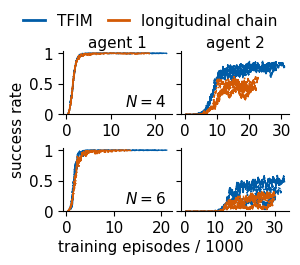

In [41]:
CTRL_COLORS = {"TFIM h=1.0": UJBlue, "Kim-Huse": DSOrange}
SEED_LS = {0: "-", 1: "--", 2: ":"}
w = 300                                                    # running mean over 300 training episodes
fd = np.load("data/lab054_fig_learning.npz")
fig, axs = plt.subplots(2, 2, figsize=(2.85, 2.55), sharey=True, layout="constrained")
fig.get_layout_engine().set(w_pad=0.02, h_pad=0.02, hspace=0.04, wspace=0.03)
for row, n in enumerate(SIZES):
    for col in (0, 1):
        ax = axs[row, col]
        for name in fd["targets"]:
            for s in fd["seeds"]:
                e = fd[f"agent{col + 1}_N{n}_{name}_seed{s}"]
                ax.plot(np.arange(w - 1, len(e)) / 1000, np.convolve(e, np.ones(w) / w, "valid"), color=CTRL_COLORS[name],
                        ls=SEED_LS[int(s)], lw=1.0)
        if row == 0:
            ax.set_title(f"agent {col + 1}", fontsize=11, pad=3)
        ax.set_ylim(0, 1.03); ax.set_yticks([0, 0.5, 1], ["0", "0.5", "1"])
        ax.xaxis.set_major_locator(mpl.ticker.MultipleLocator(10))
    axs[row, 0].text(0.95, 0.08, f"$N={n}$", transform=axs[row, 0].transAxes, ha="right", va="bottom", fontsize=11)
fig.supylabel("success rate", fontsize=11)
fig.supxlabel("training episodes / 1000", fontsize=11)
fig.legend([plt.Line2D([], [], color=c, lw=2) for c in CTRL_COLORS.values()], ["TFIM", "longitudinal chain"], loc="outside upper center",
           ncol=2, fontsize=11, handlelength=1.4, columnspacing=1.0)
save(fig, "fig_lab054_ddqn_learning"); plt.show()

The line style marks the seed and the colour the target. The horizontal axis counts finished training episodes, so a run whose episodes end early completes more of them. The first agents (left) reach a success rate close to one within a few thousand episodes for both chain lengths and both targets. The second agents (right) need several thousand episodes for four spins and about ten thousand for six spins before they succeed at all, and their success rate saturates below one. These rates are measured with $\epsilon$-greedy exploration, $\epsilon\ge0.02$, and with a budget of 50 actions per episode, so they are lower bounds for the greedy controller tested next. The longitudinal-field chain curves lie below the TFIM curves for both chain lengths, and the six-spin curves below the four-spin ones.

### Learned protocols

The cell runs the controller from the exact all-up state for every trained pair of agents. It prints whether the second threshold is reached, the number of actions, the final fidelity, the energy $\langle\psi|\hat{\mathcal H}|\psi\rangle$ of the prepared state next to the exact ground-state energy $E_0$, and the protocol itself.

In [42]:
T_EVAL = 100                                              # action budget of a protocol at test time
controller = {n: jax.jit(make_controller(n, F1[n], F2[n], T_EVAL)) for n in SIZES}
controller_batch = {n: jax.jit(jax.vmap(make_controller(n, F1[n], F2[n], T_EVAL), (None, None, None, 0, 0, None, 0))) for n in SIZES}
NO_ERRORS = -jnp.ones(T_EVAL, jnp.int32)
nominal = {}
for n in SIZES:
    terms_of = {name: heisenberg_terms(n, Jxx=0.0, Jyy=0.0, Jzz=-p["J"], hx=-p["h"], hz=-p["g"]) for name, p in CTRL_TARGETS.items()}
    for i, (name, s) in enumerate(RUNS[n]):
        tgt = ctrl_states[(n, name)]
        Fs, acts, n_used, done, psi = controller[n](params_of(agent1[n], i), params_of(agent2[n], i), tgt, zero_state(n),
                                                    NO_ERRORS, 0.0, jax.random.PRNGKey(0))
        n_used = int(n_used); seq = [int(a) for a in np.asarray(acts)[:n_used]]
        E = float(jnp.real(jnp.vdot(psi, apply_hamiltonian(terms_of[name], psi))))
        n_first = int(np.argmax(np.asarray(Fs) >= F1[n])) if (np.asarray(Fs) >= F1[n]).any() else n_used
        nominal[(n, name, s)] = dict(F=np.asarray(Fs)[:n_used + 1], seq=seq, success=bool(done), n_first=n_first,
                                     F_final=float(Fs[n_used]), E=E, E0=ctrl_info[(n, name)]["E0"])
        print(f"N = {n}, {name:11s} seed {s}: {'reaches' if done else 'misses '} F >= {F2[n]:.3f} with {n_used:2d} actions "
              f"({n_first} by the first agent), final F {float(Fs[n_used]):.4f}, energy {E:.4f} (E0 = {ctrl_info[(n, name)]['E0']:.4f})")
        print("      " + " ".join(ENV[n]["labels"][a] for a in seq))

N = 4, TFIM h=1.0  seed 0: reaches F >= 0.968 with 12 actions (5 by the first agent), final F 0.9703, energy -4.7055 (E0 = -4.7588)
      U-_Y U-_Y U-_Y U-_YY U+_X U-f_X U+f_YY U-f_YY U-f_ZZ U-f_X U+f_YY U-f_YY
N = 4, TFIM h=1.0  seed 1: reaches F >= 0.968 with 13 actions (5 by the first agent), final F 0.9716, energy -4.7002 (E0 = -4.7588)
      U-_Y U-_Y U-_Y U-_YY U+_X U-f_X U+f_YY U-f_YY U-f_Y U-f_ZZ U-f_X U+f_YY U-f_YY
N = 4, TFIM h=1.0  seed 2: reaches F >= 0.968 with 10 actions (5 by the first agent), final F 0.9688, energy -4.6592 (E0 = -4.7588)
      U-_Y U-_Y U-_Y U-_ZZ U-_X U-f_X U-f_Y U-f_X U+f_YY U-f_YY
N = 4, Kim-Huse    seed 0: reaches F >= 0.968 with 15 actions (5 by the first agent), final F 0.9730, energy -4.7741 (E0 = -4.8424)
      U-_Y U-_Y U-_Y U-_YY U-_X U+f_YY U+f_Y U-f_Y U-f_Z U+f_ZZ U-_X U-f_YY U-f_Z U+f_Z U-f_Z
N = 4, Kim-Huse    seed 1: reaches F >= 0.968 with 21 actions (5 by the first agent), final F 0.9695, energy -4.7498 (E0 = -4.8424)
      U-_Y U-_Y U-

N = 6, TFIM h=1.0  seed 0: reaches F >= 0.953 with 19 actions (5 by the first agent), final F 0.9535, energy -7.1686 (E0 = -7.2962)
      U-_Y U-_Y U-_Y U-_YY U+_X U-f_XX U-f_ZZ U-f_X U+f_YY U-f_X U-f_YY U-f_ZZ U-f_X U-f_ZZ U-f_XX U-f_ZZ U-f_X U-f_ZZ U-f_X
N = 6, TFIM h=1.0  seed 1: reaches F >= 0.953 with 19 actions (5 by the first agent), final F 0.9572, energy -7.1851 (E0 = -7.2962)
      U-_Y U-_Y U-_Y U-_ZZ U-_X U-f_X U-f_Y U-f_X U+f_YY U-f_YY U-f_ZZ U-f_X U+f_YY U-f_YY U-f_X U-f_ZZ U-f_X U+f_YY U-f_YY
N = 6, TFIM h=1.0  seed 2: reaches F >= 0.953 with 13 actions (5 by the first agent), final F 0.9571, energy -7.1642 (E0 = -7.2962)
      U-_Y U-_Y U-_Y U-_YY U+_X U-f_XX U-f_ZZ U-f_X U+f_YY U-f_X U-f_Y U-f_YY U-f_ZZ
N = 6, Kim-Huse    seed 0: misses  F >= 0.953 with 100 actions (5 by the first agent), final F 0.8824, energy -7.0385 (E0 = -7.3788)
      U-_Y U-_Y U-_Y U-_YY U-_X U+f_YY U+f_Y U-_Y U+_Y U-_Y U-f_Z U+f_ZZ U-_X U-f_Z U-f_YY U-f_Z U+f_Z U-f_Z U-f_Z U+f_Z U-f_Z U+f_Z U-f_

All six pairs of agents for four spins reach the second threshold $F^*_2=0.968$ from the exact all-up state, with 10 to 13 actions for the TFIM and 15 to 21 for the longitudinal-field ground state, and final fidelities between 0.969 and 0.973. For six spins all three TFIM pairs reach $F^*_2=0.953$, with 13 to 19 actions and final fidelities 0.954 to 0.957. For the six-spin longitudinal-field state one of the three pairs reaches the threshold, after 47 actions, and the other two end after 100 actions at $F=0.882$ and $0.908$, oscillating below the threshold. Every protocol begins with five actions of the first agent, three of them $\hat U^-_Y=e^{-i\delta_-\sum_i\hat Y_i}$, which turn every spin by $3\cdot2\pi/13\approx83^\circ$ from $z$ towards $x$, in the direction of the transverse field. The energies of the prepared states lie above the exact ground-state energies, as they must, and the fidelities are those of the states with the exact ground state. The figure shows the fidelity along one protocol for each chain length and target.

In [43]:
def shown_seed(n, name):
    """The seed with the shortest successful protocol (the first seed if none succeeds)."""
    ok = [s for s in DDQN_SEEDS if nominal[(n, name, s)]["success"]]
    return min(ok, key=lambda s: len(nominal[(n, name, s)]["seq"])) if ok else DDQN_SEEDS[0]
# for every panel the fidelity after each action and the term, sign and size of each action are stored
fd = dict(targets=np.array(list(CTRL_TARGETS)))
for n in SIZES:
    fd[f"F1_N{n}"], fd[f"F2_N{n}"] = F1[n], F2[n]
    for name in CTRL_TARGETS:
        s_ = shown_seed(n, name); nom = nominal[(n, name, s_)]; key = f"N{n}_{name}"
        fd[key + "_seed"], fd[key + "_F"] = s_, nom["F"]
        fd[key + "_term"] = np.array([ENV[n]["steps"][a][0] for a in nom["seq"]])
        fd[key + "_sign"] = np.array([ENV[n]["steps"][a][1] for a in nom["seq"]])
        fd[key + "_coarse"] = np.array([a < N_COARSE for a in nom["seq"]])
np.savez_compressed("data/lab054_fig_protocol.npz", **fd)

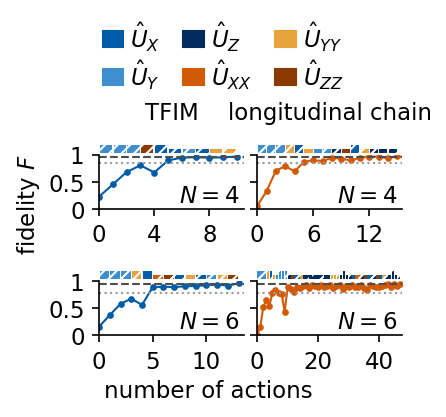

seeds shown: {'N = 4, TFIM h=1.0': 2, 'N = 4, Kim-Huse': 0, 'N = 6, TFIM h=1.0': 2, 'N = 6, Kim-Huse': 2}


In [44]:
GEN_COLORS = {"X": UJBlue, "Y": UJSky, "Z": UJNavy, "XX": DSOrange, "YY": "#e8a33d", "ZZ": "#8c3a00"}
TARGET_LABEL = {"TFIM h=1.0": "TFIM", "Kim-Huse": "longitudinal chain"}
fd = np.load("data/lab054_fig_protocol.npz")
fig, axs = plt.subplots(2, 2, figsize=(2.62, 2.68), sharey=True, layout="constrained")
fig.get_layout_engine().set(w_pad=0.02, h_pad=0.02, hspace=0.12, wspace=0.03)
for row, n in enumerate(SIZES):
    for col, name in enumerate(fd["targets"]):
        ax = axs[row, col]; key = f"N{n}_{name}"; F_ = fd[key + "_F"]
        ax.plot(np.arange(len(F_)), F_, "o-", color=CTRL_COLORS[name], ms=2.2, lw=1.0)
        ax.axhline(fd[f"F1_N{n}"], color="0.6", ls=":", lw=1.0); ax.axhline(fd[f"F2_N{n}"], color="0.3", ls="--", lw=1.0)
        for t, (g, sgn, coarse) in enumerate(zip(fd[key + "_term"], fd[key + "_sign"], fd[key + "_coarse"])):
            h_box = 0.16 if coarse else 0.08                       # tall box: coarse step, short box: fine step
            ax.add_patch(plt.Rectangle((t + 0.06, 1.03), 0.88, h_box, color=GEN_COLORS[str(g)], clip_on=False,
                                       hatch="" if sgn > 0 else "////", ec="white", lw=0))
        ax.set_xlim(0, len(F_) - 0.5); ax.set_ylim(0, 1.0); ax.set_yticks([0, 0.5, 1], ["0", "0.5", "1"])
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(3, integer=True))
        ax.text(0.97, 0.04, f"$N={n}$", transform=ax.transAxes, ha="right", va="bottom",
                fontsize=11)
        if row == 0:
            ax.set_title(TARGET_LABEL[str(name)], fontsize=11, pad=17)
fig.supylabel("fidelity $F$", fontsize=11)
fig.supxlabel("number of actions", fontsize=11)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GEN_COLORS.values()]
fig.legend(handles, [f"$\\hat U_{{{g}}}$" for g in GEN_COLORS], loc="outside upper center", ncol=3, fontsize=11,
           handlelength=0.9, handletextpad=0.3, columnspacing=1.0, labelspacing=0.2)
save(fig, "fig_lab054_ddqn_protocol"); plt.show()
print("seeds shown:", {f"N = {n}, {name}": int(fd[f"N{n}_{name}_seed"]) for n in SIZES for name in fd["targets"]})

For each chain length and target the figure shows the seed with the shortest successful protocol. The coloured boxes above each panel are the actions, with the colour giving the Hamiltonian term, a tall box a coarse step and a short box a fine step, and hatching the sign $-$ of $\hat U^-_{\hat O}$, while plain boxes are $\hat U^+_{\hat O}$. The dotted line is $F^*_1$ and the dashed line $F^*_2$. The first agent brings the fidelity above $F^*_1$ in five actions with large jumps. The second agent then raises it in small steps of both signs, and the fidelity no longer increases monotonically. For the six-spin longitudinal-field state the second agent needs many actions and the fidelity fluctuates around $0.9$ before it crosses the threshold, the oscillating behaviour that ends the two unsuccessful runs. The same controller now starts from 300 tilted all-up states drawn like the training starts.

In [45]:
gen = {}
for n in SIZES:
    psi0 = tilted_states(jax.random.PRNGKey(4242), 300, SIGMA_TRAIN, n)
    keys = jax.random.split(jax.random.PRNGKey(1), 300)
    for i, (name, s) in enumerate(RUNS[n]):
        Fs, acts, n_used, done, psi = controller_batch[n](params_of(agent1[n], i), params_of(agent2[n], i), ctrl_states[(n, name)],
                                                          psi0, jnp.tile(NO_ERRORS, (300, 1)), 0.0, keys)
        done, n_used = np.asarray(done), np.asarray(n_used)
        Ff = np.asarray(Fs)[np.arange(300), n_used]
        gen[(n, name, s)] = dict(success=done.mean(), n_mean=n_used[done].mean() if done.any() else np.nan, F_median=np.median(Ff),
                                 within50=np.mean(done & (n_used <= T_MAX)))
        print(f"N = {n}, {name:11s} seed {s}: from 300 tilted all-up states reaches F >= {F2[n]:.3f} in {done.mean():.0%} "
              f"({np.mean(done & (n_used <= T_MAX)):.0%} within {T_MAX} actions), mean {gen[(n, name, s)]['n_mean']:.1f} actions, median final F {np.median(Ff):.4f}")

N = 4, TFIM h=1.0  seed 0: from 300 tilted all-up states reaches F >= 0.968 in 83% (77% within 50 actions), mean 22.8 actions, median final F 0.9699
N = 4, TFIM h=1.0  seed 1: from 300 tilted all-up states reaches F >= 0.968 in 82% (80% within 50 actions), mean 20.0 actions, median final F 0.9703


N = 4, TFIM h=1.0  seed 2: from 300 tilted all-up states reaches F >= 0.968 in 80% (79% within 50 actions), mean 17.1 actions, median final F 0.9698


N = 4, Kim-Huse    seed 0: from 300 tilted all-up states reaches F >= 0.968 in 66% (50% within 50 actions), mean 37.9 actions, median final F 0.9692
N = 4, Kim-Huse    seed 1: from 300 tilted all-up states reaches F >= 0.968 in 31% (22% within 50 actions), mean 39.0 actions, median final F 0.9472


N = 4, Kim-Huse    seed 2: from 300 tilted all-up states reaches F >= 0.968 in 70% (53% within 50 actions), mean 37.5 actions, median final F 0.9691


N = 6, TFIM h=1.0  seed 0: from 300 tilted all-up states reaches F >= 0.953 in 31% (29% within 50 actions), mean 26.4 actions, median final F 0.9187


N = 6, TFIM h=1.0  seed 1: from 300 tilted all-up states reaches F >= 0.953 in 57% (52% within 50 actions), mean 30.1 actions, median final F 0.9536


N = 6, TFIM h=1.0  seed 2: from 300 tilted all-up states reaches F >= 0.953 in 26% (26% within 50 actions), mean 26.5 actions, median final F 0.9272


N = 6, Kim-Huse    seed 0: from 300 tilted all-up states reaches F >= 0.953 in 3% (2% within 50 actions), mean 40.1 actions, median final F 0.9119


N = 6, Kim-Huse    seed 1: from 300 tilted all-up states reaches F >= 0.953 in 16% (13% within 50 actions), mean 38.7 actions, median final F 0.9172


N = 6, Kim-Huse    seed 2: from 300 tilted all-up states reaches F >= 0.953 in 24% (16% within 50 actions), mean 45.5 actions, median final F 0.9196


From these states the four-spin TFIM controllers reach $F^*_2$ in 80 to 83 percent of the runs within 100 actions, and the four-spin longitudinal-field chain controllers in 31 to 70 percent. For six spins the success rates are 26 to 57 percent for the TFIM and 3 to 24 percent for the longitudinal-field state. Most successful runs end within the training budget of 50 actions. Metz and Bukov report 93 percent within 50 steps for four spins, from random initial states and with the QMPS network, and our four-spin TFIM controllers, with 77 to 80 percent within 50 actions, lie below the paper's 93 percent on a narrower family of initial states and with a different network. The median final fidelity of the four-spin runs lies above $F^*_2$ in five of the six cases.

### Self-correction

A fixed sequence of pulses is an open-loop protocol. It is applied in the same way whatever happens to the system. The trained agents form a closed-loop controller. They look at the current state and choose the next action from it. Metz and Bukov show for 16 spins that their agent therefore corrects errors made during the protocol. At the fifth step they replace the action of the agent by each of several other actions, which gives one protocol branch per replacement, and every branch reaches the threshold after a few extra steps. With a random action replacing the chosen one with probability 0.02 at every step, or with Gaussian noise of width 0.01 added to every step size, the agent reaches the threshold in most of their test cases, typically with longer protocols. In our simulation the agent reads the exact state vector after every action. In an experiment the state is known only through measurements or through a simulation running alongside the device, so our tests show what the agent does with full information.

We test both chain lengths, both targets and all seeds, with 100 random realisations per test. The perturbations of the initial state are tilts of the all-up state with scales $\sigma$ up to $0.4$, beyond the training scale $0.15$, and ground states of $-\sum \hat Z_i\hat Z_{i+1}-h_0\sum \hat X_i-0.1\sum \hat Z_i$ at small fields $h_0$, entangled states that never occur in training. For each test the open-loop protocol is the unperturbed protocol of the same agents from the exact all-up state, replayed action by action. A run counts as a success when the final fidelity reaches $F^*_2$. The cell also prints the fidelity of three of these nearby ground states with the all-up state.

In [46]:
open_loop_batch = {n: jax.jit(jax.vmap(make_open_loop(n), (None, None, 0, 0, None, 0))) for n in SIZES}
M_TEST = 100                                              # random realisations per test

def perturbation_test(n, name, s, psi0, forced, sigma_xi, key):
    """Run the closed-loop agents and the open-loop replay of their nominal protocol on the same perturbed problems.
    Returns success fractions (F >= F2), the number of actions of the agents and the final fidelities of both."""
    i = RUNS[n].index((name, s)); nom = nominal[(n, name, s)]; tgt = ctrl_states[(n, name)]
    keys = jax.random.split(key, psi0.shape[0])
    Fs, acts, n_used, done, _ = controller_batch[n](params_of(agent1[n], i), params_of(agent2[n], i), tgt, psi0, forced, sigma_xi, keys)
    n_used, done = np.asarray(n_used), np.asarray(done)
    F_open = np.asarray(open_loop_batch[n](jnp.asarray(nom["seq"], jnp.int32), tgt, psi0, forced, sigma_xi, keys))[:, -1]
    return dict(agent=done.mean(), open=np.mean(F_open >= F2[n]), n_agent=n_used, done=done,
                F_agent=np.asarray(Fs)[np.arange(len(n_used)), n_used], F_open=F_open, Fs=np.asarray(Fs), n_nominal=len(nom["seq"]))

def nearby_ground_state(n, h0, g0=0.1):
    """Ground state of -sum Z Z - h0 sum X - g0 sum Z: all-up for h0 = 0, the small g0 selects the up-polarised branch."""
    return ground_state_dense(heisenberg_terms(n, Jxx=0.0, Jyy=0.0, Jzz=-1.0, hx=-h0, hz=-g0), n)[1]
for h0 in (0.2, 0.4, 0.6):
    print(f"N = 6, h0 = {h0}: fidelity of the nearby ground state with all-up {float(fidelity_pure(nearby_ground_state(6, h0), zero_state(6))):.4f}")

N = 6, h0 = 0.2: fidelity of the nearby ground state with all-up 0.9745
N = 6, h0 = 0.4: fidelity of the nearby ground state with all-up 0.8991
N = 6, h0 = 0.6: fidelity of the nearby ground state with all-up 0.7777


The next cell runs the tilt scan and the nearby ground states for every chain length, target and seed.

In [47]:
SIGMAS = [0.0, 0.1, 0.2, 0.3, 0.4]
H0S = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
init_tests = {}
t0 = time.time()
for n in SIZES:
    for name in CTRL_TARGETS:
        for s in DDQN_SEEDS:
            res_sig = []
            for j, sig in enumerate(SIGMAS):
                psi0 = tilted_states(jax.random.PRNGKey(300 + j), M_TEST, sig, n)
                res_sig.append(perturbation_test(n, name, s, psi0, jnp.tile(NO_ERRORS, (M_TEST, 1)), 0.0, jax.random.PRNGKey(j)))
            psi0 = jnp.stack([nearby_ground_state(n, h0) for h0 in H0S])
            res_h = perturbation_test(n, name, s, psi0, jnp.tile(NO_ERRORS, (len(H0S), 1)), 0.0, jax.random.PRNGKey(9))
            init_tests[(n, name, s)] = dict(sig=res_sig, h=res_h)
    for name in CTRL_TARGETS:
        ag = np.array([[r["agent"] for r in init_tests[(n, name, s)]["sig"]] for s in DDQN_SEEDS])
        op = np.array([[r["open"] for r in init_tests[(n, name, s)]["sig"]] for s in DDQN_SEEDS])
        hok = np.array([init_tests[(n, name, s)]["h"]["done"] for s in DDQN_SEEDS])
        hop = np.array([init_tests[(n, name, s)]["h"]["F_open"] >= F2[n] for s in DDQN_SEEDS])
        print(f"N = {n}, {name:11s}: success over tilt scales sigma = {SIGMAS}, mean of {len(DDQN_SEEDS)} seeds")
        print(f"      agent {np.round(ag.mean(0), 2)}   fixed sequence {np.round(op.mean(0), 2)}")
        print(f"      nearby ground states h0 = {H0S}: agent succeeds in {hok.sum()} of {hok.size}, fixed sequence in {hop.sum()} of {hop.size}")
print(f"({time.time() - t0:.0f} s)")

N = 4, TFIM h=1.0 : success over tilt scales sigma = [0.0, 0.1, 0.2, 0.3, 0.4], mean of 3 seeds
      agent [1.   0.99 0.53 0.12 0.07]   fixed sequence [1.   0.23 0.02 0.   0.  ]
      nearby ground states h0 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]: agent succeeds in 16 of 18, fixed sequence in 3 of 18
N = 4, Kim-Huse   : success over tilt scales sigma = [0.0, 0.1, 0.2, 0.3, 0.4], mean of 3 seeds
      agent [1.   0.78 0.3  0.09 0.05]   fixed sequence [1.   0.28 0.07 0.   0.  ]
      nearby ground states h0 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]: agent succeeds in 14 of 18, fixed sequence in 0 of 18


N = 6, TFIM h=1.0 : success over tilt scales sigma = [0.0, 0.1, 0.2, 0.3, 0.4], mean of 3 seeds
      agent [1.   0.82 0.13 0.01 0.01]   fixed sequence [1.   0.09 0.   0.   0.  ]
      nearby ground states h0 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]: agent succeeds in 11 of 18, fixed sequence in 3 of 18
N = 6, Kim-Huse   : success over tilt scales sigma = [0.0, 0.1, 0.2, 0.3, 0.4], mean of 3 seeds
      agent [0.33 0.33 0.07 0.01 0.  ]   fixed sequence [0.33 0.06 0.   0.   0.  ]
      nearby ground states h0 = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6]: agent succeeds in 13 of 18, fixed sequence in 0 of 18
(31 s)


At $\sigma=0$ the success rate equals that of the unperturbed protocol, one for all TFIM controllers and for the four-spin longitudinal-field chain controllers and one in three for the six-spin longitudinal-field chain controllers. Already at $\sigma=0.1$ the fixed sequence fails in most runs, 9 percent success for the six-spin TFIM against 82 percent for the agents, and 23 against 99 percent for four spins. For larger tilts, beyond the training range, both drop, and at $\sigma=0.3$ the agents succeed in at most 12 percent of the runs. The nearby ground states give the clearest contrast. Over all fields $h_0$ and seeds the agents reach the target from 16 of 18 and 14 of 18 of these states for four spins (TFIM and longitudinal-field chain) and from 11 of 18 and 13 of 18 for six spins, while the fixed sequence succeeds from 3, 0, 3 and 0 of them. The agents have never seen these entangled initial states, and they still steer them to the target.

Errors during the protocol are the second test. Every run starts from the exact all-up state. In the first kind of error the actions at steps 4 to $3+m$ are replaced by $m=1$, 3 or 5 random coarse actions, after which the controller continues with its own choices and the open-loop protocol with its remaining actions. In the second kind every step size receives Gaussian noise of width $\sigma_\xi=0.01$, 0.03 or 0.05, for the controller and for the replayed protocol alike. The extra actions are counted against the unperturbed protocol, for the seeds whose unperturbed protocol reaches $F^*_2$.

In [48]:
def extra_actions(n, name, key_):
    """Mean number of additional actions of the successful perturbed runs, over the seeds whose unperturbed protocol succeeds."""
    v = [np.mean(err_tests[(n, name, s)][key_]["n_agent"][err_tests[(n, name, s)][key_]["done"]]) - len(nominal[(n, name, s)]["seq"])
         for s in DDQN_SEEDS if nominal[(n, name, s)]["success"] and err_tests[(n, name, s)][key_]["done"].any()]
    return float(np.mean(v)) if v else float("nan")

KICK_AT, N_KICKS, SIGMA_XI = 3, [1, 3, 5], [0.01, 0.03, 0.05]
err_tests = {}
t0 = time.time()
for n in SIZES:
    for name in CTRL_TARGETS:
        for s in DDQN_SEEDS:
            out = {}
            psi0 = jnp.tile(zero_state(n)[None], (M_TEST,) + (1,) * n)
            for m in N_KICKS:
                wrong = jax.random.randint(jax.random.PRNGKey(700 + m + 10 * s), (M_TEST, m), 0, N_COARSE)
                forced = jnp.tile(NO_ERRORS, (M_TEST, 1)).at[:, KICK_AT:KICK_AT + m].set(wrong)
                out[("kick", m)] = perturbation_test(n, name, s, psi0, forced, 0.0, jax.random.PRNGKey(m))
            for sx in SIGMA_XI:
                out[("noise", sx)] = perturbation_test(n, name, s, psi0, jnp.tile(NO_ERRORS, (M_TEST, 1)), sx, jax.random.PRNGKey(int(1e4 * sx)))
            err_tests[(n, name, s)] = out
for n in SIZES:
    for name in CTRL_TARGETS:
        print(f"N = {n}, {name}: success (agent / fixed sequence) and mean extra actions of the agent, mean of {len(DDQN_SEEDS)} seeds")
        for key_ in [("kick", m) for m in N_KICKS] + [("noise", sx) for sx in SIGMA_XI]:
            rs = [err_tests[(n, name, s)][key_] for s in DDQN_SEEDS]
            extra = extra_actions(n, name, key_)
            what = f"{key_[1]} random actions at step {KICK_AT + 1}" if key_[0] == "kick" else f"noise sigma = {key_[1]} on every step"
            print(f"   {what:38s}: agent {np.mean([r['agent'] for r in rs]):.2f}, fixed {np.mean([r['open'] for r in rs]):.2f}, "
                  f"extra actions {extra:+.1f}, median final F agent {np.median(np.concatenate([r['F_agent'] for r in rs])):.4f}, "
                  f"fixed {np.median(np.concatenate([r['F_open'] for r in rs])):.4f}")
print(f"({time.time() - t0:.0f} s)")

/home/marcin/anaconda3/lib/python3.13/site-packages/jax/_src/ops/scatter.py:105: FutureWarning: scatter inputs have incompatible types: cannot safely cast value from dtype=int64 to dtype=int32 with jax_numpy_dtype_promotion=standard. In future JAX releases this will result in an error.
  warnings.warn(


N = 4, TFIM h=1.0: success (agent / fixed sequence) and mean extra actions of the agent, mean of 3 seeds
   1 random actions at step 4            : agent 0.97, fixed 0.05, extra actions +4.0, median final F agent 0.9709, fixed 0.7259
   3 random actions at step 4            : agent 0.72, fixed 0.00, extra actions +12.2, median final F agent 0.9699, fixed 0.4296
   5 random actions at step 4            : agent 0.46, fixed 0.00, extra actions +17.6, median final F agent 0.9546, fixed 0.3156
   noise sigma = 0.01 on every step      : agent 1.00, fixed 0.39, extra actions +1.6, median final F agent 0.9712, fixed 0.9673
   noise sigma = 0.03 on every step      : agent 0.98, fixed 0.13, extra actions +4.6, median final F agent 0.9719, fixed 0.9502
   noise sigma = 0.05 on every step      : agent 0.97, fixed 0.04, extra actions +7.1, median final F agent 0.9715, fixed 0.9178
N = 4, Kim-Huse: success (agent / fixed sequence) and mean extra actions of the agent, mean of 3 seeds
   1 random acti

A single wrong action at step four ruins the fixed sequence, which then reaches $F^*_2$ in at most 11 percent of the runs. The agents recover in 97 and 96 percent of the runs for four spins and in 86 and 52 percent for six spins (TFIM and longitudinal-field chain), at the cost of 2.5 to 14.1 extra actions on average. With three or five wrong actions the agents still recover in a sizeable fraction of the runs, 46 and 25 percent for the six-spin TFIM, while the fixed sequence never does. Noise on every step size is the second kind of error. At $\sigma_\xi=0.05$ the fixed sequence reaches the threshold in at most 4 percent of the runs, while the agents succeed in 97 and 81 percent for four spins and in 82 and 46 percent for six spins, with up to 21 extra actions. For the six-spin longitudinal-field state the success under noise, about 50 percent, is higher than that of the unperturbed protocols, one in three, and the mean number of extra actions is negative, because the counted seed is the one whose unperturbed protocol is long. A likely reason is that the noise moves the state out of the cycle in which the agents of the other seeds are trapped. The figure collects the tests for six spins.

In [49]:
n_show, name_show, s_show, m_show = 6, "TFIM h=1.0", DDQN_SEEDS[0], 3
r_show = err_tests[(n_show, name_show, s_show)][("kick", m_show)]
nom_show = nominal[(n_show, name_show, s_show)]
F_open_traces = np.asarray(open_loop_batch[n_show](jnp.asarray(nom_show["seq"], jnp.int32), ctrl_states[(n_show, name_show)],
                                                   jnp.tile(zero_state(n_show)[None], (8,) + (1,) * n_show),
                                                   jnp.tile(NO_ERRORS, (8, 1)).at[:, KICK_AT:KICK_AT + m_show].set(
                                                       jax.random.randint(jax.random.PRNGKey(700 + m_show + 10 * s_show), (M_TEST, m_show), 0, N_COARSE)[:8]),
                                                   0.0, jax.random.split(jax.random.PRNGKey(m_show), 8)))
# eight perturbed runs of one seed, and the success rates of all six-spin tests averaged over the seeds
fd = dict(F_agent=r_show["Fs"][:8], n_agent=np.asarray(r_show["n_agent"][:8]), F_open=F_open_traces, F_nominal=nom_show["F"],
          kick_at=KICK_AT, m_show=m_show, F2=F2[n_show], targets=np.array(list(CTRL_TARGETS)),
          sigmas=np.array(SIGMAS), n_kicks=np.array(N_KICKS), sigma_xi=np.array(SIGMA_XI))
for name in CTRL_TARGETS:
    for who in ("agent", "open"):
        fd[f"{name}_sigma_{who}"] = np.mean([[r[who] for r in init_tests[(n_show, name, s)]["sig"]] for s in DDQN_SEEDS], 0)
        fd[f"{name}_kick_{who}"] = np.mean([[err_tests[(n_show, name, s)][("kick", m)][who] for m in N_KICKS] for s in DDQN_SEEDS], 0)
        fd[f"{name}_noise_{who}"] = np.mean([[err_tests[(n_show, name, s)][("noise", x)][who] for x in SIGMA_XI] for s in DDQN_SEEDS], 0)
np.savez_compressed("data/lab054_fig_robust.npz", **fd)

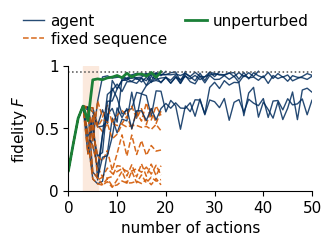

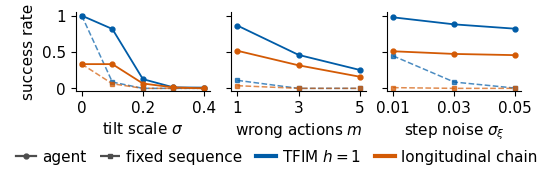

In [50]:
fd = np.load("data/lab054_fig_robust.npz")
k0, m_ = int(fd["kick_at"]), int(fd["m_show"])
fig, ax = plt.subplots(figsize=(3.2, 2.38), layout="constrained")
for k in range(len(fd["n_agent"])):
    nk = int(fd["n_agent"][k])
    ax.plot(np.arange(nk + 1), fd["F_agent"][k, :nk + 1], color=UJNavy, lw=1.0, alpha=0.85, label="agent" if k == 0 else None)
    ax.plot(np.arange(fd["F_open"].shape[1]), fd["F_open"][k], color=DSOrange, lw=1.1, ls="--", alpha=0.9,
            label="fixed sequence" if k == 0 else None)
ax.plot(np.arange(len(fd["F_nominal"])), fd["F_nominal"], color=UJGreen, lw=2.0, label="unperturbed")
ax.axvspan(k0, k0 + m_, color="#fbe9dd"); ax.axhline(float(fd["F2"]), color="0.3", ls=":", lw=1.1)
ax.set_xlabel("number of actions"); ax.set_ylabel("fidelity $F$"); ax.set_ylim(0, 1.0); ax.set_xlim(0, 50)
ax.set_yticks([0, 0.5, 1], ["0", "0.5", "1"])
fig.legend(loc="outside upper center", ncol=2, fontsize=11, handlelength=1.4, handletextpad=0.4, columnspacing=1.2, labelspacing=0.2)
save(fig, "fig_lab054_ddqn_robust_kicks"); plt.show()

from matplotlib.lines import Line2D
panels = [("tilt scale $\\sigma$", "sigmas", "sigma", [0, 0.2, 0.4]), ("wrong actions $m$", "n_kicks", "kick", [1, 3, 5]),
          ("step noise $\\sigma_\\xi$", "sigma_xi", "noise", [0.01, 0.03, 0.05])]
fig, axs = plt.subplots(1, 3, figsize=(5.15, 1.68), sharey=True, layout="constrained")
fig.get_layout_engine().set(w_pad=0.02, h_pad=0.02, wspace=0.06)
for ax, (xl, xkey, test, ticks) in zip(axs, panels):
    for name in fd["targets"]:
        ax.plot(fd[xkey], fd[f"{name}_{test}_agent"], "o-", color=CTRL_COLORS[str(name)], ms=3.5, lw=1.3)
        ax.plot(fd[xkey], fd[f"{name}_{test}_open"], "s--", color=CTRL_COLORS[str(name)], ms=3.5, lw=1.1, alpha=0.7)
    ax.set_xlabel(xl); ax.set_ylim(-0.03, 1.05); ax.set_xticks(ticks, [f"{x:g}" for x in ticks])
axs[0].set_ylabel("success rate"); axs[0].set_yticks([0, 0.5, 1], ["0", "0.5", "1"])
fig.legend([Line2D([], [], color="0.3", ls="-", marker="o", ms=3.5), Line2D([], [], color="0.3", ls="--", marker="s", ms=3.5),
            Line2D([], [], color=UJBlue, lw=3), Line2D([], [], color=DSOrange, lw=3)],
           ["agent", "fixed sequence", "TFIM $h=1$", "longitudinal chain"], loc="outside lower center", ncol=4,
           fontsize=11, handlelength=1.3, handletextpad=0.4, columnspacing=0.9)
save(fig, "fig_lab054_ddqn_robust_errors"); plt.show()

The first figure shows eight of the six-spin TFIM runs of the first seed with three random actions forced in the shaded interval. The green line is the unperturbed protocol. The fixed sequence (dashed) continues with its remaining actions and ends far below the target, at fidelities between about 0.05 and 0.7. The agent (solid) sees the damaged state, lets the first agent act again while $F<F^*_1$, and climbs back. Some runs reach the dotted threshold within about 20 actions, and the others oscillate below it until the budget of 100 actions ends, which the axis cuts at 50. The panels of the second figure average over the three seeds for both six-spin targets and give the success rates of the agents (solid) and of the fixed sequence (dashed) against the tilt scale, the number of forced wrong actions and the step noise. The agents stay above the fixed sequence in every test, which is the self-correction of Metz and Bukov at the scale of six spins. The comparison is not resource-matched. The controller computes the exact fidelity before every action, stops at the first crossing of $F^*_2$ and may use up to 100 actions. The fixed sequence is the unperturbed protocol of the same controller, which stopped at its first threshold crossing, so its unperturbed final fidelity lies only just above $F^*_2$. A small error then suffices to push it below the threshold. The median final fidelities printed above show this. With step noise $\sigma_\xi=0.01$ on four spins (TFIM) the success rates are 1.00 against 0.39, while the median final fidelities are 0.9712 against 0.9673. Success rates at a threshold without margin exaggerate the difference, and the fidelity distributions should be read alongside them.

These tests are small. The chains have four and six spins, the state is an exact vector, the network sees all amplitudes, and the target and the thresholds are fixed. Metz and Bukov work with matrix product states and chains of up to 32 spins, train on whole families of initial states, and map the QMPS agent to a hybrid quantum-classical algorithm, which they test under depolarizing noise. Their claims about scale, the control of 16 and 32 spins, the transfer of trained agents to 8 and 64 spins and the efficiency of the QMPS architecture, cannot be tested with exact vectors of a few spins. We do not train chains of $N=8$ spins. The training of the six-spin agents already takes most of the runtime of the notebook, and eight spins have four times as many amplitudes.

Some conclusions of the two papers can be checked here. For the single spin the problem is the one of Bukov et al., and the single-jump optimum below $T_c\approx0.6$, the quantum speed limit near $T=2.4$, the growth of the number of local maxima in the glass-like phase and the closeness of Q-learning to the optimum are all reproduced. For their coupled chain we see that unit fidelity is not reached up to $T=4$, while their statements on the dependence on chain length and their detailed analysis of the glassy phase are not tested here. For Metz and Bukov the need for a second agent with finer steps, the fidelity $0.992^N$ that the two agents reach from the all-up state in 10 of our 12 runs, and the correction of errors by the closed-loop agent are reproduced at four and six spins.

## Analog and digital control

Both papers control a quantum system by letting it evolve under Hamiltonians that the experiment can switch on. In the qubit and chain problems of Bukov et al. the only knob is the strength of one global field, and the protocol is its time dependence. In the problem of Metz and Bukov the knob selects which global term acts for a fixed short time. This is analog control. Each action is a native operation of the device, a laser or microwave field or a tunable coupling, and every action moves the whole many-body state at once. Gate-based control works with a set of one- and two-qubit gates on chosen qubits. Its actions are local and digital, which makes them the language of quantum computers and of circuit compilation.

The same ground states were compiled into gate sequences by a double deep Q-learning agent in the circuit compilation notebook of this course, with the gates $\hat H$, $\hat S$, $\hat T$ on any qubit and CNOT between neighbours, from the same all-up state $|0\cdots0\rangle$, with at most $2N+4$ gates and the success threshold $F=0.99$. The cell reads the stored results of that agent, checks that its targets are our targets, and prints the final fidelities and lengths of both kinds of protocol. If the stored results are missing, the cell says so and the comparison is skipped.

In [51]:
GATE_NAME = {"TFIM h=1.0": "TFI h=1", "Kim-Huse": "non-integrable"}
compare = []
try:
    with open("data/lab052_results.json") as fh:
        lab052 = json.load(fh)
except (OSError, json.JSONDecodeError):
    lab052 = None
    print("results of the gate-based agent not available")
if lab052 is not None:
    print("gate set:", ", ".join(sorted(set(g.rstrip("0123456789") for g in lab052["gate_set"]["4"]))), "on chosen qubits,",
          f"at most {lab052['n_max']['4']} gates for N = 4 and {lab052['n_max']['6']} for N = 6, success threshold {lab052['reward']['f_success']}")
    for n in SIZES:
        for name in CTRL_TARGETS:
            gname = GATE_NAME[name]
            t_ = lab052["targets"][str(n)][gname]
            v = (np.array(t_["re"]) + 1j * np.array(t_["im"])).reshape((2,) * n)
            v = jnp.asarray(v / np.linalg.norm(v), CDTYPE)
            same = float(fidelity_pure(v, ctrl_states[(n, name)]))
            rotated = apply_gates(ctrl_states[(n, name)], [((i,), Y) for i in range(n)])     # every spin rotated by pi about y
            g = lab052["results"][str(n)][f"{gname}|DDQN"]
            ana = [nominal[(n, name, s)] for s in DDQN_SEEDS]
            row = dict(n=n, name=name, overlap=same, comparable=same > 0.999, gate_F=g["F"], gate_n=g["n"],
                       analog_F=[a["F_final"] for a in ana], analog_n=[len(a["seq"]) for a in ana])
            compare.append(row)
            print(f"N = {n}, {name:11s}: |<gate target|our target>|^2 = {same:.6f}, "
                  f"with our target after a rotation of every spin by pi about y {float(fidelity_pure(v, rotated)):.6f}")
            print(f"     gates (double DQN, 3 seeds): F = {np.round(g['F'], 3)} with {g['n']} gates")
            print(f"     analog agents (3 seeds)    : F = {np.round(row['analog_F'], 3)} with {row['analog_n']} actions"
                  + ("" if row["comparable"] else "   (different target, not compared)"))

gate set: CX, H, S, T on chosen qubits, at most 12 gates for N = 4 and 16 for N = 6, success threshold 0.99
N = 4, TFIM h=1.0 : |<gate target|our target>|^2 = 1.000000, with our target after a rotation of every spin by pi about y 0.065616
     gates (double DQN, 3 seeds): F = [0.813 0.813 0.852] with [4, 4, 10] gates
     analog agents (3 seeds)    : F = [0.97  0.972 0.969] with [12, 13, 10] actions
N = 4, Kim-Huse   : |<gate target|our target>|^2 = 0.033618, with our target after a rotation of every spin by pi about y 1.000000
     gates (double DQN, 3 seeds): F = [0.589 0.741 0.741] with [12, 10, 10] gates
     analog agents (3 seeds)    : F = [0.973 0.97  0.971] with [15, 21, 16] actions   (different target, not compared)
N = 6, TFIM h=1.0 : |<gate target|our target>|^2 = 1.000000, with our target after a rotation of every spin by pi about y 0.025024
     gates (double DQN, 3 seeds): F = [0.682 0.682 0.682] with [6, 6, 6] gates
     analog agents (3 seeds)    : F = [0.954 0.957 0.95

The transverse-field targets of the two notebooks agree, with overlap one. The non-integrable target of the gate-based notebook is the same Hamiltonian with both fields reversed, $J=-1$, $h=-0.9045$, $g=-0.8090$. Reversing the fields is undone by a rotation of every spin by $\pi$ about $y$, so the two models have the same physics, but their ground states are different states, and from the all-up initial state they are different control problems. Its overlap with our longitudinal-field ground state is 0.034 for four and 0.010 for six spins, and after the rotation the overlap is one. We therefore compare only the TFIM ground state. For four spins the gate-based agents end at $F=0.813$, $0.813$ and $0.852$ after 4, 4 and 10 gates, and the analog agents at $F=0.970$, $0.972$ and $0.969$ after 12, 13 and 10 actions. For six spins the gate-based agents end at $F=0.682$ with 6 gates in all three seeds, and the analog agents at $F=0.954$, $0.957$ and $0.957$ after 19, 19 and 13 actions. The figure shows the same numbers.

In [52]:
# final fidelities and lengths of the comparable protocols, for the figure
if compare:
    np.savez_compressed("data/lab054_fig_analog_vs_gates.npz", sizes=np.array(SIZES), **{f"F2_N{n}": F2[n] for n in SIZES},
                        **{f"N{r['n']}_{k}": np.asarray(r[k]) for r in compare if r["comparable"]
                           for k in ("analog_n", "analog_F", "gate_n", "gate_F")})

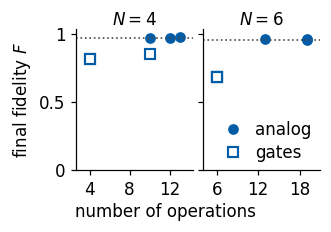

In [53]:
if compare:
    fd = np.load("data/lab054_fig_analog_vs_gates.npz")
    fig, axs = plt.subplots(1, 2, figsize=(2.85, 1.95), sharey=True, layout="constrained")
    fig.get_layout_engine().set(w_pad=0.02, h_pad=0.02, wspace=0.03)
    for ax, n in zip(axs, fd["sizes"]):
        ax.plot(fd[f"N{n}_analog_n"], fd[f"N{n}_analog_F"], "o", color=UJBlue, ms=6, label="analog")
        ax.plot(fd[f"N{n}_gate_n"], fd[f"N{n}_gate_F"], "s", color=UJBlue, ms=6, mfc="white", mew=1.4, label="gates")
        ax.axhline(float(fd[f"F2_N{n}"]), color="0.3", ls=":", lw=1.1)
        ax.set_title(f"$N={n}$", fontsize=11, pad=3); ax.set_ylim(0, 1.03); ax.set_yticks([0, 0.5, 1], ["0", "0.5", "1"])
        ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(3, integer=True)); ax.margins(x=0.15)
    axs[0].set_ylabel("final fidelity $F$")
    fig.supxlabel("number of operations", fontsize=11)
    axs[1].legend(loc="lower right", fontsize=11, handletextpad=0.3, borderaxespad=0.1, labelspacing=0.3)
    save(fig, "fig_lab054_analog_vs_gates"); plt.show()

The figure plots the final fidelity against the number of operations, actions or gates, with one point per seed, filled circles for the analog protocols, open squares for the gate sequences and the dotted line at $F^*_2$. The three gate-based points for six spins coincide, as do two of the analog ones. For the same transverse-field ground state the analog agents reach higher fidelities with more operations. The comparison counts different things. One analog action acts on every spin or every bond at once, with a step chosen from four values, while one gate acts on one or two qubits and the gate set $\hat H$, $S$, $T$, CNOT has fixed angles. The gate-based agent works with at most $2N+4$ gates and the threshold $0.99$, which it does not reach for these targets. Written as gates, one analog action is $N$ single-qubit rotations or $N-1$ two-qubit rotations with angles that are not in the gate set, so the short analog protocols correspond to long circuits of continuous rotations. The two notebooks therefore show two different trade-offs. Global native operations with a few step sizes reach the transverse-field ground state of six spins at fidelity 0.95 in 13 to 19 actions, and the discrete universal gate set with a short circuit budget stops near 0.68.

## Numbers written to file

The last cell collects the numbers quoted in the text, writes them as LaTeX macros and as a JSON file, and prints them together with the total runtime.

In [54]:
NUMBERS["runtime_s"] = time.time() - t_start
def f(x, d): return f"{x:.{d}f}"
def thin(n): return f"{n:,}".replace(",", "\\,") if abs(n) >= 10_000 else str(n)   # 20\,000, but 2000
def seeds(v, d=2): return ", ".join(f(x, d) for x in v)
def mean_over_seeds(fn): return float(np.mean([fn(s) for s in DDQN_SEEDS]))
TAG = {"TFIM h=0.5": "HHalf", "TFIM h=1.0": "HOne", "TFIM h=2.0": "HTwo", "Kim-Huse": "KimHuse"}
NTAG = {4: "Four", 6: "Six"}
macros = {
    "FinitQubit": f(NUMBERS["F_init_qubit"], 2), "NT": str(N_T), "NProtocols": thin(2 ** N_T),
    "TSingleJump": f(NUMBERS["T_single_jump_max"], 1), "TQSL": f(NUMBERS["T_QSL"], 1),
    "FbestTOne": f(NUMBERS["F_best_T1"], 3), "FbestTTwo": f(NUMBERS["F_best_T2"], 3),
    "NmaxTPointFour": str(NUMBERS["nmax_T04"]), "NmaxTTwo": thin(NUMBERS["nmax_T2"]), "NmaxTFour": thin(NUMBERS["nmax_T4"]),
    "QTPointFour": f(NUMBERS["q_T04"], 2), "QTTwoPointFour": f(NUMBERS["q_T24"], 2), "QTFour": f(NUMBERS["q_T4"], 2),
    "RLMaxGap": "{}\\times10^{{{}}}".format(*f"{NUMBERS['rl_max_gap']:.1e}".replace("e-0", "e-").split("e")), "RLFTwoPointFour": f(NUMBERS["rl_F_T24"], 4),
    "ExactFTwoPointFour": f(NUMBERS["exact_F_T24"], 4),
    "BukovChainL": str(N_CHAIN), "BukovChainNT": str(NT_CHAIN), "BukovChainFinit": f(NUMBERS["chain_F_init"], 3),
    "BukovChainFbestMax": f(NUMBERS["chain_F_best_max"], 3), "BukovChainTatMax": f(NUMBERS["chain_T_at_max"], 2),
    "ChainL": str(N), "Fstar": f(F2[N], 3), "FstarOne": f(F1[N], 3), "TmaxActions": str(T_MAX), "TEval": str(T_EVAL),
    "FspOne": f(F_SP[0], 2), "FspTwo": f(F_SP[1], 3),
    "MPSFidChiTwoCrit": f(NUMBERS["mps_fid_chi2_crit"], 4), "MPSFidChiTwoKH": f(NUMBERS["mps_fid_chi2_KH"], 4),
    "MPSFidChiTwoRandom": f(NUMBERS["mps_fid_chi2_random"], 3),
    "RuntimeMin": f(NUMBERS["runtime_s"] / 60, 1), "TrainMin": f(t_train_total / 60, 1),
    "QLEpisodes": thin(10_000), "QLAlpha": f(0.2, 1), "QLSeeds": str(len(SEEDS)),
    "HiddenWidth": str(HIDDEN), "HiddenLayers": "2",
    "NetParams": thin(sum(W.size + b.size for W, b in init_mlp(jax.random.PRNGKey(0), LAYERS[N] + [N_ALL]))),
    "Gamma": f(GAMMA, 2), "LearningRate": "5\\times10^{-4}", "TargetEvery": str(TARGET_EVERY), "EpsFinal": f(EPS_END, 2),
    "NIter": thin(N_ITER[2][N]), "NIterOne": thin(N_ITER[1][N]), "NEnv": str(N_ENV), "Batch": str(BATCH),
    "Capacity": thin(CAPACITY), "Warmup": thin(WARMUP),
    "SigmaTrain": f(SIGMA_TRAIN, 2), "DeltaPlus": "\\pi/8", "DeltaMinus": "\\pi/13", "DeltaPlusFine": "\\pi/16", "DeltaMinusFine": "\\pi/26", "NActions": str(N_COARSE), "NActionsAll": str(N_ALL),
    "DDQNSeeds": str(len(DDQN_SEEDS)), "MTest": str(M_TEST), "KickAt": str(KICK_AT + 1),
}
for name in target_states:
    t_ = TAG[name]
    macros[f"Shalf{t_}"] = f(target_info[name]["S_half"], 3); macros[f"Finit{t_}"] = f(target_info[name]["F_init"], 3)
    nmin = int(np.argmax(best_n[name] >= 0.9)) if (best_n[name] >= 0.9).any() else None
    macros[f"NminExact{t_}"] = str(nmin) if nmin is not None else "{>}" + str(N_EXACT)
    macros[f"BestNSeven{t_}"] = f(best_n[name][N_EXACT], 3)
    macros[f"Actions{t_}"] = ", ".join(str(len(nominal[(N, name, s)]["seq"])) for s in DDQN_SEEDS) if name in CTRL_TARGETS else "--"
results = dict(F_sp=F_SP, F1={n: F1[n] for n in SIZES}, F2={n: F2[n] for n in SIZES}, T_max=T_MAX, T_eval=T_EVAL, seeds=DDQN_SEEDS,
               n_iter=N_ITER, runs={})
for n in SIZES:
    macros[f"FOne{NTAG[n]}"] = f(F1[n], 3); macros[f"FTwo{NTAG[n]}"] = f(F2[n], 3)
    for name in CTRL_TARGETS:
        t_ = TAG[name] + NTAG[n]
        noms = [nominal[(n, name, s)] for s in DDQN_SEEDS]
        macros[f"Ffinal{t_}"] = seeds([x["F_final"] for x in noms], 3)
        macros[f"Nactions{t_}"] = ", ".join(str(len(x["seq"])) for x in noms)
        macros[f"Reached{t_}"] = f"{sum(x['success'] for x in noms)}/{len(noms)}"
        macros[f"GenSuccess{t_}"] = f(100 * mean_over_seeds(lambda s: gen[(n, name, s)]["success"]), 0)
        macros[f"GenWithinTmax{t_}"] = f(100 * mean_over_seeds(lambda s: gen[(n, name, s)]["within50"]), 0)
        for j, sig in enumerate(SIGMAS):
            if sig in (0.2, 0.3):
                tag = {0.2: "SigTwo", 0.3: "SigThree"}[sig]
                macros[f"Agent{tag}{t_}"] = f(100 * mean_over_seeds(lambda s: init_tests[(n, name, s)]["sig"][j]["agent"]), 0)
                macros[f"Open{tag}{t_}"] = f(100 * mean_over_seeds(lambda s: init_tests[(n, name, s)]["sig"][j]["open"]), 0)
        macros[f"NearbyAgent{t_}"] = str(sum(int(init_tests[(n, name, s)]["h"]["done"].sum()) for s in DDQN_SEEDS))
        macros[f"NearbyOpen{t_}"] = str(sum(int((init_tests[(n, name, s)]["h"]["F_open"] >= F2[n]).sum()) for s in DDQN_SEEDS))
        macros[f"NearbyTotal{t_}"] = str(len(H0S) * len(DDQN_SEEDS))
        for m in N_KICKS:
            r_ = [err_tests[(n, name, s)][("kick", m)] for s in DDQN_SEEDS]
            word = {1: "One", 3: "Three", 5: "Five"}[m]
            macros[f"Kick{word}Agent{t_}"] = f(100 * np.mean([r["agent"] for r in r_]), 0)
            macros[f"Kick{word}Open{t_}"] = f(100 * np.mean([r["open"] for r in r_]), 0)
            macros[f"Kick{word}Extra{t_}"] = f(extra_actions(n, name, ("kick", m)), 1)
        for sx in SIGMA_XI:
            r_ = [err_tests[(n, name, s)][("noise", sx)] for s in DDQN_SEEDS]
            word = {0.01: "One", 0.03: "Three", 0.05: "Five"}[sx]
            macros[f"Noise{word}Agent{t_}"] = f(100 * np.mean([r["agent"] for r in r_]), 0)
            macros[f"Noise{word}Open{t_}"] = f(100 * np.mean([r["open"] for r in r_]), 0)
        results["runs"][f"{n}|{name}"] = dict(F_final=[x["F_final"] for x in noms], n_actions=[len(x["seq"]) for x in noms],
                                             protocols=[[ENV[n]["labels"][a] for a in x["seq"]] for x in noms],
                                             success_tilted=[float(gen[(n, name, s)]["success"]) for s in DDQN_SEEDS])
        row = [r for r in compare if r["n"] == n and r["name"] == name and r["comparable"]]
        if row:
            macros[f"GateF{t_}"] = seeds(row[0]["gate_F"], 3); macros[f"GateN{t_}"] = ", ".join(str(x) for x in row[0]["gate_n"])
            results["runs"][f"{n}|{name}"].update(gate_F=row[0]["gate_F"], gate_n=row[0]["gate_n"])
# macros of the earlier version of this notebook that no longer have a counterpart
macros.update({"DDQNNnominal": macros["NactionsHOneSix"].split(",")[0], "DDQNFnominal": macros["FfinalHOneSix"].split(",")[0],
               "AgentSuccessSigThree": macros["AgentSigThreeHOneSix"], "OpenSuccessSigThree": macros["OpenSigThreeHOneSix"],
               "KickAgent": macros["KickThreeAgentHOneSix"], "KickOpen": macros["KickThreeOpenHOneSix"]})
assert all(k.isalpha() for k in macros)
with open("figures/nb_numbers_lab054.tex", "w") as fh:
    for k, v in macros.items():
        fh.write(f"\\newcommand{{\\labfiftyfour{k}}}{{{v}}}\n")
with open("data/lab054_results.json", "w") as fh:
    json.dump(json.loads(json.dumps(results, default=lambda o: o.item() if hasattr(o, "item") else str(o))), fh, indent=1)
for k, v in macros.items():
    print(f"\\labfiftyfour{k} = {v}")
print(f"\ntotal runtime {NUMBERS['runtime_s'] / 60:.1f} min")

\labfiftyfourFinitQubit = 0.20
\labfiftyfourNT = 20
\labfiftyfourNProtocols = 1\,048\,576
\labfiftyfourTSingleJump = 0.6
\labfiftyfourTQSL = 2.4
\labfiftyfourFbestTOne = 0.576
\labfiftyfourFbestTTwo = 0.953
\labfiftyfourNmaxTPointFour = 6
\labfiftyfourNmaxTTwo = 17\,984
\labfiftyfourNmaxTFour = 46\,341
\labfiftyfourQTPointFour = 0.19
\labfiftyfourQTTwoPointFour = 0.89
\labfiftyfourQTFour = 0.99
\labfiftyfourRLMaxGap = 4.3\times10^{-3}
\labfiftyfourRLFTwoPointFour = 0.9982
\labfiftyfourExactFTwoPointFour = 0.9997
\labfiftyfourBukovChainL = 6
\labfiftyfourBukovChainNT = 16
\labfiftyfourBukovChainFinit = 0.009
\labfiftyfourBukovChainFbestMax = 0.970
\labfiftyfourBukovChainTatMax = 3.25
\labfiftyfourChainL = 6
\labfiftyfourFstar = 0.953
\labfiftyfourFstarOne = 0.783
\labfiftyfourTmaxActions = 50
\labfiftyfourTEval = 100
\labfiftyfourFspOne = 0.96
\labfiftyfourFspTwo = 0.992
\labfiftyfourMPSFidChiTwoCrit = 0.9996
\labfiftyfourMPSFidChiTwoKH = 0.9998
\labfiftyfourMPSFidChiTwoRandom = 0.443
\